In [1]:
# ============================================================
# 1. Imports and academic plotting configuration
# ============================================================

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from matplotlib import font_manager

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    cohen_kappa_score,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score,
    classification_report
)

warnings.filterwarnings("ignore")

available_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT_NAME = "Times New Roman" if "Times New Roman" in available_fonts else "DejaVu Serif"

plt.rcParams.update({
    "font.family": FONT_NAME,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "axes.linewidth": 1.0,
    "lines.linewidth": 1.5,
    "figure.dpi": 120,
    "savefig.dpi": 600,
    "figure.autolayout": True
})

ACADEMIC_COLORS = {
    "navy": "#1F4E79",
    "blue": "#4C78A8",
    "teal": "#2A9D8F",
    "green": "#4E7D4E",
    "gold": "#C49A00",
    "orange": "#D97706",
    "red": "#B23A48",
    "purple": "#6C5B7B",
    "grey": "#6B7280",
    "dark_grey": "#374151"
}

MODEL_COLORS = {
    "Logistic Regression": "#1F4E79",
    "Random Forest": "#2A9D8F",
    "Extra Trees": "#C49A00",
    "HistGradientBoosting": "#B23A48"
}

STAGE_COLORS = {
    "Stable": "#4C78A8",
    "Elastic": "#59A14F",
    "Crack Development": "#E3B341",
    "Failure": "#E15759"
}

STAGE_ORDER = [
    "Stable",
    "Elastic",
    "Crack Development",
    "Failure"
]
STAGE_CODES = [0, 1, 2, 3]

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

print("Plot font:", FONT_NAME)


Plot font: Times New Roman


In [2]:
# ============================================================
# 2. Paths and fast-runtime settings
# ============================================================

# CHANGE THIS PATH
PROJECT_DIR = Path(r"C:\Users\Eddie\Desktop\new_exp_june\Project_Dir")

INPUT_FILE = (
    PROJECT_DIR /
    "failure_stage_outputs3" /
    "CNT_backfill_master_with_failure_stages.xlsx"
)

OUTPUT_DIR = PROJECT_DIR / "modeling_outputs_LOGO_RF_pub"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
TUNING_DIR = OUTPUT_DIR / "hyperparameter_tuning"
IMPORTANCE_DIR = OUTPUT_DIR / "feature_importance"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
MODEL_DIR = OUTPUT_DIR / "saved_models"

for directory in [
    OUTPUT_DIR,
    FIGURE_DIR,
    TABLE_DIR,
    TUNING_DIR,
    IMPORTANCE_DIR,
    PREDICTION_DIR,
    MODEL_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_JOBS = -1

# Maximum observations retained from each stage of each specimen.
# This reduces repeated adjacent rows and keeps nested LOGO practical.
MAX_ROWS_PER_STAGE_PER_SAMPLE = 75

# Inner grouped folds used for tuning on the outer training specimens.
INNER_GROUP_FOLDS = 3

# Fast permutation-importance setting.
PERMUTATION_REPEATS = 5

print("Input file:", INPUT_FILE)
print("Output directory:", OUTPUT_DIR)


# Individual model output folders
MODEL_OUTPUT_DIRS = {}

for model_folder_name in [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "HistGradientBoosting"
]:
    safe_model_folder = model_folder_name.replace(" ", "_")

    model_root = OUTPUT_DIR / safe_model_folder
    model_figures = model_root / "figures"
    model_tables = model_root / "tables"
    model_tuning = model_root / "hyperparameter_tuning"
    model_importance = model_root / "feature_importance"
    model_predictions = model_root / "predictions"
    model_saved = model_root / "saved_models"

    for model_directory in [
        model_root,
        model_figures,
        model_tables,
        model_tuning,
        model_importance,
        model_predictions,
        model_saved
    ]:
        model_directory.mkdir(parents=True, exist_ok=True)

    MODEL_OUTPUT_DIRS[model_folder_name] = {
        "root": model_root,
        "figures": model_figures,
        "tables": model_tables,
        "tuning": model_tuning,
        "importance": model_importance,
        "predictions": model_predictions,
        "models": model_saved
    }

print("Individual model folders created:")
for model_name, folders in MODEL_OUTPUT_DIRS.items():
    print(f"  {model_name}: {folders['root']}")


# Publication-strength analysis folders
PUBLICATION_DIR = OUTPUT_DIR / "publication_strengthening"
ABLATION_DIR = PUBLICATION_DIR / "ablation"
CI_DIR = PUBLICATION_DIR / "confidence_intervals"
STATISTICS_DIR = PUBLICATION_DIR / "statistical_tests"
ORDINAL_DIR = PUBLICATION_DIR / "ordinal_error_analysis"
THRESHOLD_DIR = PUBLICATION_DIR / "threshold_sensitivity"
ROBUSTNESS_DIR = PUBLICATION_DIR / "robustness_tests"

for directory in [
    PUBLICATION_DIR,
    ABLATION_DIR,
    CI_DIR,
    STATISTICS_DIR,
    ORDINAL_DIR,
    THRESHOLD_DIR,
    ROBUSTNESS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

BOOTSTRAP_ITERATIONS = 2000
PUBLICATION_RANDOM_STATE = RANDOM_STATE

# Use the two leading nonlinear models for expensive publication checks.
PUBLICATION_MODELS = [
    "Random Forest",
    "HistGradientBoosting"
]

# Threshold schemes for sensitivity analysis.
THRESHOLD_SCHEMES = {
    "Scheme_A_25_50_80": (0.25, 0.50, 0.80),
    "Scheme_B_30_60_85": (0.30, 0.60, 0.85),
    "Scheme_C_35_65_90": (0.35, 0.65, 0.90)
}


Input file: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\failure_stage_outputs3\CNT_backfill_master_with_failure_stages.xlsx
Output directory: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\modeling_outputs_LOGO_RF_pub
Individual model folders created:
  Logistic Regression: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\modeling_outputs_LOGO_RF_pub\Logistic_Regression
  Random Forest: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\modeling_outputs_LOGO_RF_pub\Random_Forest
  Extra Trees: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\modeling_outputs_LOGO_RF_pub\Extra_Trees
  HistGradientBoosting: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\modeling_outputs_LOGO_RF_pub\HistGradientBoosting


In [3]:
# ============================================================
# 3. Load and validate the labelled master dataset
# ============================================================

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Labelled dataset not found: {INPUT_FILE}\n"
        "Run Notebook 02 first."
    )

data = pd.read_excel(
    INPUT_FILE,
    sheet_name="Labelled_Master"
)

required_columns = [
    "Sample_ID",
    "Time_s",
    "Stress_MPa",
    "Strain",
    "AIRT_C",
    "VSMIT",
    "Failure_Stage",
    "Failure_Stage_Code"
]

missing_columns = [
    column for column in required_columns
    if column not in data.columns
]

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}\n"
        f"Available columns: {data.columns.tolist()}"
    )

for column in [
    "Time_s",
    "Stress_MPa",
    "Strain",
    "AIRT_C",
    "VSMIT",
    "Failure_Stage_Code"
]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(
    subset=[
        "Sample_ID",
        "Time_s",
        "Stress_MPa",
        "Strain",
        "AIRT_C",
        "VSMIT",
        "Failure_Stage_Code"
    ]
)

data["Failure_Stage_Code"] = data["Failure_Stage_Code"].astype(int)
data["Failure_Stage"] = pd.Categorical(
    data["Failure_Stage"],
    categories=STAGE_ORDER,
    ordered=True
)

data = data.sort_values(
    ["Sample_ID", "Time_s"]
).reset_index(drop=True)

print("Independent specimens:", data["Sample_ID"].nunique())
print("Rows before sampling:", f"{len(data):,}")
display(data.head())


Independent specimens: 80
Rows before sampling: 253,701


,Sample_ID,Observation_ID,Time_s,Test_Progress,Stress_MPa,Strain,AIRT_C,VSMIT,Peak_Stress_MPa,Peak_Position,Peak_Time_s,Stress_Ratio,Loading_Branch,Is_Peak_Row,Rows_From_Peak,Time_From_Peak_s,Failure_Stage,Failure_Stage_Code,Stage_Scheme_25_50_80,Stage_Scheme_30_60_85,Stage_Scheme_35_65_90,UCS_File,IR_File,Synchronization_Method,Curing_Day
0,G1-1,1,0.109,0.000000,0.008862,0.000003,33.031681,0.002169,10.289711,3653,407.082,0.000861,Pre-Peak,False,-3653,-406.973,Stable,0,Stable,Stable,Stable,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid,3.0
1,G1-1,2,0.218,0.000225,0.009167,0.000012,33.036082,0.002161,10.289711,3653,407.082,0.000891,Pre-Peak,False,-3652,-406.864,Stable,0,Stable,Stable,Stable,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid,3.0
2,G1-1,3,0.343,0.000483,0.009778,0.000021,33.039031,0.002182,10.289711,3653,407.082,0.000950,Pre-Peak,False,-3651,-406.739,Stable,0,Stable,Stable,Stable,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid,3.0
3,G1-1,4,0.452,0.000708,0.010084,0.000030,33.032625,0.002172,10.289711,3653,407.082,0.000980,Pre-Peak,False,-3650,-406.630,Stable,0,Stable,Stable,Stable,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid,3.0
4,G1-1,5,0.561,0.000932,0.009778,0.000039,33.027376,0.002120,10.289711,3653,407.082,0.000950,Pre-Peak,False,-3649,-406.521,Stable,0,Stable,Stable,Stable,G1-1_processed.xlsx,G1-1_AIRT_VSMIT.csv,IR interpolated onto UCS time grid,3.0


In [4]:
# ============================================================
# 4. Balanced temporal sampling within each specimen and stage
# ============================================================

def evenly_sample_group(group, maximum_rows):
    group = group.sort_values("Time_s")

    if len(group) <= maximum_rows:
        return group

    positions = np.linspace(
        0,
        len(group) - 1,
        maximum_rows,
        dtype=int
    )

    return group.iloc[np.unique(positions)]

sampled_parts = []

for (_, _), group in data.groupby(
    ["Sample_ID", "Failure_Stage_Code"],
    sort=True
):
    sampled_parts.append(
        evenly_sample_group(
            group,
            MAX_ROWS_PER_STAGE_PER_SAMPLE
        )
    )

model_data = (
    pd.concat(sampled_parts, ignore_index=True)
    .sort_values(["Sample_ID", "Time_s"])
    .reset_index(drop=True)
)

print("Rows after balanced temporal sampling:", f"{len(model_data):,}")
print("Specimens retained:", model_data["Sample_ID"].nunique())

sampling_summary = (
    model_data.groupby(
        ["Sample_ID", "Failure_Stage"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=STAGE_ORDER, fill_value=0)
)

display(sampling_summary.head())

sampling_summary.to_csv(
    TABLE_DIR / "sampling_summary_by_specimen_and_stage.csv"
)


Rows after balanced temporal sampling: 23,995
Specimens retained: 80


Failure_Stage,Stable,Elastic,Crack Development,Failure
Sample_ID,,,,
G1-1,75,75,75,75
G1-10,75,75,75,75
G1-11,75,75,75,75
G1-12,75,75,75,75
G1-13,75,75,75,75


In [5]:
# ============================================================
# 5. Feature sets and fast model grids
# ============================================================

FEATURE_SETS = {
    "Mechanical": [
        "Stress_MPa",
        "Strain"
    ],
    "Infrared": [
        "AIRT_C",
        "VSMIT"
    ],
    "Full Fusion": [
        "Stress_MPa",
        "Strain",
        "AIRT_C",
        "VSMIT"
    ],
    "Leakage-Reduced Fusion": [
        "Strain",
        "AIRT_C",
        "VSMIT"
    ]
}

MODEL_SPECS = {
    "Logistic Regression": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=1500,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                solver="lbfgs"
            ))
        ]),
        "param_grid": {
            "model__C": [0.3, 1.0, 3.0]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(
                n_estimators=180,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=N_JOBS
            ))
        ]),
        "param_grid": {
            "model__max_depth": [None, 12],
            "model__min_samples_leaf": [1, 3],
            "model__max_features": ["sqrt", None]
        }
    },

    "Extra Trees": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", ExtraTreesClassifier(
                n_estimators=180,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=N_JOBS
            ))
        ]),
        "param_grid": {
            "model__max_depth": [None, 12],
            "model__min_samples_leaf": [1, 3]
        }
    },

    "HistGradientBoosting": {
        "pipeline": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingClassifier(
                random_state=RANDOM_STATE,
                early_stopping=True
            ))
        ]),
        "param_grid": {
            "model__learning_rate": [0.05, 0.10],
            "model__max_iter": [100, 160],
            "model__max_leaf_nodes": [15, 31]
        }
    }
}

print("Feature sets:")
for feature_set, features in FEATURE_SETS.items():
    print(f"  {feature_set}: {features}")

print("\nModels:")
for model_name in MODEL_SPECS:
    print(" ", model_name)


Feature sets:
  Mechanical: ['Stress_MPa', 'Strain']
  Infrared: ['AIRT_C', 'VSMIT']
  Full Fusion: ['Stress_MPa', 'Strain', 'AIRT_C', 'VSMIT']
  Leakage-Reduced Fusion: ['Strain', 'AIRT_C', 'VSMIT']

Models:
  Logistic Regression
  Random Forest
  Extra Trees
  HistGradientBoosting


## Exact split used in every outer fold

For outer fold \(i\):

```text
Test set  = every synchronized observation from specimen i
Train set = every synchronized observation from all other specimens
```

The scaler and imputer are inside the model pipeline. Therefore:

```text
1. Fit imputer on outer-training specimens only
2. Fit scaler on outer-training specimens only
3. Tune hyperparameters using grouped folds inside outer training only
4. Refit the selected model on all outer-training specimens
5. Evaluate once on the untouched held-out specimen
```

No future row, adjacent row, or repeated observation from the held-out specimen is available to the model during training.


In [6]:
# ============================================================
# 6. Metric and importance helpers
# ============================================================

def multiclass_auc_from_probabilities(y_true, probabilities):
    """
    Returns macro and weighted one-vs-rest AUC.
    Handles folds or pooled predictions safely.
    """
    y_binary = label_binarize(
        y_true,
        classes=STAGE_CODES
    )

    valid_auc = []
    class_weights = []

    for class_index, class_code in enumerate(STAGE_CODES):
        binary_target = y_binary[:, class_index]

        if np.unique(binary_target).size < 2:
            continue

        class_auc = roc_auc_score(
            binary_target,
            probabilities[:, class_index]
        )
        valid_auc.append(class_auc)
        class_weights.append(binary_target.sum())

    if not valid_auc:
        return np.nan, np.nan

    macro_auc = float(np.mean(valid_auc))
    weighted_auc = float(
        np.average(
            valid_auc,
            weights=np.maximum(class_weights, 1)
        )
    )

    return macro_auc, weighted_auc


def calculate_metrics(y_true, y_pred, probabilities=None):
    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        ),
        "Macro_Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen_Kappa": cohen_kappa_score(y_true, y_pred)
    }

    if probabilities is not None:
        macro_auc, weighted_auc = multiclass_auc_from_probabilities(
            y_true,
            probabilities
        )
        metrics["Macro_ROC_AUC_OVR"] = macro_auc
        metrics["Weighted_ROC_AUC_OVR"] = weighted_auc
    else:
        metrics["Macro_ROC_AUC_OVR"] = np.nan
        metrics["Weighted_ROC_AUC_OVR"] = np.nan

    return metrics


def native_feature_importance(fitted_pipeline, feature_names):
    model = fitted_pipeline.named_steps["model"]

    if hasattr(model, "feature_importances_"):
        values = np.asarray(model.feature_importances_, dtype=float)
        method = "Native tree importance"

    elif hasattr(model, "coef_"):
        coefficients = np.asarray(model.coef_, dtype=float)
        values = np.mean(np.abs(coefficients), axis=0)
        method = "Mean absolute standardized coefficient"

    else:
        return None, None

    result = pd.DataFrame({
        "Feature": feature_names,
        "Importance": values
    })

    total = result["Importance"].sum()
    result["Normalized_Importance"] = (
        result["Importance"] / total
        if total > 0
        else 0.0
    )

    return result, method


def get_inner_cv(train_groups):
    unique_groups = np.unique(train_groups)
    n_splits = min(
        INNER_GROUP_FOLDS,
        len(unique_groups)
    )

    if n_splits < 2:
        raise ValueError(
            "At least two training specimens are required."
        )

    return GroupKFold(n_splits=n_splits)


def save_figure(fig, filename, model_name=None):
    """
    Save comparison figures in the main figures folder and
    model-specific figures in the corresponding model folder.
    """
    target_directory = (
        MODEL_OUTPUT_DIRS[model_name]["figures"]
        if model_name is not None
        else FIGURE_DIR
    )

    fig.savefig(
        target_directory / f"{filename}.png",
        bbox_inches="tight"
    )
    fig.savefig(
        target_directory / f"{filename}.tiff",
        bbox_inches="tight"
    )


In [7]:
# ============================================================
# 7. Nested leave-one-specimen-out training and testing
# ============================================================

y_all = model_data["Failure_Stage_Code"].to_numpy()
groups_all = model_data["Sample_ID"].astype(str).to_numpy()

outer_cv = LeaveOneGroupOut()

fold_metrics_records = []
prediction_records = []
tuning_records = []
native_importance_records = []
permutation_importance_records = []
runtime_records = []

total_tasks = len(FEATURE_SETS) * len(MODEL_SPECS)
task_number = 0

for feature_set_name, feature_names in FEATURE_SETS.items():
    X_all = model_data[feature_names].copy()

    for model_name, model_spec in MODEL_SPECS.items():
        task_number += 1
        task_start = time.time()

        print(
            f"\n[{task_number}/{total_tasks}] "
            f"{feature_set_name} | {model_name}"
        )

        for fold_number, (train_index, test_index) in enumerate(
            outer_cv.split(
                X_all,
                y_all,
                groups_all
            ),
            start=1
        ):
            X_train = X_all.iloc[train_index]
            X_test = X_all.iloc[test_index]

            y_train = y_all[train_index]
            y_test = y_all[test_index]

            train_groups = groups_all[train_index]
            held_out_sample = groups_all[test_index][0]

            # Explicit leakage checks
            assert held_out_sample not in set(train_groups)
            assert set(groups_all[test_index]) == {held_out_sample}

            inner_cv = get_inner_cv(train_groups)

            search = GridSearchCV(
                estimator=clone(model_spec["pipeline"]),
                param_grid=model_spec["param_grid"],
                scoring="f1_macro",
                cv=inner_cv,
                n_jobs=N_JOBS,
                refit=True,
                return_train_score=False,
                error_score="raise"
            )

            search.fit(
                X_train,
                y_train,
                groups=train_groups
            )

            best_model = search.best_estimator_
            y_pred = best_model.predict(X_test)
            probabilities = best_model.predict_proba(X_test)

            fold_metrics = calculate_metrics(
                y_test,
                y_pred,
                probabilities
            )

            fold_metrics_records.append({
                "Feature_Set": feature_set_name,
                "Model": model_name,
                "Fold": fold_number,
                "Held_Out_Sample": held_out_sample,
                "Train_Specimens": len(np.unique(train_groups)),
                "Test_Specimens": 1,
                "Train_Rows": len(train_index),
                "Test_Rows": len(test_index),
                "Best_Inner_Macro_F1": search.best_score_,
                **fold_metrics
            })

            tuning_record = {
                "Feature_Set": feature_set_name,
                "Model": model_name,
                "Fold": fold_number,
                "Held_Out_Sample": held_out_sample,
                "Best_Inner_Macro_F1": search.best_score_,
                **search.best_params_
            }
            tuning_records.append(tuning_record)

            tuning_detail = pd.DataFrame(search.cv_results_)
            tuning_detail.insert(0, "Held_Out_Sample", held_out_sample)
            tuning_detail.insert(0, "Fold", fold_number)
            tuning_detail.insert(0, "Model", model_name)
            tuning_detail.insert(0, "Feature_Set", feature_set_name)

            safe_feature = feature_set_name.replace(" ", "_").replace("-", "_")
            safe_model = model_name.replace(" ", "_")

            tuning_detail.to_csv(
                MODEL_OUTPUT_DIRS[model_name]["tuning"] /
                f"tuning_{safe_feature}_fold_{fold_number:03d}.csv",
                index=False
            )

            tuning_detail.to_excel(
                MODEL_OUTPUT_DIRS[model_name]["tuning"] /
                f"tuning_{safe_feature}_fold_{fold_number:03d}.xlsx",
                index=False
            )

            for local_position, global_index in enumerate(test_index):
                record = {
                    "Feature_Set": feature_set_name,
                    "Model": model_name,
                    "Fold": fold_number,
                    "Sample_ID": groups_all[global_index],
                    "Row_Index": int(global_index),
                    "Time_s": model_data.iloc[global_index]["Time_s"],
                    "True_Code": int(y_test[local_position]),
                    "Predicted_Code": int(y_pred[local_position]),
                    "True_Stage": STAGE_ORDER[int(y_test[local_position])],
                    "Predicted_Stage": STAGE_ORDER[int(y_pred[local_position])]
                }

                for class_index, stage_name in enumerate(STAGE_ORDER):
                    record[f"Probability_{stage_name}"] = float(
                        probabilities[local_position, class_index]
                    )

                prediction_records.append(record)

            native_importance, native_method = native_feature_importance(
                best_model,
                feature_names
            )

            if native_importance is not None:
                native_importance["Feature_Set"] = feature_set_name
                native_importance["Model"] = model_name
                native_importance["Fold"] = fold_number
                native_importance["Held_Out_Sample"] = held_out_sample
                native_importance["Method"] = native_method

                native_importance_records.extend(
                    native_importance.to_dict("records")
                )

            permutation = permutation_importance(
                best_model,
                X_test,
                y_test,
                scoring="balanced_accuracy",
                n_repeats=PERMUTATION_REPEATS,
                random_state=RANDOM_STATE,
                n_jobs=N_JOBS
            )

            for feature, mean_value, std_value in zip(
                feature_names,
                permutation.importances_mean,
                permutation.importances_std
            ):
                permutation_importance_records.append({
                    "Feature_Set": feature_set_name,
                    "Model": model_name,
                    "Fold": fold_number,
                    "Held_Out_Sample": held_out_sample,
                    "Feature": feature,
                    "Permutation_Importance_Mean": mean_value,
                    "Permutation_Importance_SD": std_value
                })

            if fold_number % 10 == 0:
                print(
                    f"  completed {fold_number}/"
                    f"{model_data['Sample_ID'].nunique()} outer folds"
                )

        runtime_records.append({
            "Feature_Set": feature_set_name,
            "Model": model_name,
            "Runtime_Seconds": time.time() - task_start
        })



[1/16] Mechanical | Logistic Regression
  completed 10/80 outer folds
  completed 20/80 outer folds
  completed 30/80 outer folds
  completed 40/80 outer folds
  completed 50/80 outer folds
  completed 60/80 outer folds
  completed 70/80 outer folds
  completed 80/80 outer folds

[2/16] Mechanical | Random Forest
  completed 10/80 outer folds
  completed 20/80 outer folds
  completed 30/80 outer folds
  completed 40/80 outer folds
  completed 50/80 outer folds
  completed 60/80 outer folds
  completed 70/80 outer folds
  completed 80/80 outer folds

[3/16] Mechanical | Extra Trees
  completed 10/80 outer folds
  completed 20/80 outer folds
  completed 30/80 outer folds
  completed 40/80 outer folds
  completed 50/80 outer folds
  completed 60/80 outer folds
  completed 70/80 outer folds
  completed 80/80 outer folds

[4/16] Mechanical | HistGradientBoosting


  File "c:\Users\Eddie\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Eddie\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Eddie\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Eddie\anaconda3\Lib\subprocess.

  completed 10/80 outer folds
  completed 20/80 outer folds
  completed 30/80 outer folds
  completed 40/80 outer folds
  completed 50/80 outer folds
  completed 60/80 outer folds
  completed 70/80 outer folds
  completed 80/80 outer folds

[5/16] Infrared | Logistic Regression
  completed 10/80 outer folds
  completed 20/80 outer folds
  completed 30/80 outer folds
  completed 40/80 outer folds
  completed 50/80 outer folds
  completed 60/80 outer folds
  completed 70/80 outer folds
  completed 80/80 outer folds

[6/16] Infrared | Random Forest
  completed 10/80 outer folds
  completed 20/80 outer folds
  completed 30/80 outer folds
  completed 40/80 outer folds
  completed 50/80 outer folds
  completed 60/80 outer folds
  completed 70/80 outer folds
  completed 80/80 outer folds

[7/16] Infrared | Extra Trees
  completed 10/80 outer folds
  completed 20/80 outer folds
  completed 30/80 outer folds
  completed 40/80 outer folds
  completed 50/80 outer folds
  completed 60/80 outer fol

In [8]:
# ============================================================
# 8. Assemble predictions and compute pooled LOGO metrics
# ============================================================

fold_metrics = pd.DataFrame(fold_metrics_records)
predictions = pd.DataFrame(prediction_records)
tuning_summary = pd.DataFrame(tuning_records)
native_importance_all = pd.DataFrame(native_importance_records)
permutation_importance_all = pd.DataFrame(
    permutation_importance_records
)
runtime_summary = pd.DataFrame(runtime_records)

overall_records = []
classification_reports = []

for (feature_set, model_name), group in predictions.groupby(
    ["Feature_Set", "Model"]
):
    y_true = group["True_Code"].to_numpy()
    y_pred = group["Predicted_Code"].to_numpy()

    probability_columns = [
        f"Probability_{stage}"
        for stage in STAGE_ORDER
    ]
    probabilities = group[probability_columns].to_numpy()

    metrics = calculate_metrics(
        y_true,
        y_pred,
        probabilities
    )

    overall_records.append({
        "Feature_Set": feature_set,
        "Model": model_name,
        "Observations": len(group),
        "Specimens": group["Sample_ID"].nunique(),
        **metrics
    })

    report = classification_report(
        y_true,
        y_pred,
        labels=STAGE_CODES,
        target_names=STAGE_ORDER,
        output_dict=True,
        zero_division=0
    )

    report_df = (
        pd.DataFrame(report)
        .T
        .reset_index()
        .rename(columns={"index": "Class"})
    )
    report_df.insert(0, "Model", model_name)
    report_df.insert(0, "Feature_Set", feature_set)
    classification_reports.append(report_df)

overall_metrics = (
    pd.DataFrame(overall_records)
    .sort_values(
        ["Feature_Set", "Macro_F1"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

classification_report_table = pd.concat(
    classification_reports,
    ignore_index=True
)

display(overall_metrics)


,Feature_Set,Model,Observations,Specimens,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall,MCC,Cohen_Kappa,Macro_ROC_AUC_OVR,Weighted_ROC_AUC_OVR
0,Full Fusion,HistGradientBoosting,23995,80,0.668556,0.668562,0.661449,0.661444,0.658523,0.668562,0.559327,0.558076,0.879026,0.879023
1,Full Fusion,Random Forest,23995,80,0.666597,0.666605,0.658676,0.658671,0.655807,0.666605,0.556940,0.555465,0.889998,0.889995
2,Full Fusion,Extra Trees,23995,80,0.659346,0.659348,0.651882,0.651880,0.652007,0.659348,0.548099,0.545795,0.876789,0.876787
3,Full Fusion,Logistic Regression,23995,80,0.628089,0.628096,0.621554,0.621550,0.619651,0.628096,0.505616,0.504121,0.857359,0.857355
4,Infrared,Random Forest,23995,80,0.246760,0.246772,0.241550,0.241539,0.245717,0.246772,-0.004374,-0.004313,0.501477,0.501474
5,Infrared,HistGradientBoosting,23995,80,0.246718,0.246731,0.241210,0.241199,0.244575,0.246731,-0.004425,-0.004368,0.495101,0.495097
6,Infrared,Extra Trees,23995,80,0.246676,0.246695,0.240702,0.240689,0.244389,0.246695,-0.004478,-0.004418,0.499520,0.499516
7,Infrared,Logistic Regression,23995,80,0.250302,0.250349,0.225604,0.225581,0.248079,0.250349,0.000490,0.000461,0.505770,0.505768
8,Leakage-Reduced Fusion,HistGradientBoosting,23995,80,0.562034,0.562052,0.554318,0.554305,0.550433,0.562052,0.417016,0.416049,0.797696,0.797687
9,Leakage-Reduced Fusion,Random Forest,23995,80,0.555074,0.555097,0.547993,0.547975,0.545300,0.555097,0.407933,0.406770,0.801712,0.801701


In [9]:
# ============================================================
# 9. Save metrics, tuning, predictions and split audit
# ============================================================

fold_metrics.to_csv(
    TABLE_DIR / "LOGO_fold_metrics.csv",
    index=False
)
overall_metrics.to_csv(
    TABLE_DIR / "LOGO_overall_model_metrics.csv",
    index=False
)
classification_report_table.to_csv(
    TABLE_DIR / "classification_reports.csv",
    index=False
)
predictions.to_csv(
    PREDICTION_DIR / "LOGO_all_predictions_with_probabilities.csv",
    index=False
)
tuning_summary.to_csv(
    TUNING_DIR / "LOGO_selected_hyperparameters.csv",
    index=False
)
runtime_summary.to_csv(
    TABLE_DIR / "model_runtime_summary.csv",
    index=False
)

if not native_importance_all.empty:
    native_importance_all.to_csv(
        IMPORTANCE_DIR / "native_feature_importance_all_folds.csv",
        index=False
    )

permutation_importance_all.to_csv(
    IMPORTANCE_DIR / "permutation_importance_all_folds.csv",
    index=False
)

split_audit = (
    fold_metrics[
        [
            "Feature_Set",
            "Model",
            "Fold",
            "Held_Out_Sample",
            "Train_Specimens",
            "Test_Specimens",
            "Train_Rows",
            "Test_Rows"
        ]
    ]
    .drop_duplicates()
)

split_audit.to_csv(
    TABLE_DIR / "LOGO_train_test_split_audit.csv",
    index=False
)

with pd.ExcelWriter(
    OUTPUT_DIR / "LOGO_modeling_results_with_RF_ROC_AUC.xlsx",
    engine="openpyxl"
) as writer:
    overall_metrics.to_excel(
        writer,
        sheet_name="Overall_Metrics",
        index=False
    )
    fold_metrics.to_excel(
        writer,
        sheet_name="Fold_Metrics",
        index=False
    )
    classification_report_table.to_excel(
        writer,
        sheet_name="Class_Reports",
        index=False
    )
    tuning_summary.to_excel(
        writer,
        sheet_name="Selected_Hyperparameters",
        index=False
    )
    runtime_summary.to_excel(
        writer,
        sheet_name="Runtime",
        index=False
    )
    split_audit.to_excel(
        writer,
        sheet_name="Split_Audit",
        index=False
    )


# ============================================================
# 9B. Save tables separately inside every individual model folder
# ============================================================

for model_name in MODEL_SPECS:
    safe_model = model_name.replace(" ", "_")

    model_overall = overall_metrics.loc[
        overall_metrics["Model"] == model_name
    ].copy()

    model_folds = fold_metrics.loc[
        fold_metrics["Model"] == model_name
    ].copy()

    model_reports = classification_report_table.loc[
        classification_report_table["Model"] == model_name
    ].copy()

    model_predictions = predictions.loc[
        predictions["Model"] == model_name
    ].copy()

    model_tuning = tuning_summary.loc[
        tuning_summary["Model"] == model_name
    ].copy()

    model_runtime = runtime_summary.loc[
        runtime_summary["Model"] == model_name
    ].copy()

    model_split = split_audit.loc[
        split_audit["Model"] == model_name
    ].copy()

    model_overall.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        "overall_metrics.csv",
        index=False
    )

    model_folds.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        "LOGO_fold_metrics.csv",
        index=False
    )

    model_reports.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        "classification_report.csv",
        index=False
    )

    model_predictions.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["predictions"] /
        "LOGO_predictions_with_probabilities.csv",
        index=False
    )

    model_tuning.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["tuning"] /
        "selected_hyperparameters_all_folds.csv",
        index=False
    )

    model_tuning.to_excel(
        MODEL_OUTPUT_DIRS[model_name]["tuning"] /
        "selected_hyperparameters_all_folds.xlsx",
        index=False
    )

    model_runtime.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        "runtime_summary.csv",
        index=False
    )

    model_split.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        "train_test_split_audit.csv",
        index=False
    )

    if not native_importance_all.empty:
        native_importance_all.loc[
            native_importance_all["Model"] == model_name
        ].to_csv(
            MODEL_OUTPUT_DIRS[model_name]["importance"] /
            "native_feature_importance_all_folds.csv",
            index=False
        )

    permutation_importance_all.loc[
        permutation_importance_all["Model"] == model_name
    ].to_csv(
        MODEL_OUTPUT_DIRS[model_name]["importance"] /
        "permutation_feature_importance_all_folds.csv",
        index=False
    )

    with pd.ExcelWriter(
        MODEL_OUTPUT_DIRS[model_name]["root"] /
        f"{safe_model}_complete_results.xlsx",
        engine="openpyxl"
    ) as writer:
        model_overall.to_excel(
            writer,
            sheet_name="Overall_Metrics",
            index=False
        )
        model_folds.to_excel(
            writer,
            sheet_name="LOGO_Fold_Metrics",
            index=False
        )
        model_reports.to_excel(
            writer,
            sheet_name="Class_Report",
            index=False
        )
        model_tuning.to_excel(
            writer,
            sheet_name="Selected_Hyperparams",
            index=False
        )
        model_runtime.to_excel(
            writer,
            sheet_name="Runtime",
            index=False
        )
        model_split.to_excel(
            writer,
            sheet_name="Split_Audit",
            index=False
        )

print("All model-specific tables were saved in individual model folders.")


All model-specific tables were saved in individual model folders.


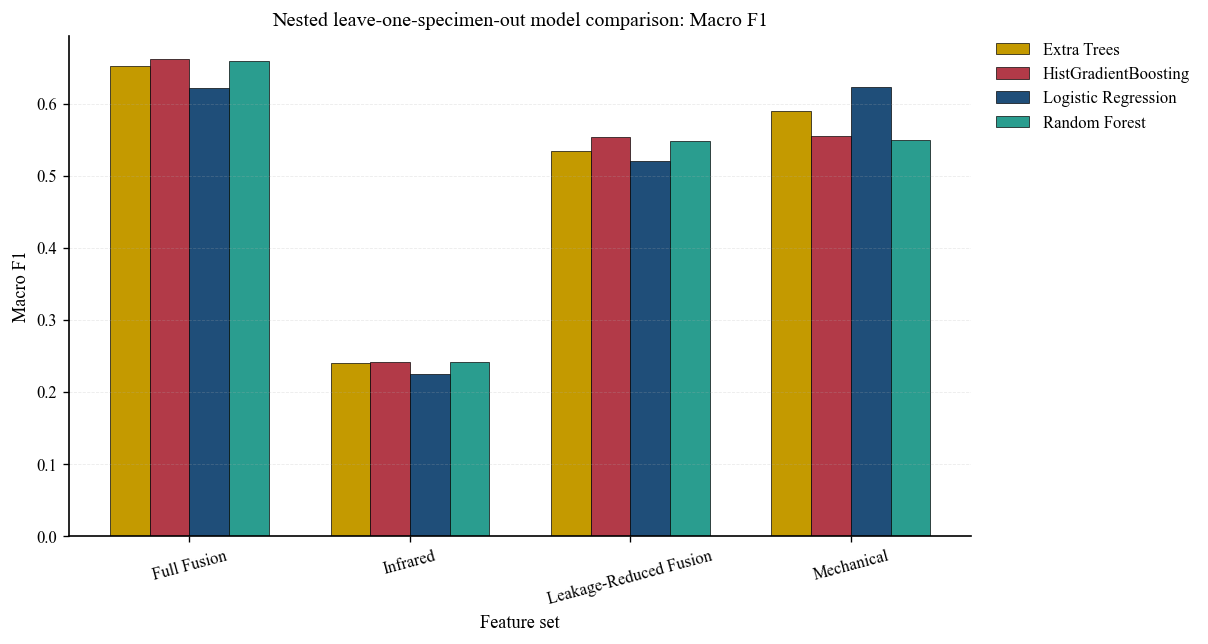

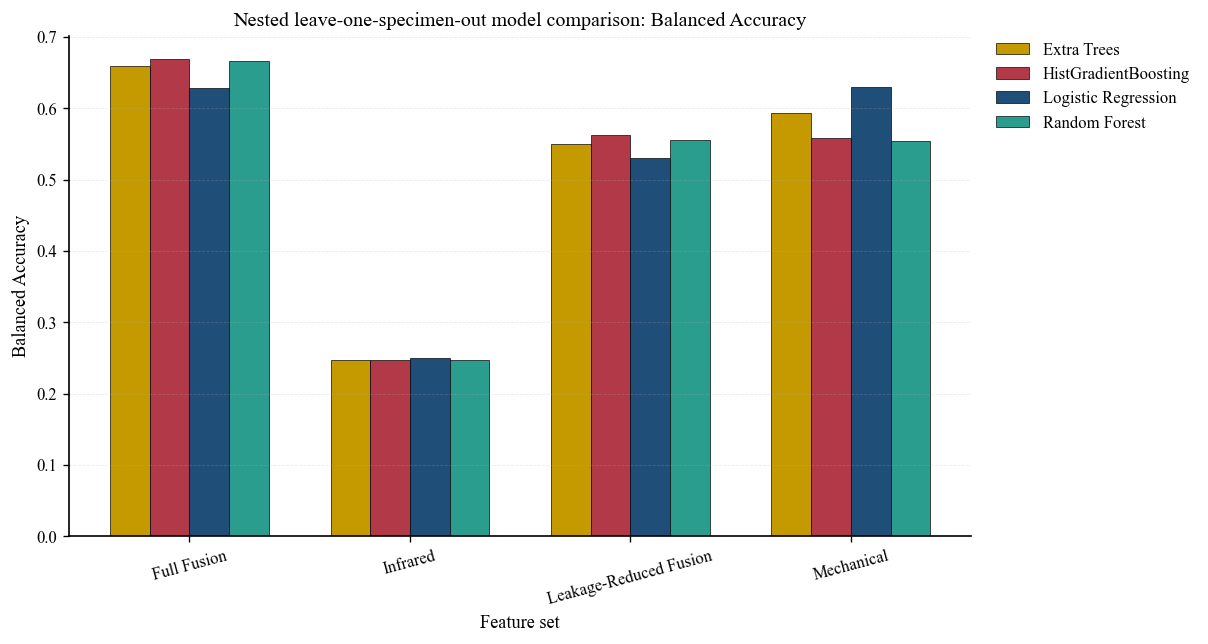

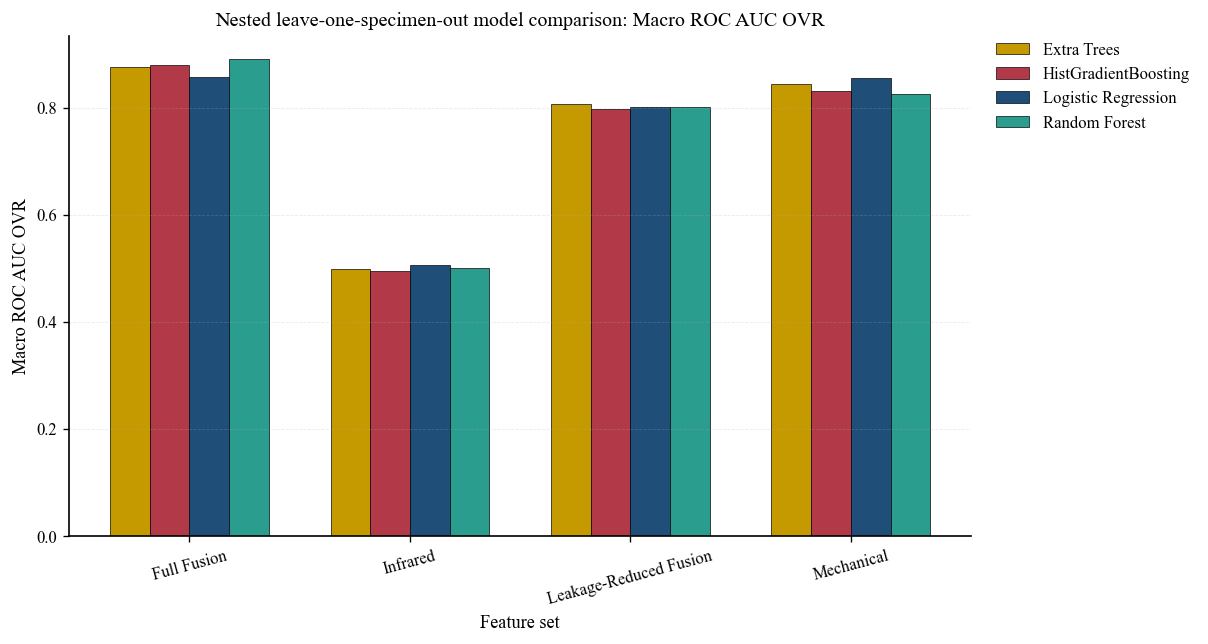

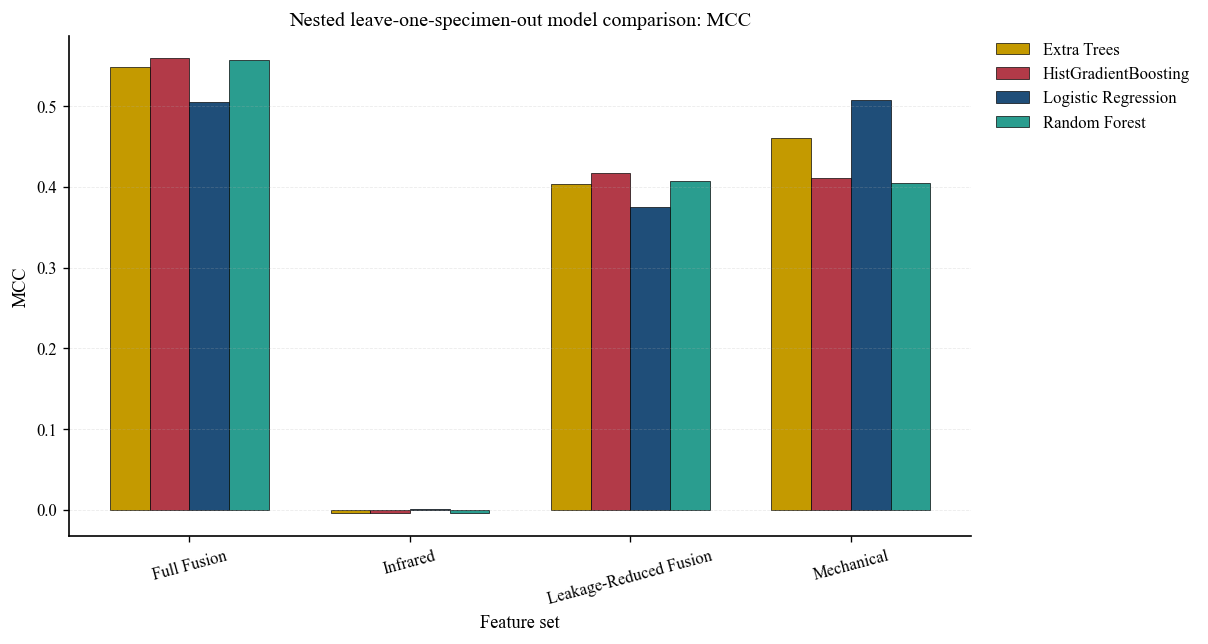

In [10]:
# ============================================================
# 10. Figure 1 — Model comparison
# ============================================================

comparison_metrics = [
    "Macro_F1",
    "Balanced_Accuracy",
    "Macro_ROC_AUC_OVR",
    "MCC"
]

for metric in comparison_metrics:
    pivot = overall_metrics.pivot(
        index="Feature_Set",
        columns="Model",
        values=metric
    )

    fig, ax = plt.subplots(figsize=(10.2, 5.5))

    x = np.arange(len(pivot.index))
    width = 0.18

    for position, model_name in enumerate(pivot.columns):
        offset = (
            position -
            (len(pivot.columns) - 1) / 2
        ) * width

        ax.bar(
            x + offset,
            pivot[model_name],
            width,
            color=MODEL_COLORS[model_name],
            edgecolor="black",
            linewidth=0.4,
            label=model_name
        )

    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index, rotation=15)
    ax.set_xlabel("Feature set")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(
        f"Nested leave-one-specimen-out model comparison: "
        f"{metric.replace('_', ' ')}"
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.25)
    ax.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0
    )

    save_figure(
        fig,
        f"Figure_01_model_comparison_{metric}"
    )
    plt.show()


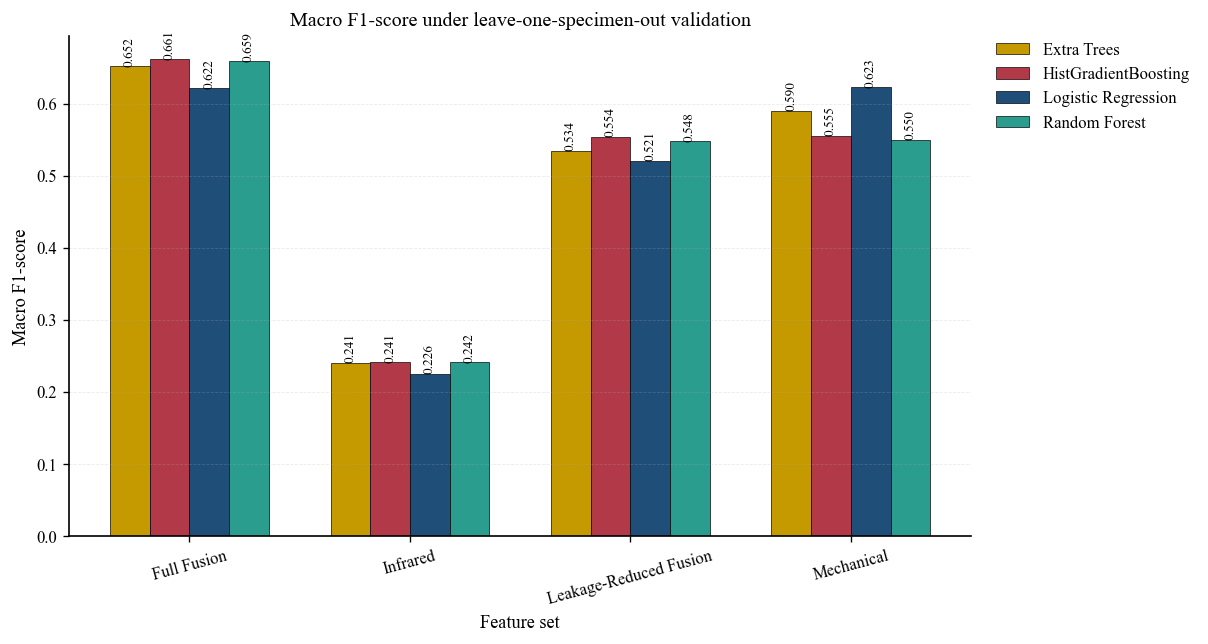

In [11]:
# ============================================================
# 11. Figure 2 — F1-score comparison
# ============================================================

f1_pivot = overall_metrics.pivot(
    index="Feature_Set",
    columns="Model",
    values="Macro_F1"
)

fig, ax = plt.subplots(figsize=(10.2, 5.5))

x = np.arange(len(f1_pivot.index))
width = 0.18

for position, model_name in enumerate(f1_pivot.columns):
    offset = (
        position -
        (len(f1_pivot.columns) - 1) / 2
    ) * width

    bars = ax.bar(
        x + offset,
        f1_pivot[model_name],
        width,
        color=MODEL_COLORS[model_name],
        edgecolor="black",
        linewidth=0.4,
        label=model_name
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

ax.set_xticks(x)
ax.set_xticklabels(f1_pivot.index, rotation=15)
ax.set_xlabel("Feature set")
ax.set_ylabel("Macro F1-score")
ax.set_title("Macro F1-score under leave-one-specimen-out validation")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.25)
ax.legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0
)

save_figure(fig, "Figure_02_macro_F1_comparison")
plt.show()


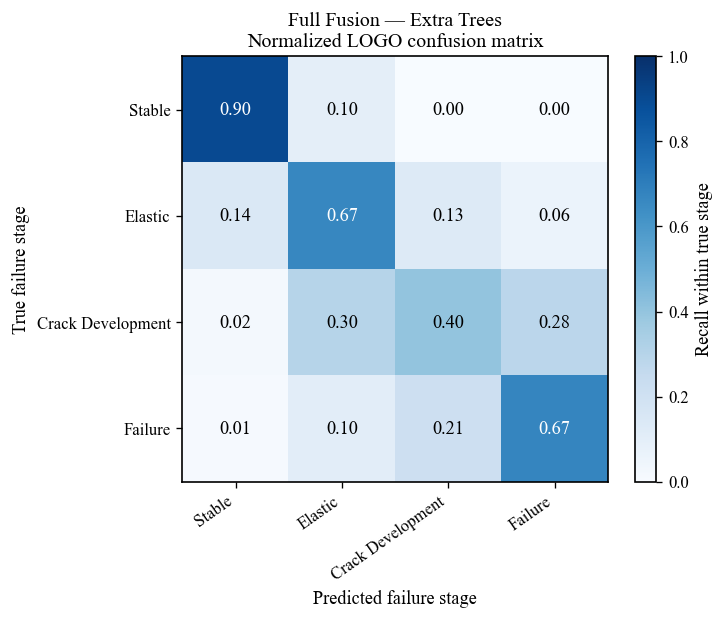

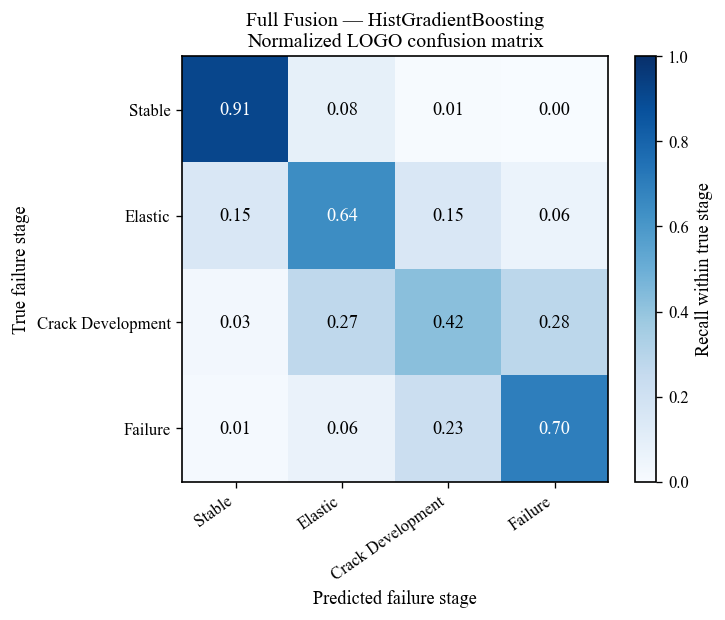

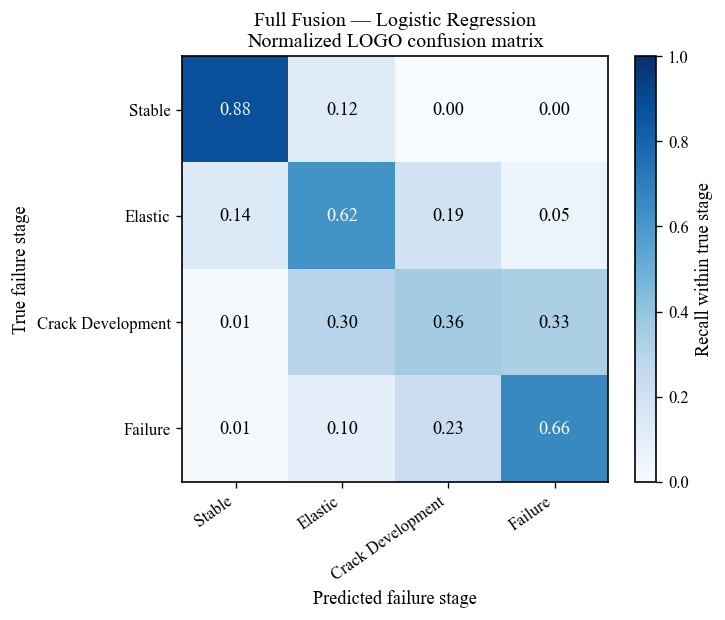

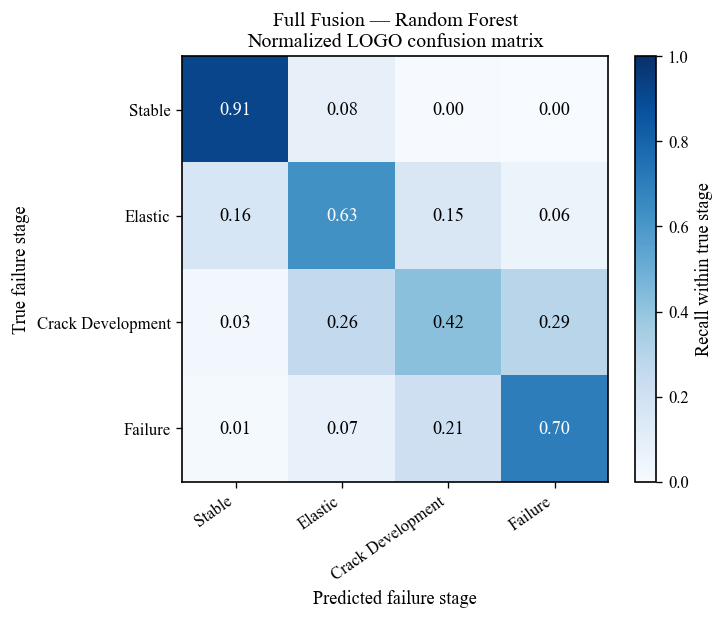

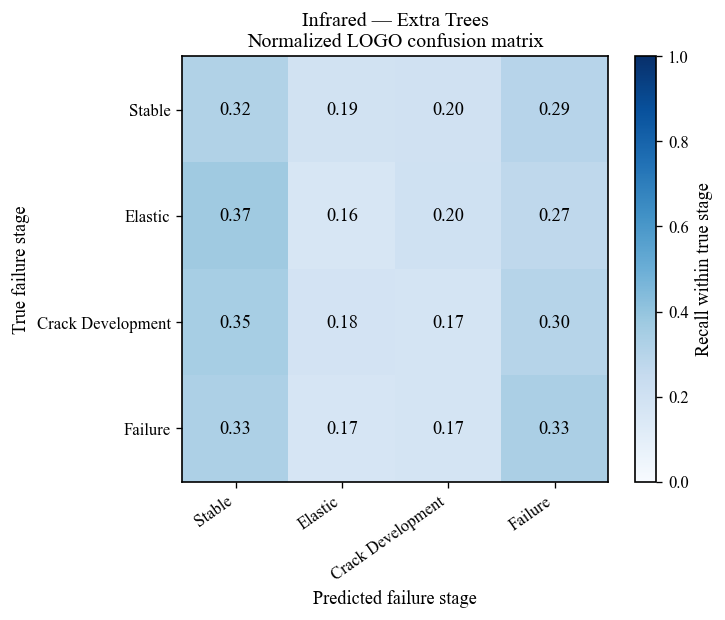

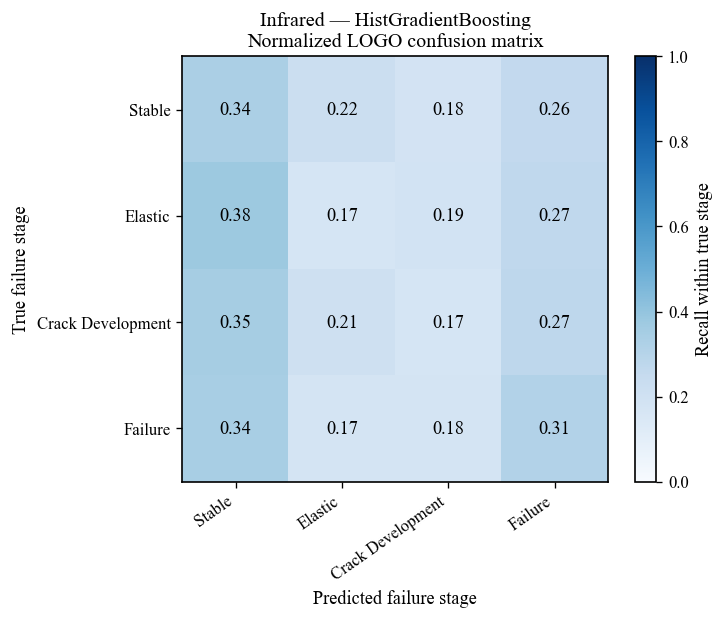

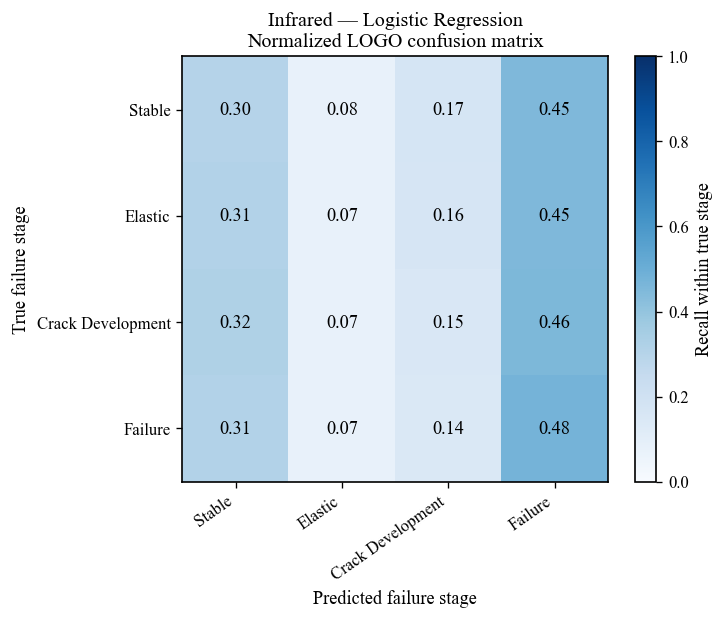

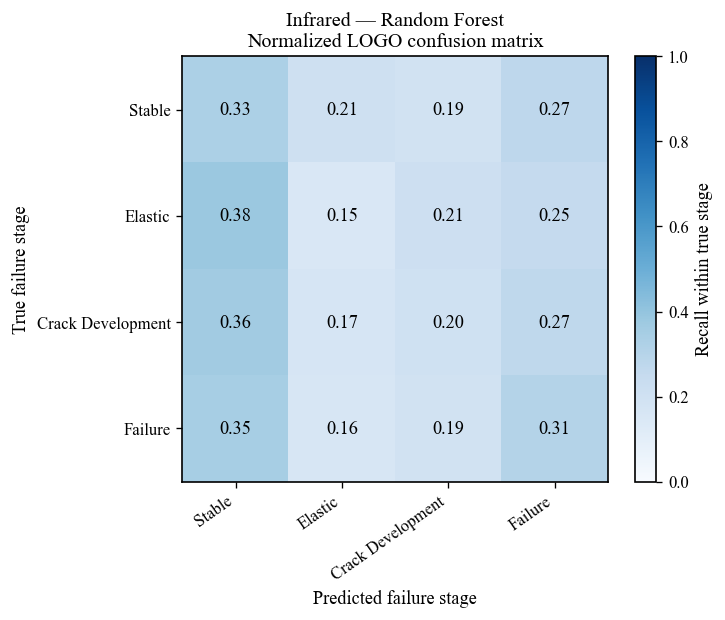

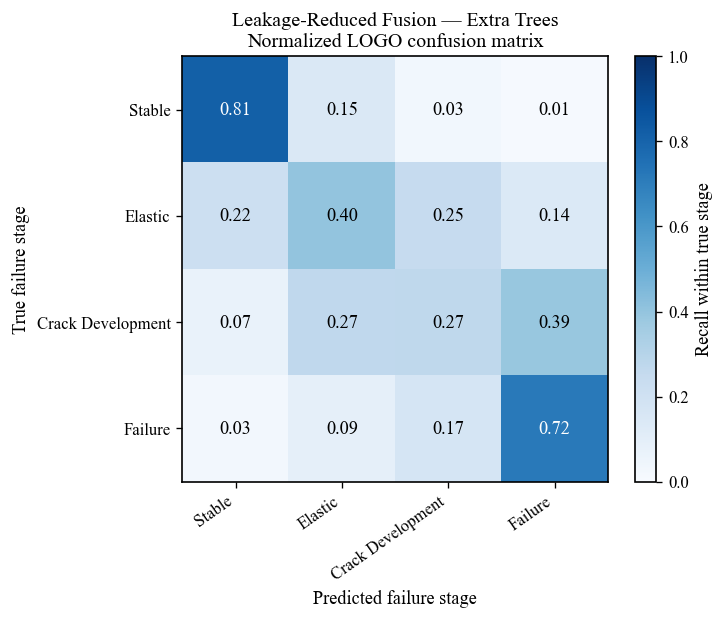

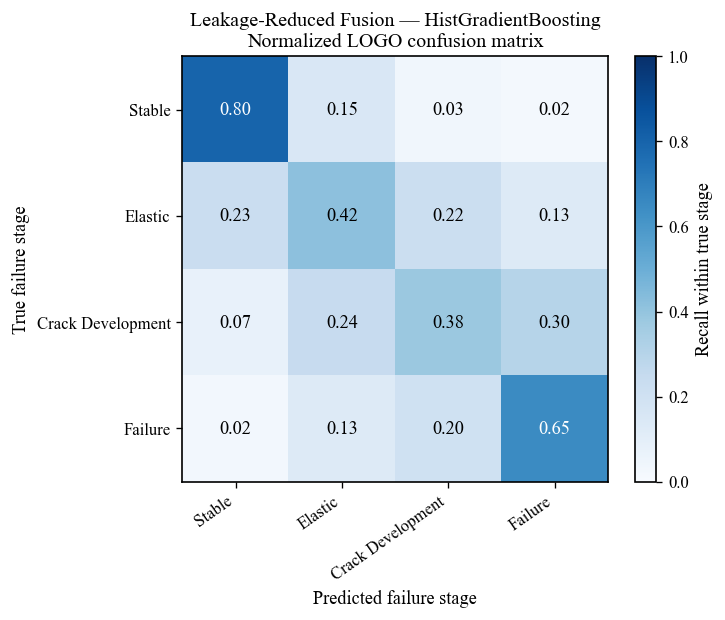

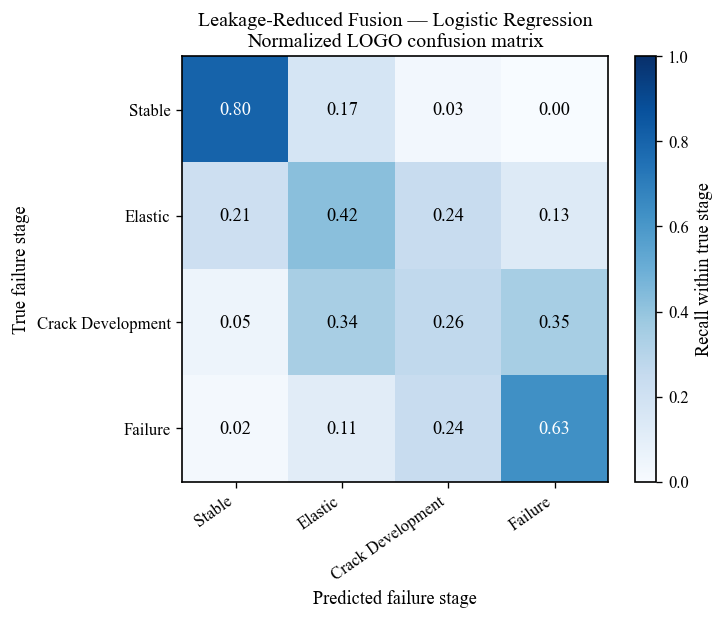

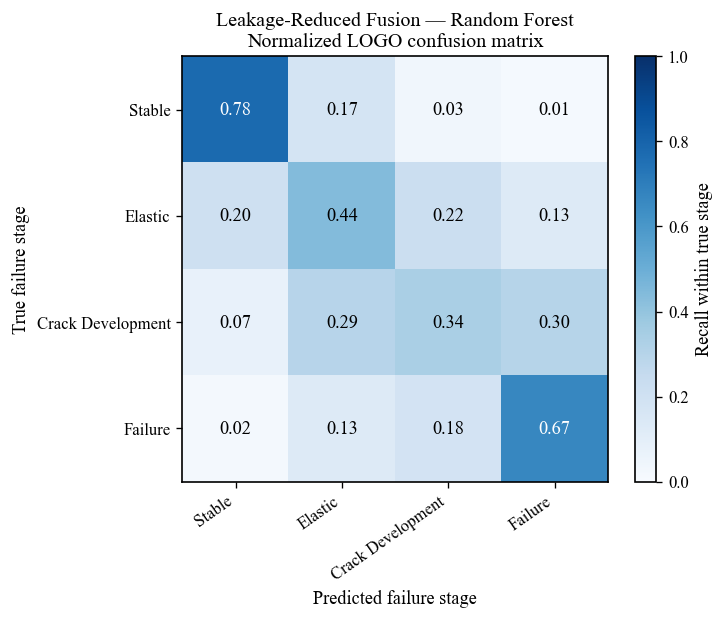

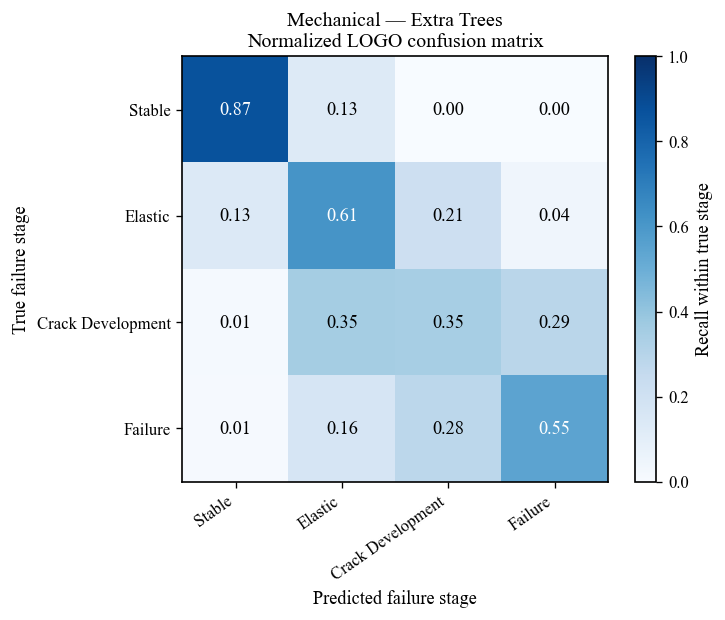

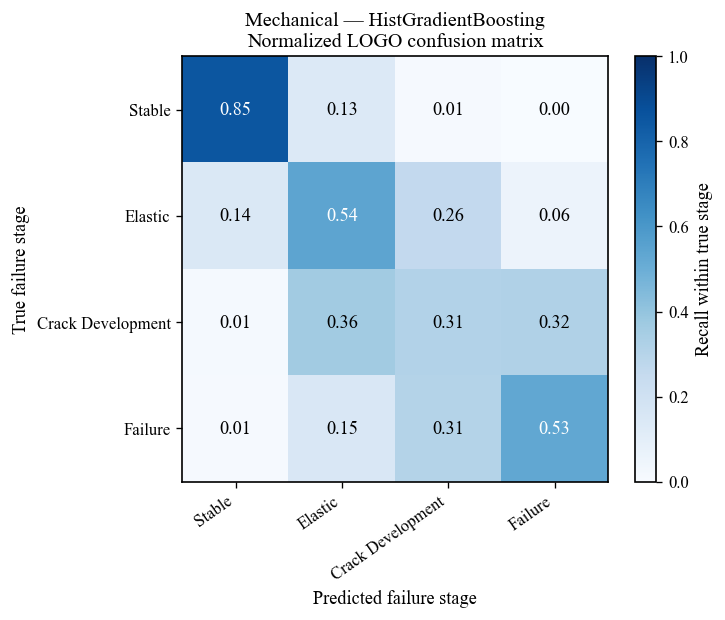

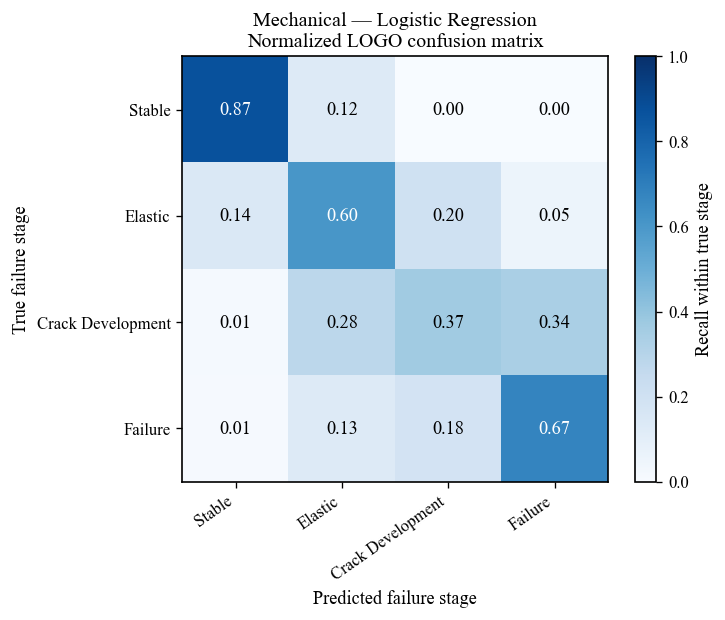

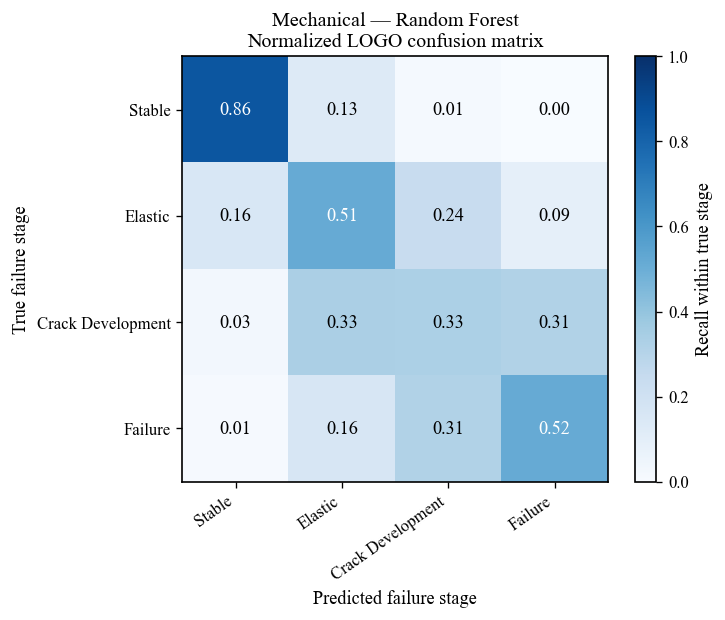

In [12]:
# ============================================================
# 12. Figure 3 — Normalized confusion matrices
# ============================================================

for (feature_set, model_name), group in predictions.groupby(
    ["Feature_Set", "Model"]
):
    matrix = confusion_matrix(
        group["True_Code"],
        group["Predicted_Code"],
        labels=STAGE_CODES,
        normalize="true"
    )

    fig, ax = plt.subplots(figsize=(6.3, 5.3))

    image = ax.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=1
    )

    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix[row, column]
            ax.text(
                column,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                color="white" if value > 0.50 else "black"
            )

    ax.set_xticks(range(len(STAGE_ORDER)))
    ax.set_yticks(range(len(STAGE_ORDER)))
    ax.set_xticklabels(STAGE_ORDER, rotation=35, ha="right")
    ax.set_yticklabels(STAGE_ORDER)
    ax.set_xlabel("Predicted failure stage")
    ax.set_ylabel("True failure stage")
    ax.set_title(
        f"{feature_set} — {model_name}\n"
        "Normalized LOGO confusion matrix"
    )

    colorbar = fig.colorbar(image, ax=ax)
    colorbar.set_label("Recall within true stage")

    safe_feature = feature_set.replace(" ", "_").replace("-", "_")
    safe_model = model_name.replace(" ", "_")

    save_figure(
        fig,
        f"Figure_03_confusion_{safe_feature}_{safe_model}",
        model_name=model_name
    )
    plt.show()


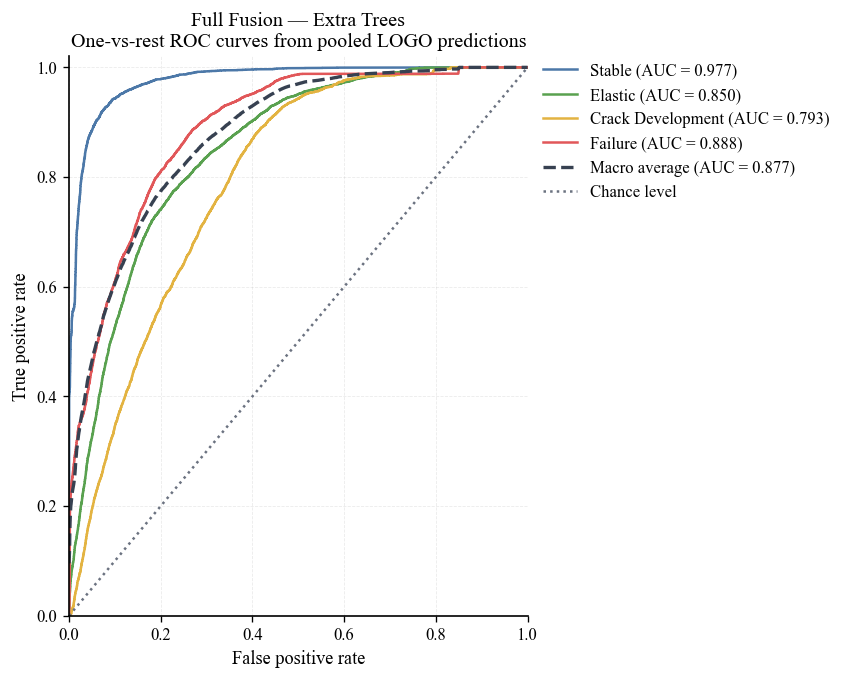

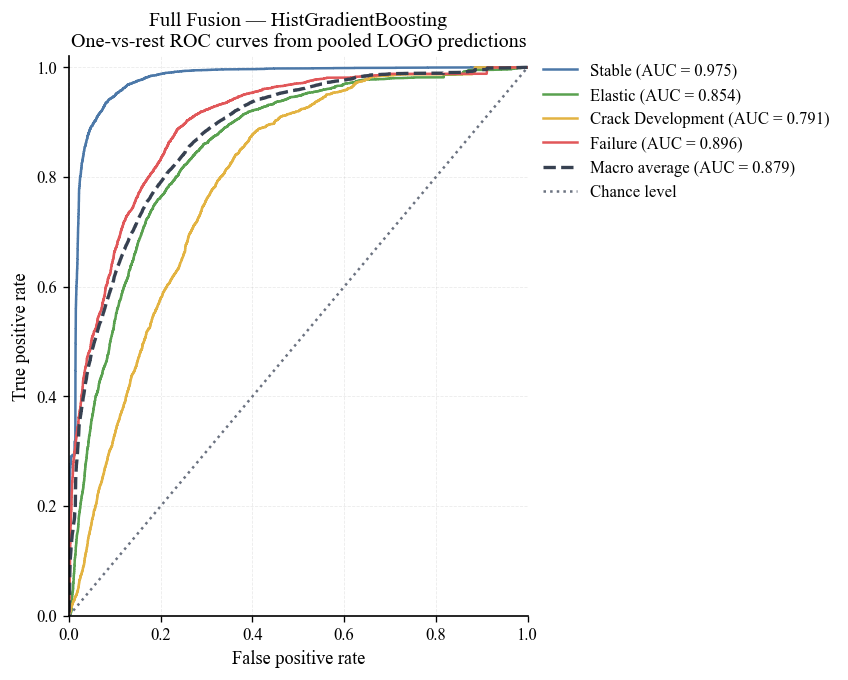

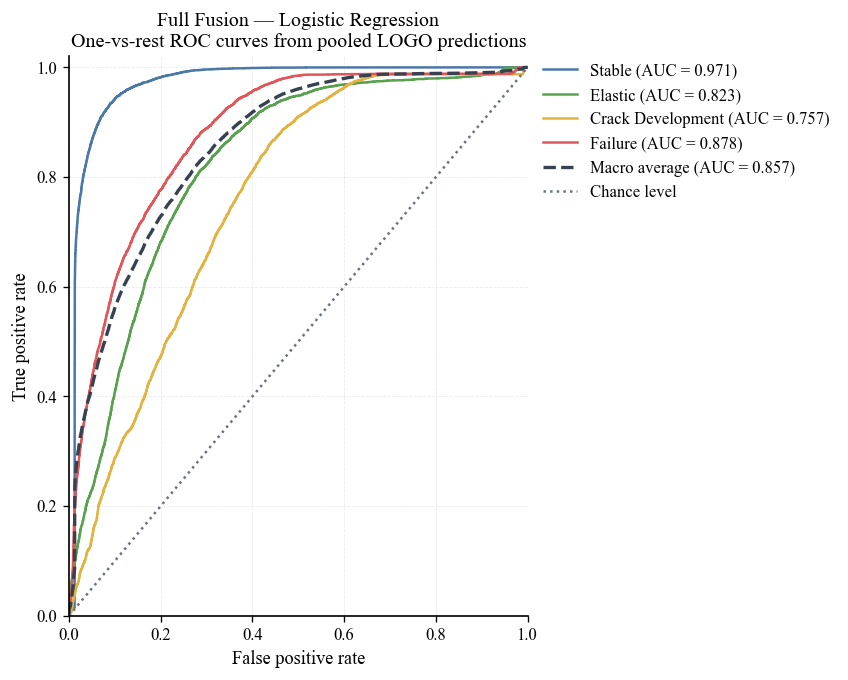

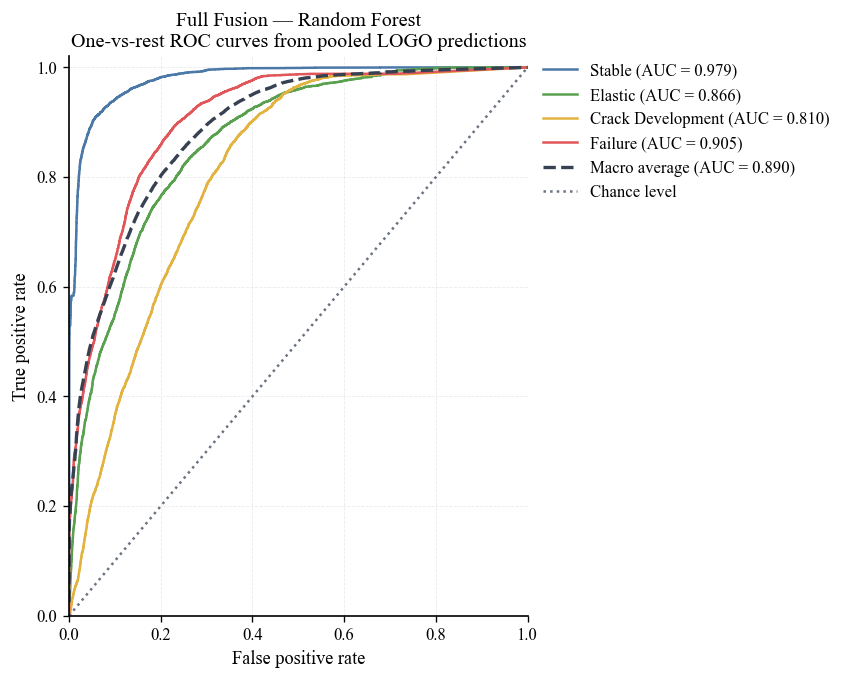

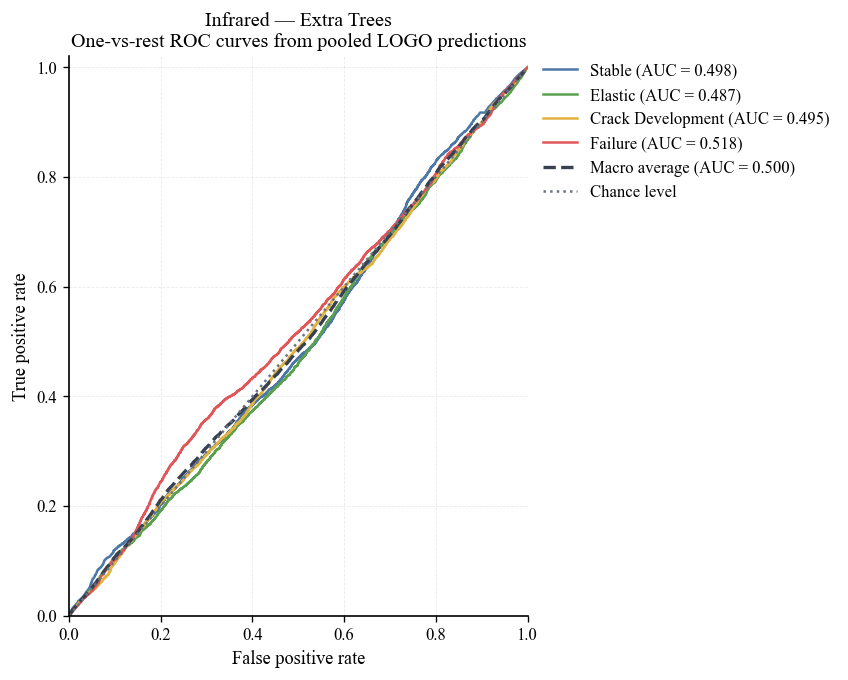

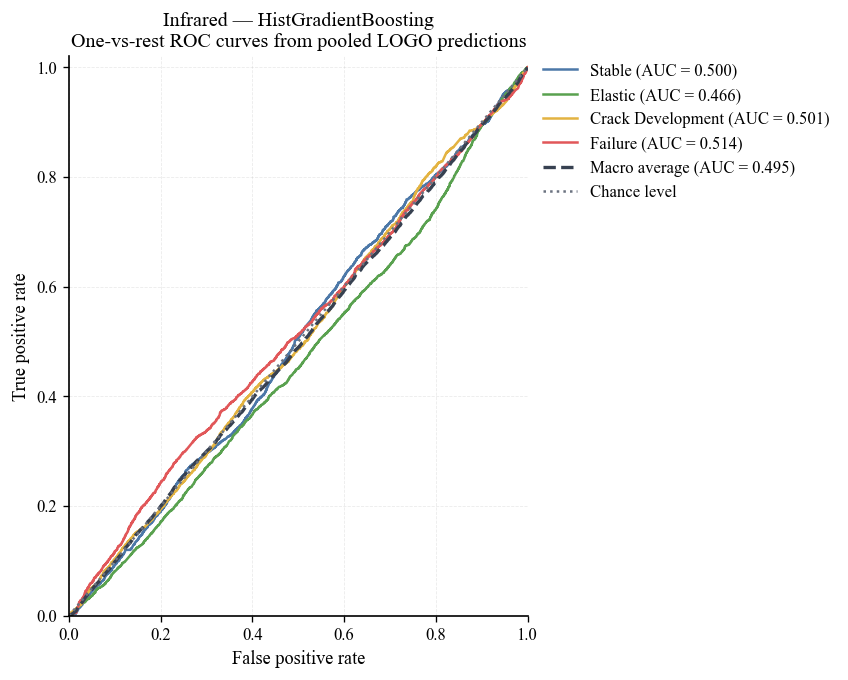

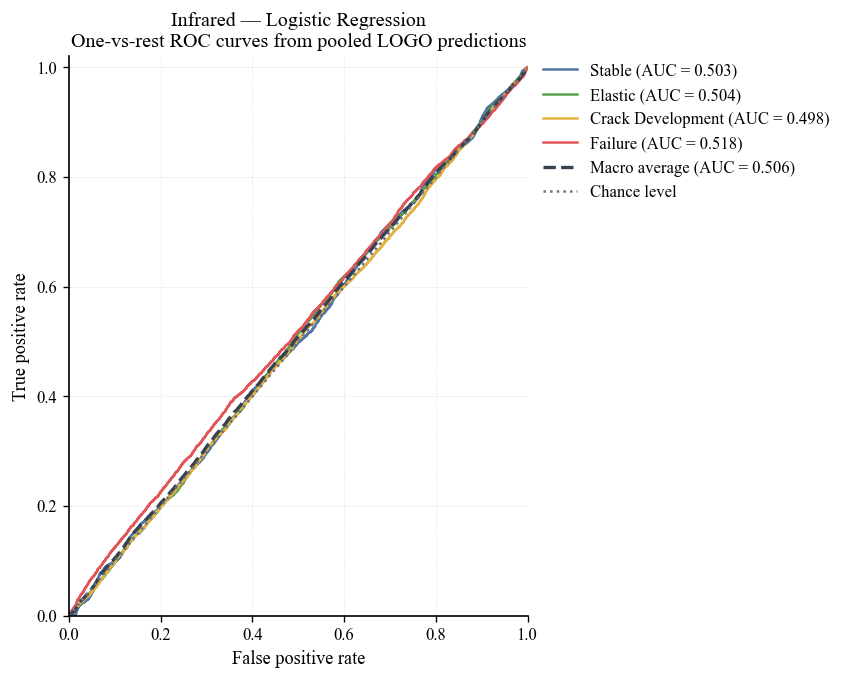

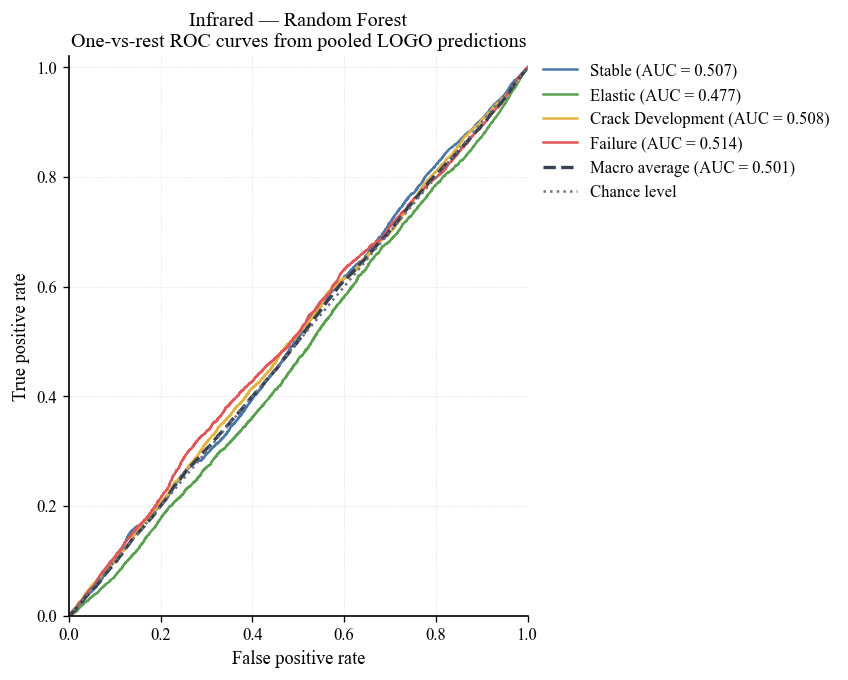

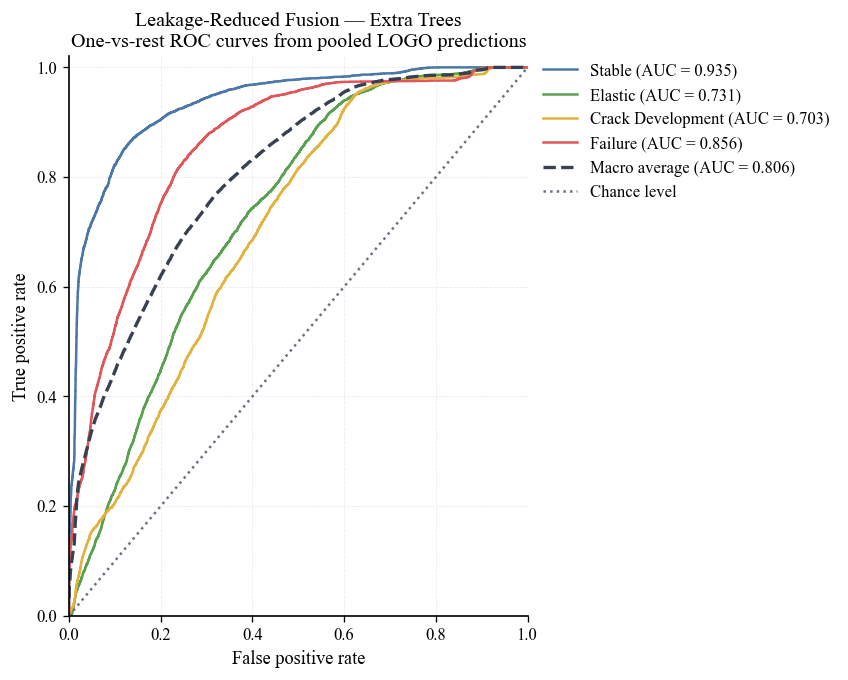

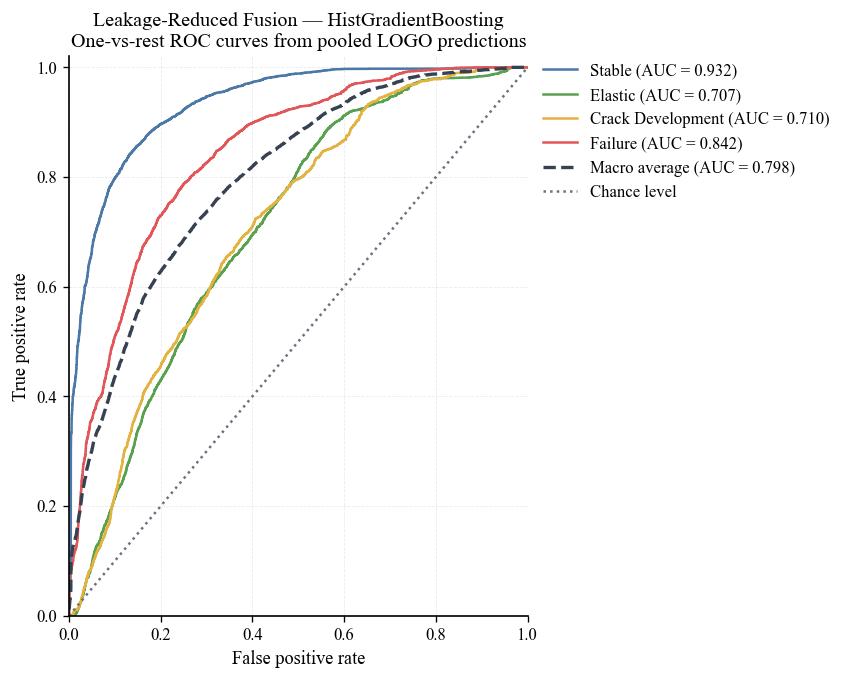

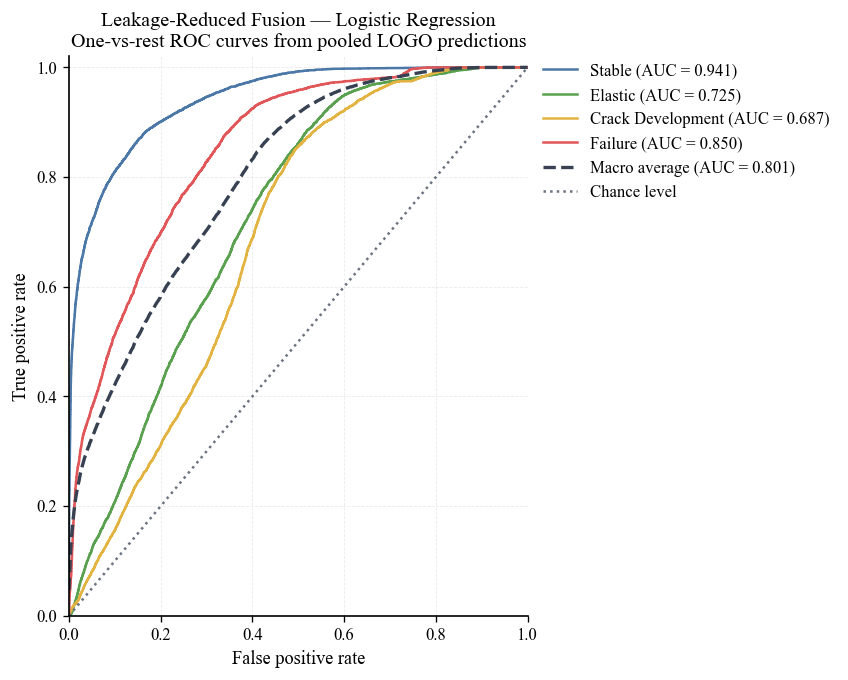

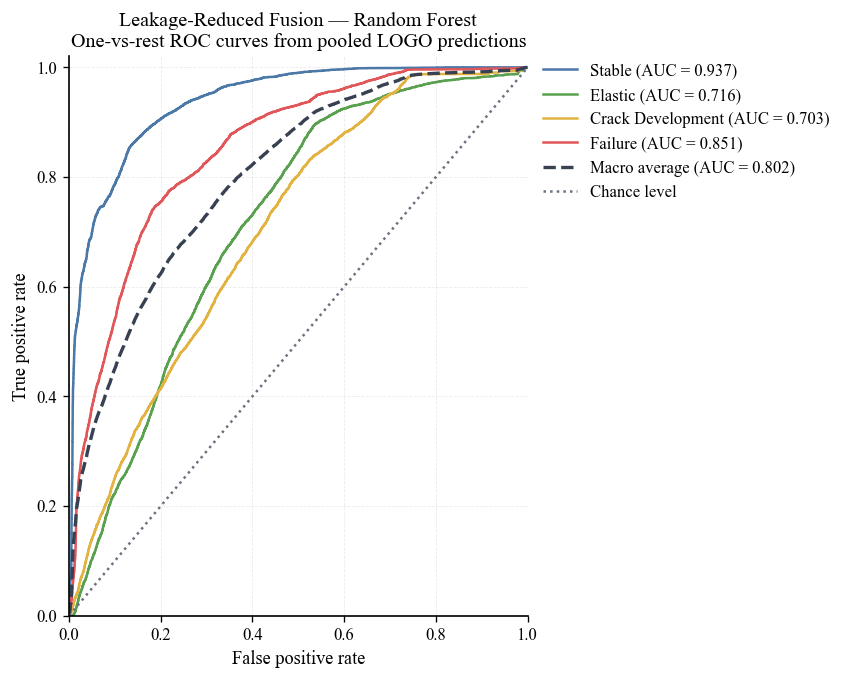

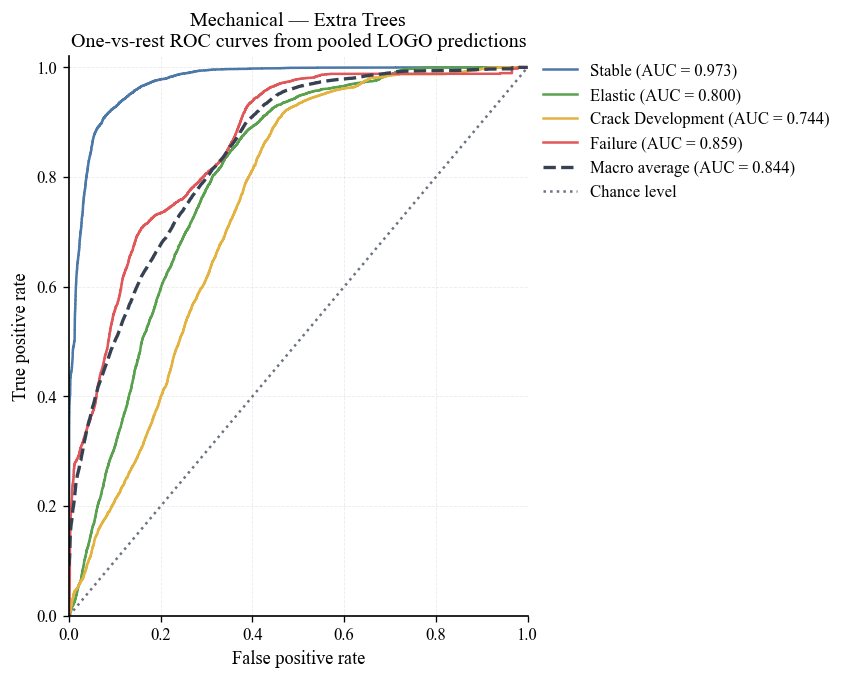

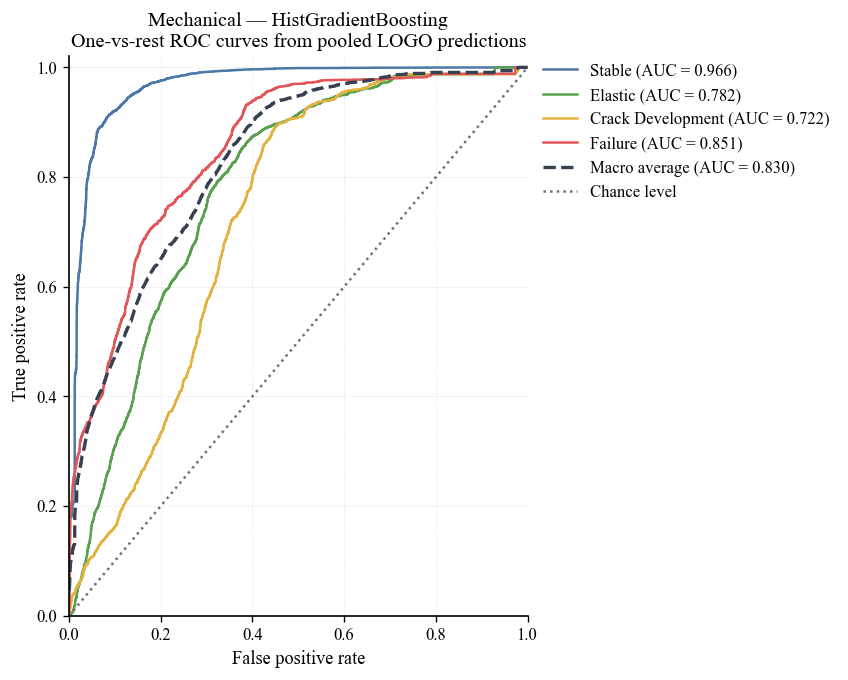

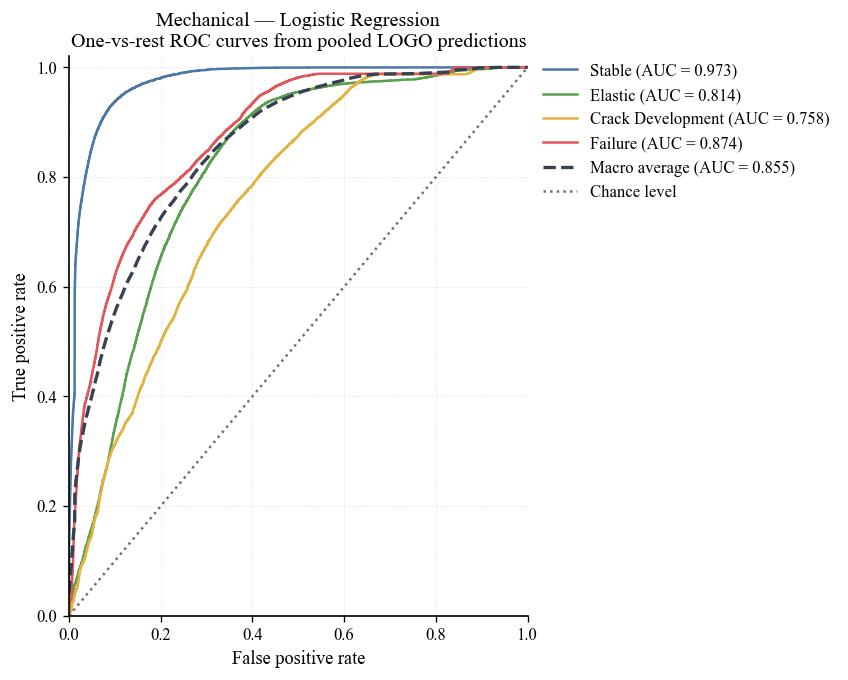

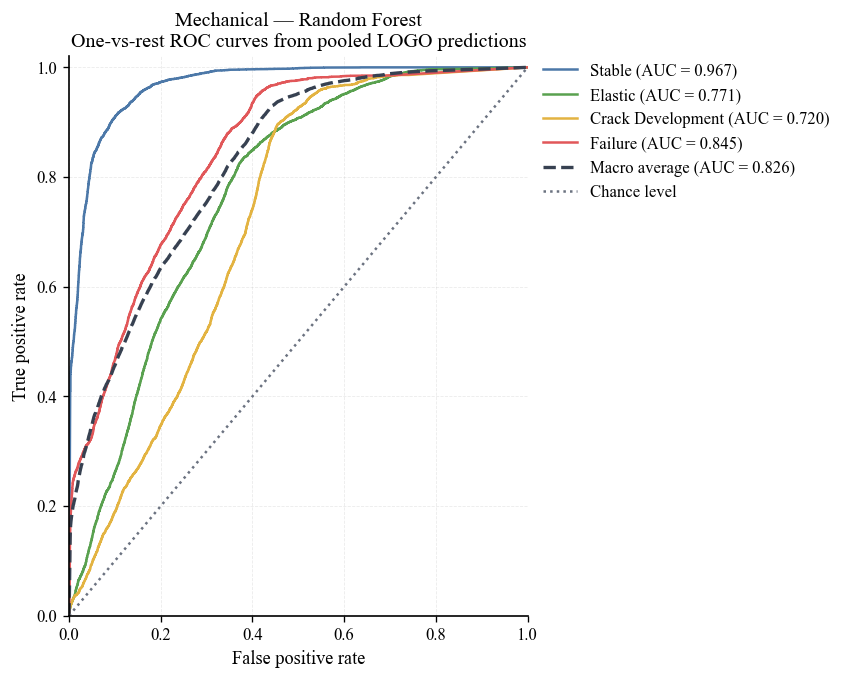

In [13]:
# ============================================================
# 13. Figure 4 — Multiclass ROC curves and AUC
# ============================================================

probability_columns = [
    f"Probability_{stage}"
    for stage in STAGE_ORDER
]

for (feature_set, model_name), group in predictions.groupby(
    ["Feature_Set", "Model"]
):
    y_true = group["True_Code"].to_numpy()
    probabilities = group[probability_columns].to_numpy()
    y_binary = label_binarize(
        y_true,
        classes=STAGE_CODES
    )

    fig, ax = plt.subplots(figsize=(7.2, 5.8))

    valid_fpr = []
    valid_tpr = []
    valid_auc = []

    for class_index, stage_name in enumerate(STAGE_ORDER):
        binary_target = y_binary[:, class_index]

        if np.unique(binary_target).size < 2:
            continue

        fpr, tpr, _ = roc_curve(
            binary_target,
            probabilities[:, class_index]
        )
        class_auc = auc(fpr, tpr)

        valid_fpr.append(fpr)
        valid_tpr.append(tpr)
        valid_auc.append(class_auc)

        ax.plot(
            fpr,
            tpr,
            color=STAGE_COLORS[stage_name],
            label=f"{stage_name} (AUC = {class_auc:.3f})"
        )

    # Macro-average ROC curve
    if valid_fpr:
        all_fpr = np.unique(
            np.concatenate(valid_fpr)
        )
        mean_tpr = np.zeros_like(all_fpr)

        for fpr, tpr in zip(valid_fpr, valid_tpr):
            mean_tpr += np.interp(all_fpr, fpr, tpr)

        mean_tpr /= len(valid_fpr)
        macro_curve_auc = auc(all_fpr, mean_tpr)

        ax.plot(
            all_fpr,
            mean_tpr,
            color=ACADEMIC_COLORS["dark_grey"],
            linestyle="--",
            linewidth=2.0,
            label=f"Macro average (AUC = {macro_curve_auc:.3f})"
        )

    ax.plot(
        [0, 1],
        [0, 1],
        color=ACADEMIC_COLORS["grey"],
        linestyle=":",
        label="Chance level"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(
        f"{feature_set} — {model_name}\n"
        "One-vs-rest ROC curves from pooled LOGO predictions"
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(linestyle="--", linewidth=0.5, alpha=0.25)
    ax.legend(
        frameon=False,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0
    )

    safe_feature = feature_set.replace(" ", "_").replace("-", "_")
    safe_model = model_name.replace(" ", "_")

    save_figure(
        fig,
        f"Figure_04_ROC_{safe_feature}_{safe_model}",
        model_name=model_name
    )
    plt.show()


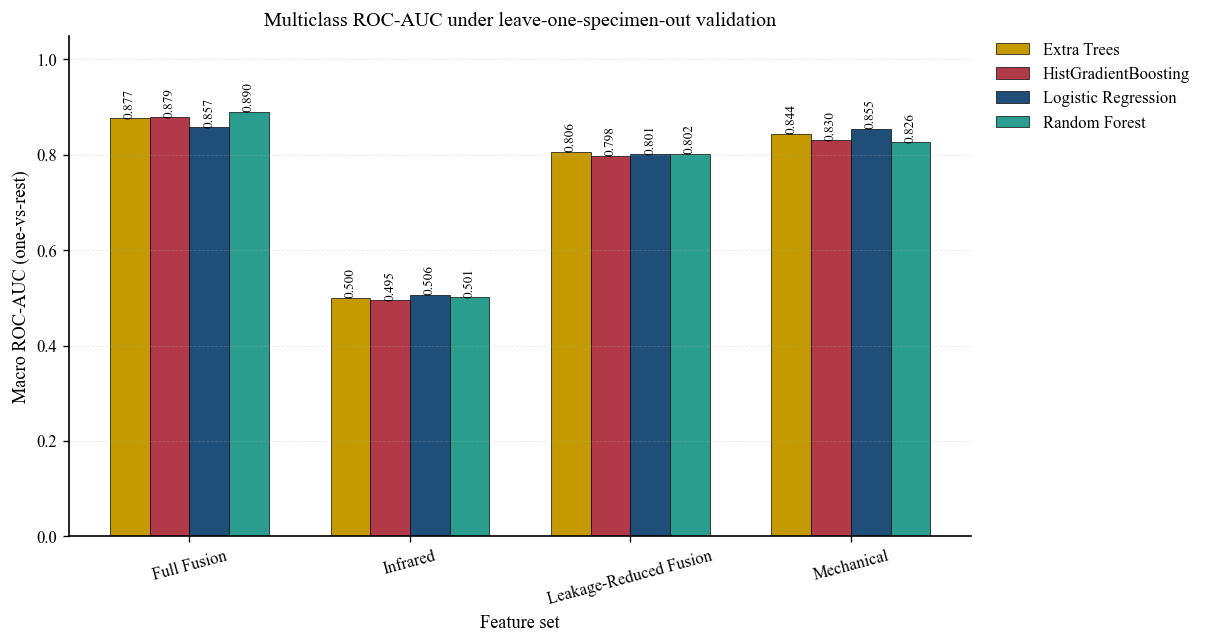

In [14]:
# ============================================================
# 14. Figure 5 — AUC comparison
# ============================================================

auc_pivot = overall_metrics.pivot(
    index="Feature_Set",
    columns="Model",
    values="Macro_ROC_AUC_OVR"
)

fig, ax = plt.subplots(figsize=(10.2, 5.5))

x = np.arange(len(auc_pivot.index))
width = 0.18

for position, model_name in enumerate(auc_pivot.columns):
    offset = (
        position -
        (len(auc_pivot.columns) - 1) / 2
    ) * width

    bars = ax.bar(
        x + offset,
        auc_pivot[model_name],
        width,
        color=MODEL_COLORS[model_name],
        edgecolor="black",
        linewidth=0.4,
        label=model_name
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

ax.set_xticks(x)
ax.set_xticklabels(auc_pivot.index, rotation=15)
ax.set_xlabel("Feature set")
ax.set_ylabel("Macro ROC-AUC (one-vs-rest)")
ax.set_title("Multiclass ROC-AUC under leave-one-specimen-out validation")
ax.set_ylim(0, 1.05)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.25)
ax.legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0
)

save_figure(fig, "Figure_05_macro_ROC_AUC_comparison")
plt.show()


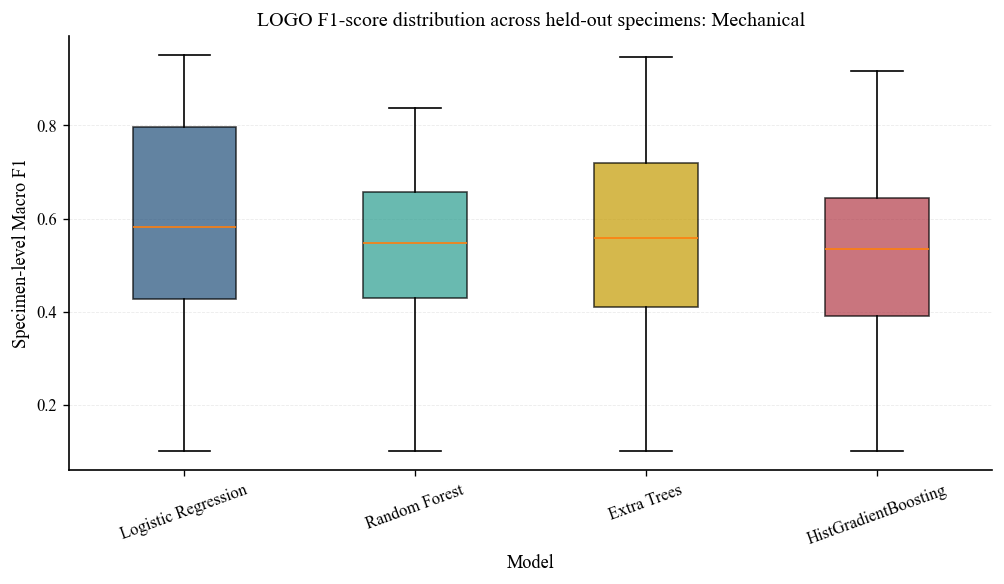

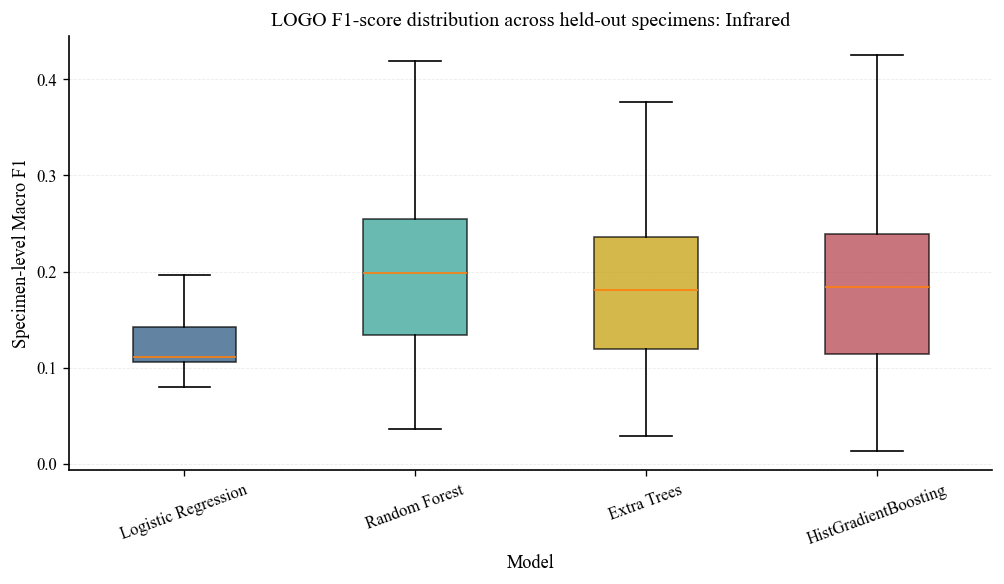

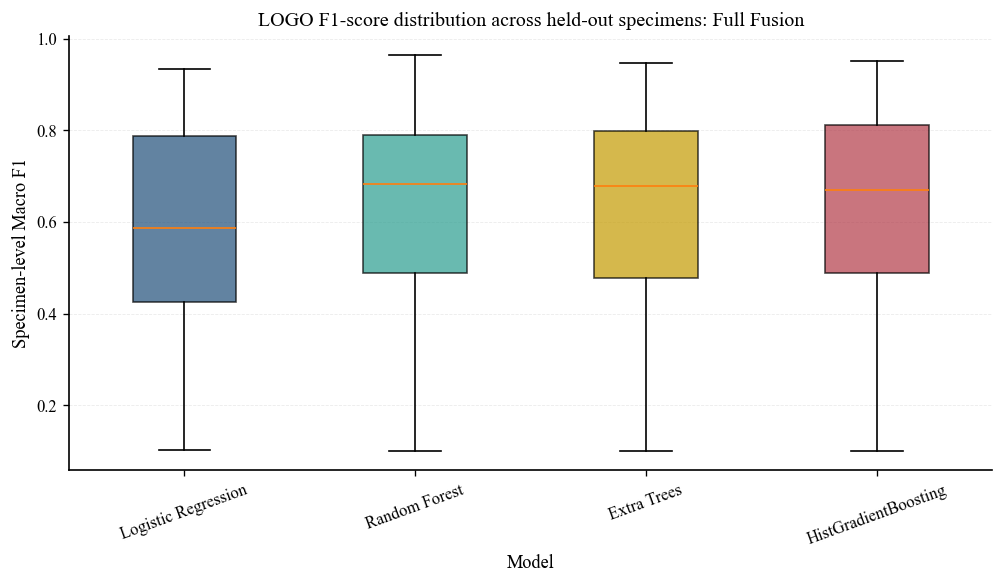

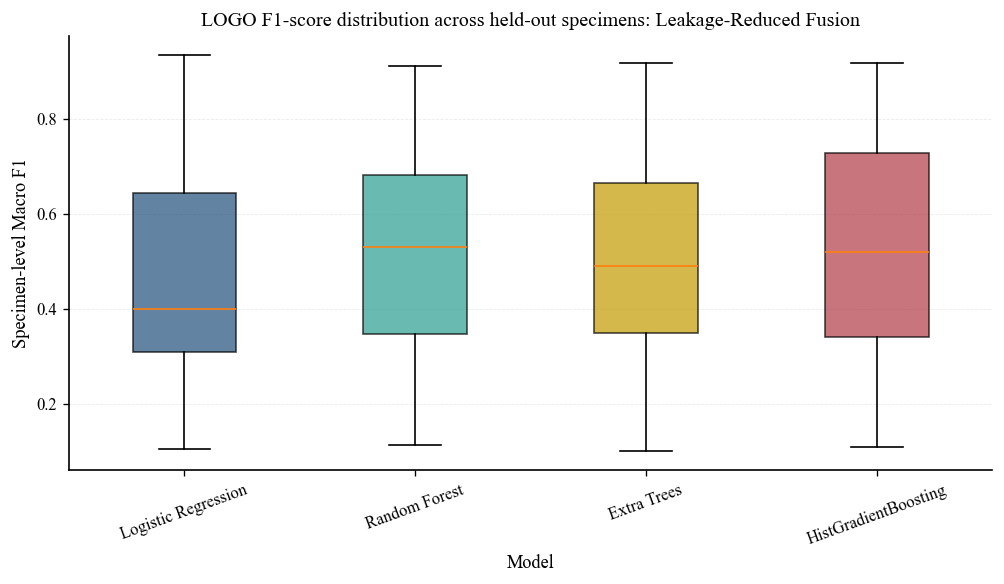

In [15]:
# ============================================================
# 15. Figure 6 — Fold-level F1 distributions
# ============================================================

for feature_set in FEATURE_SETS:
    subset = fold_metrics.loc[
        fold_metrics["Feature_Set"] == feature_set
    ]

    values = [
        subset.loc[
            subset["Model"] == model_name,
            "Macro_F1"
        ].to_numpy()
        for model_name in MODEL_SPECS
    ]

    fig, ax = plt.subplots(figsize=(8.5, 5.0))

    boxplot = ax.boxplot(
        values,
        labels=list(MODEL_SPECS),
        patch_artist=True,
        showfliers=False
    )

    for patch, model_name in zip(
        boxplot["boxes"],
        MODEL_SPECS
    ):
        patch.set_facecolor(MODEL_COLORS[model_name])
        patch.set_alpha(0.70)

    ax.set_xlabel("Model")
    ax.set_ylabel("Specimen-level Macro F1")
    ax.set_title(
        f"LOGO F1-score distribution across held-out specimens: "
        f"{feature_set}"
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", linewidth=0.5, alpha=0.25)
    plt.xticks(rotation=20)

    safe_feature = feature_set.replace(" ", "_").replace("-", "_")

    save_figure(
        fig,
        f"Figure_06_fold_F1_{safe_feature}"
    )
    plt.show()


In [17]:
# ============================================================
# FIXED: native and permutation importance summaries
# ============================================================

# -----------------------------
# Native importance summary
# -----------------------------
native_importance_summary = pd.DataFrame()

if (
    "native_importance_all" in globals()
    and isinstance(native_importance_all, pd.DataFrame)
    and not native_importance_all.empty
):
    native_group_columns = [
        column
        for column in ["Feature_Set", "Model", "Feature", "Method"]
        if column in native_importance_all.columns
    ]

    native_value_column = (
        "Normalized_Importance"
        if "Normalized_Importance" in native_importance_all.columns
        else "Importance"
    )

    native_aggregations = {
        "Mean_Importance": (native_value_column, "mean"),
        "SD_Importance": (native_value_column, "std")
    }

    if "Fold" in native_importance_all.columns:
        native_aggregations["Folds"] = ("Fold", "nunique")

    native_importance_summary = (
        native_importance_all
        .groupby(native_group_columns, as_index=False)
        .agg(**native_aggregations)
    )

    native_importance_summary.to_csv(
        IMPORTANCE_DIR / "native_feature_importance_summary.csv",
        index=False
    )

    native_importance_summary.to_excel(
        IMPORTANCE_DIR / "native_feature_importance_summary.xlsx",
        index=False
    )

    for model_name in MODEL_SPECS:
        native_model_summary = (
            native_importance_summary.loc[
                native_importance_summary["Model"] == model_name
            ]
            .copy()
        )

        native_model_summary.to_csv(
            MODEL_OUTPUT_DIRS[model_name]["importance"] /
            "native_feature_importance_summary.csv",
            index=False
        )

        native_model_summary.to_excel(
            MODEL_OUTPUT_DIRS[model_name]["importance"] /
            "native_feature_importance_summary.xlsx",
            index=False
        )

else:
    print(
        "No native feature-importance table was available. "
        "This is acceptable for models without native importance."
    )


# -----------------------------
# Permutation importance summary
# -----------------------------
if (
    "permutation_importance_all" not in globals()
    or not isinstance(permutation_importance_all, pd.DataFrame)
    or permutation_importance_all.empty
):
    raise ValueError(
        "permutation_importance_all is missing or empty. "
        "Run the earlier permutation-importance calculation cell first."
    )

permutation_group_columns = [
    column
    for column in ["Feature_Set", "Model", "Feature"]
    if column in permutation_importance_all.columns
]

if "Permutation_Importance_Mean" in permutation_importance_all.columns:
    permutation_value_column = "Permutation_Importance_Mean"
elif "Importance_Mean" in permutation_importance_all.columns:
    permutation_value_column = "Importance_Mean"
elif "Importance" in permutation_importance_all.columns:
    permutation_value_column = "Importance"
else:
    raise KeyError(
        "No valid permutation-importance value column was found. "
        "Expected one of: Permutation_Importance_Mean, "
        "Importance_Mean, or Importance."
    )

permutation_aggregations = {
    "Mean_Importance": (permutation_value_column, "mean"),
    "SD_Importance": (permutation_value_column, "std")
}

if "Fold" in permutation_importance_all.columns:
    permutation_aggregations["Folds"] = ("Fold", "nunique")

permutation_importance_summary = (
    permutation_importance_all
    .groupby(permutation_group_columns, as_index=False)
    .agg(**permutation_aggregations)
)

# Save central copies.
permutation_importance_summary.to_csv(
    IMPORTANCE_DIR / "permutation_feature_importance_summary.csv",
    index=False
)

permutation_importance_summary.to_excel(
    IMPORTANCE_DIR / "permutation_feature_importance_summary.xlsx",
    index=False
)

# Save one summary table inside each model folder.
for model_name in MODEL_SPECS:
    permutation_model_summary = (
        permutation_importance_summary.loc[
            permutation_importance_summary["Model"] == model_name
        ]
        .copy()
    )

    permutation_model_summary.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["importance"] /
        "permutation_feature_importance_summary.csv",
        index=False
    )

    permutation_model_summary.to_excel(
        MODEL_OUTPUT_DIRS[model_name]["importance"] /
        "permutation_feature_importance_summary.xlsx",
        index=False
    )

print("Native and permutation importance summaries were created successfully.")
display(permutation_importance_summary.head())


Native and permutation importance summaries were created successfully.


,Feature_Set,Model,Feature,Mean_Importance,SD_Importance,Folds
0,Full Fusion,Extra Trees,AIRT_C,0.004525,0.022263,80
1,Full Fusion,Extra Trees,Strain,0.172558,0.143185,80
2,Full Fusion,Extra Trees,Stress_MPa,0.277592,0.152233,80
3,Full Fusion,Extra Trees,VSMIT,0.001625,0.009125,80
4,Full Fusion,HistGradientBoosting,AIRT_C,0.003575,0.029817,80


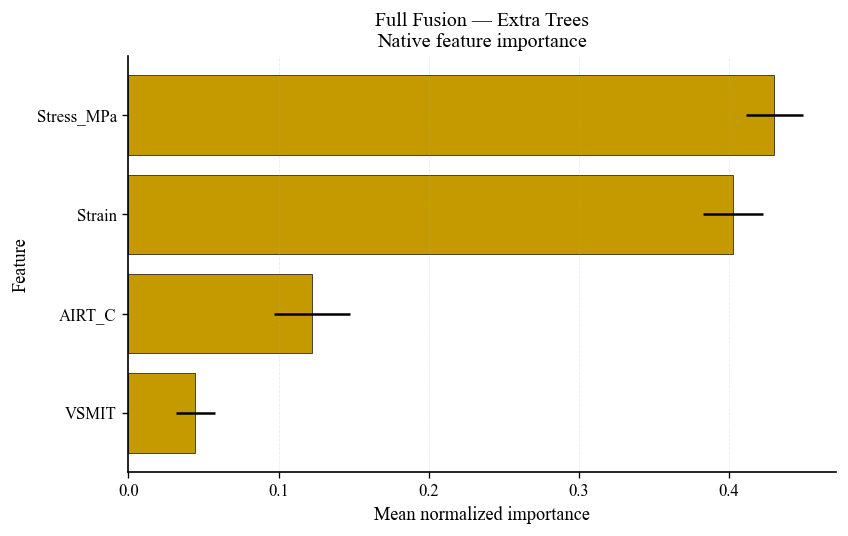

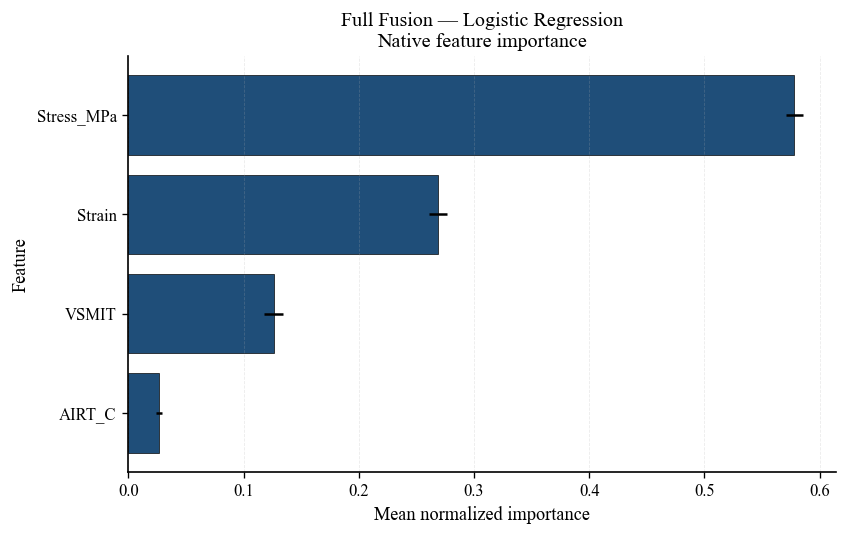

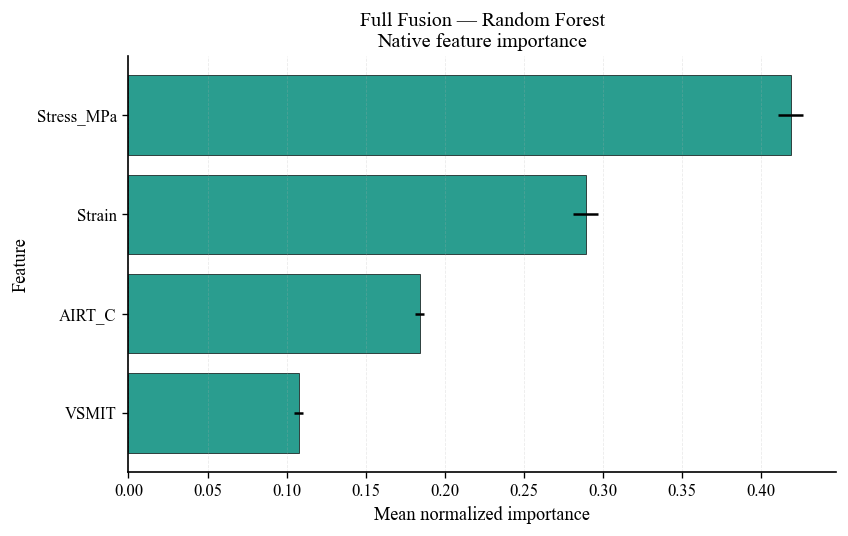

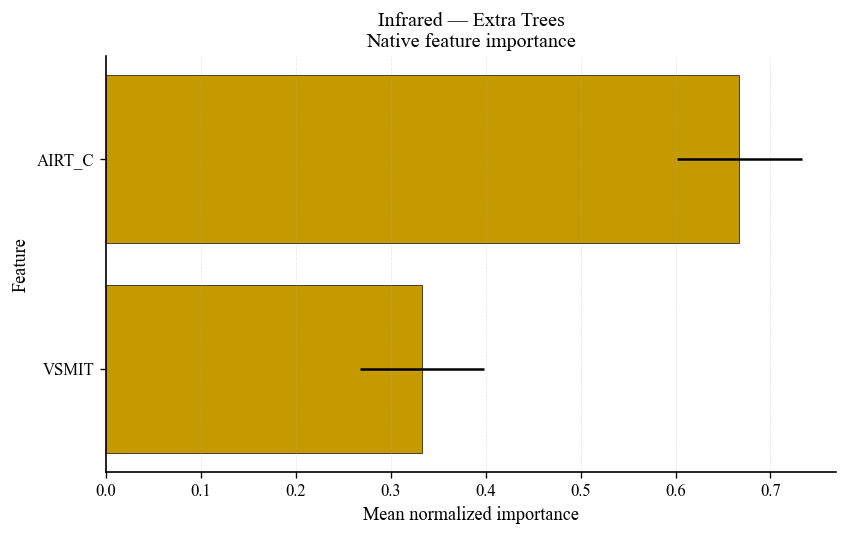

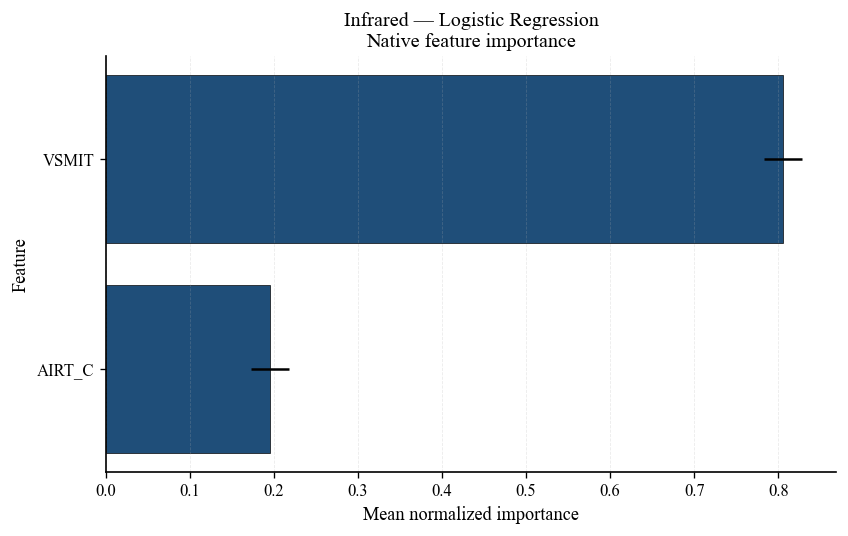

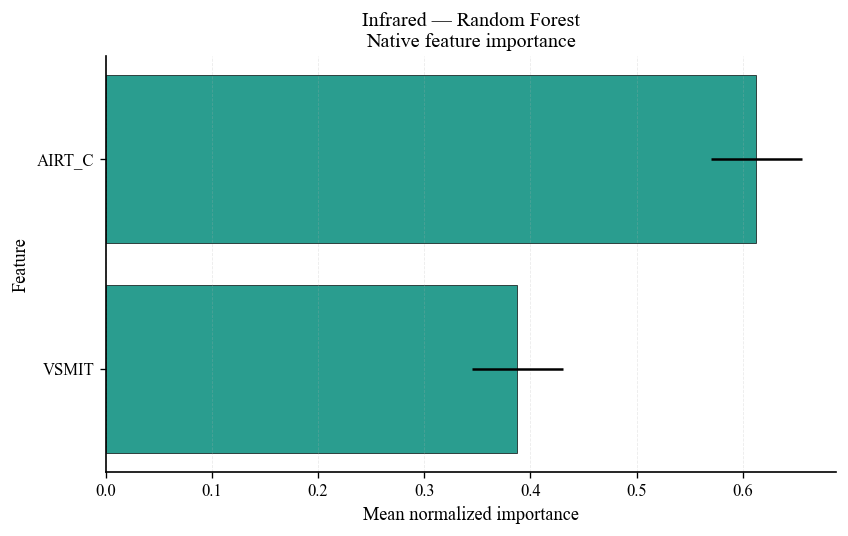

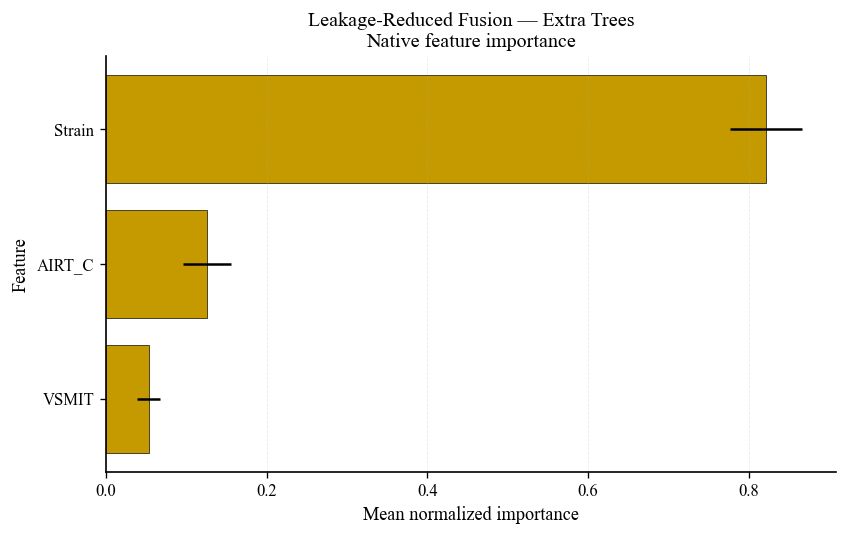

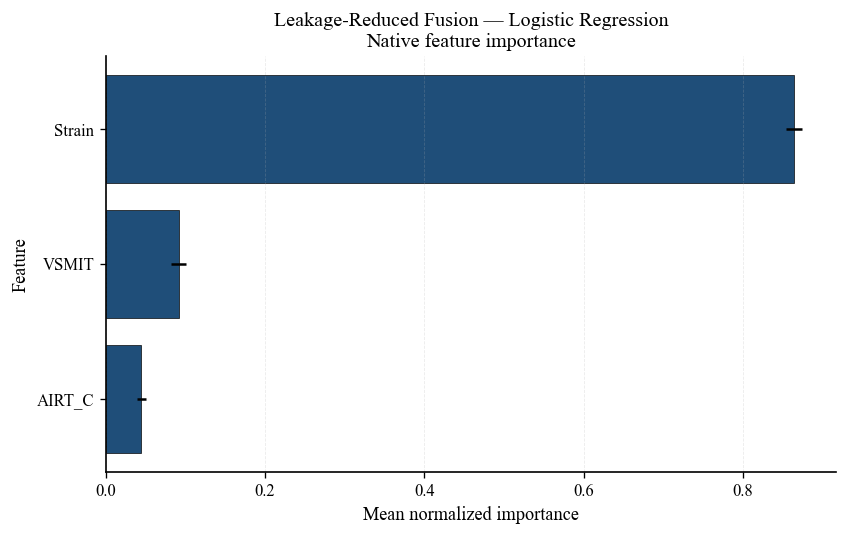

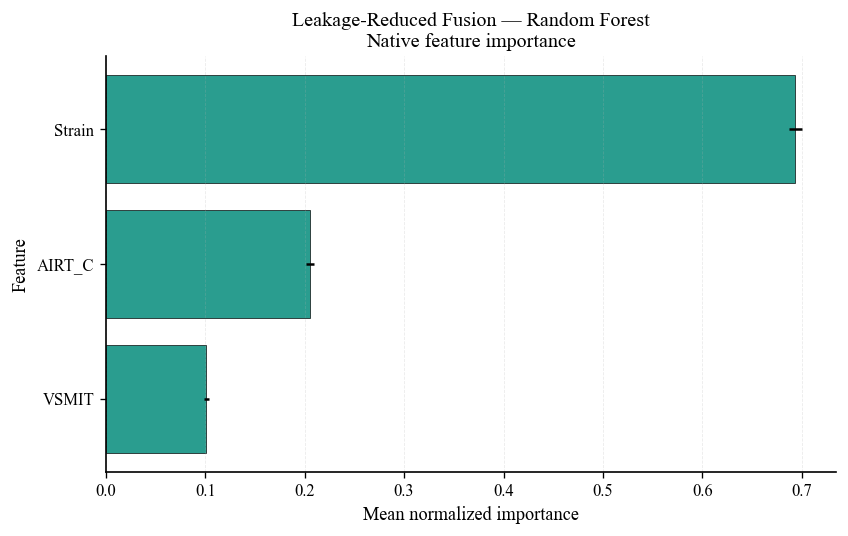

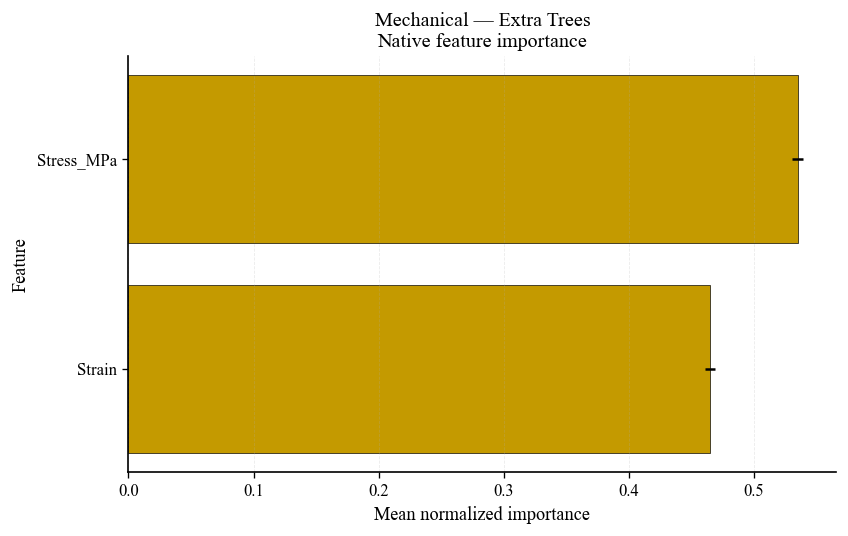

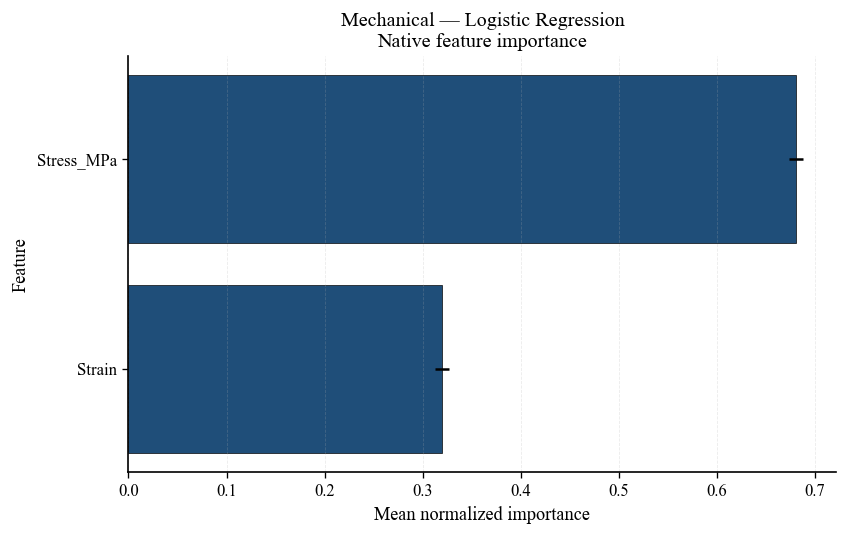

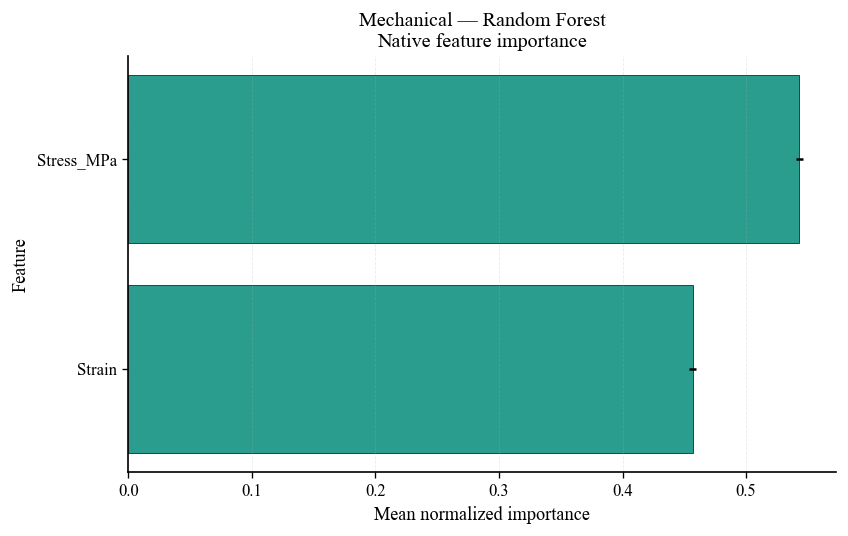

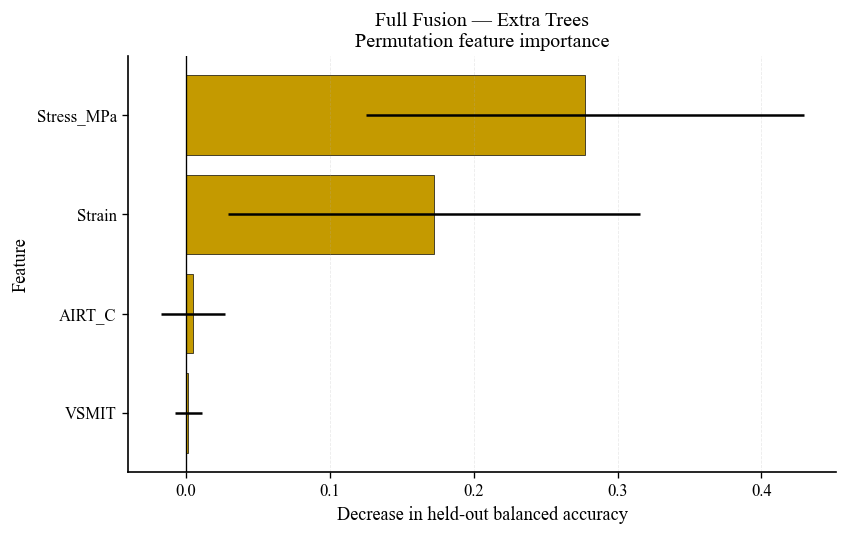

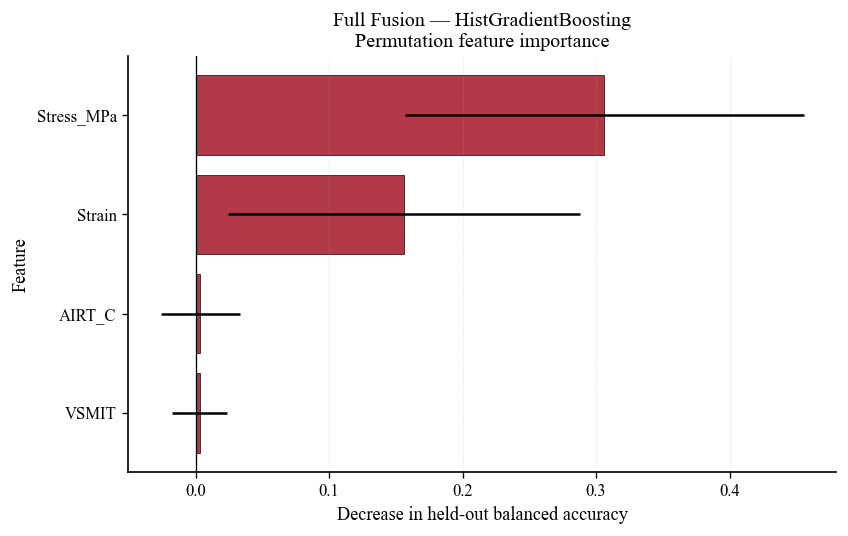

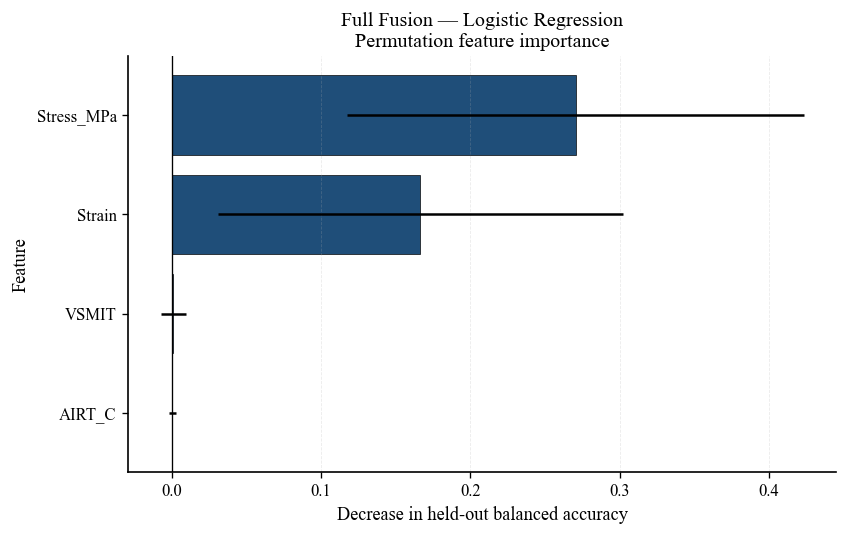

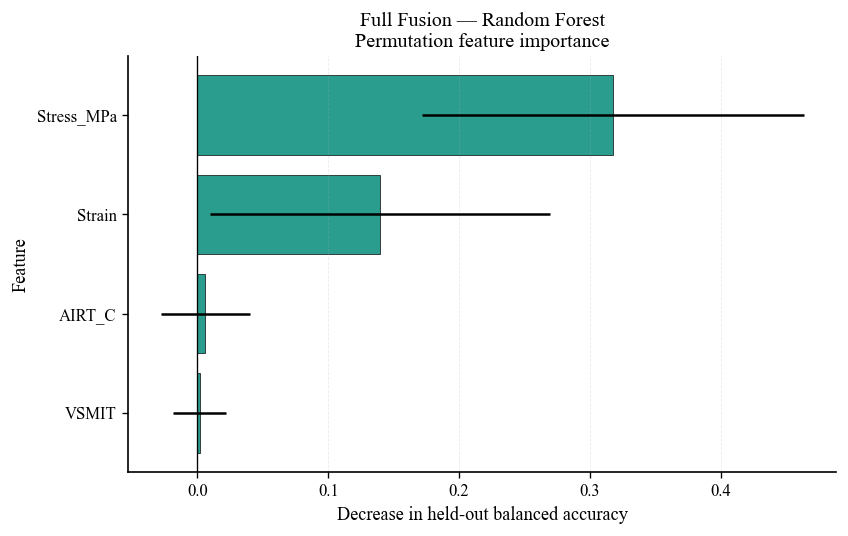

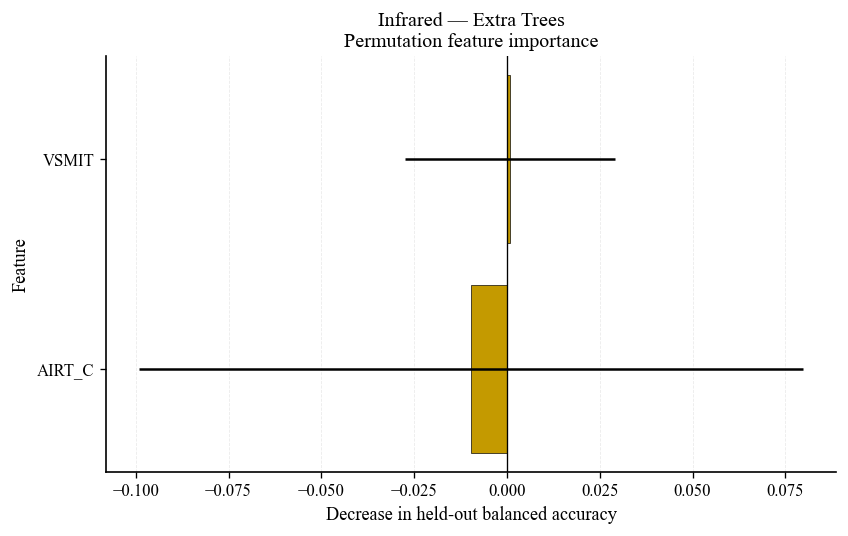

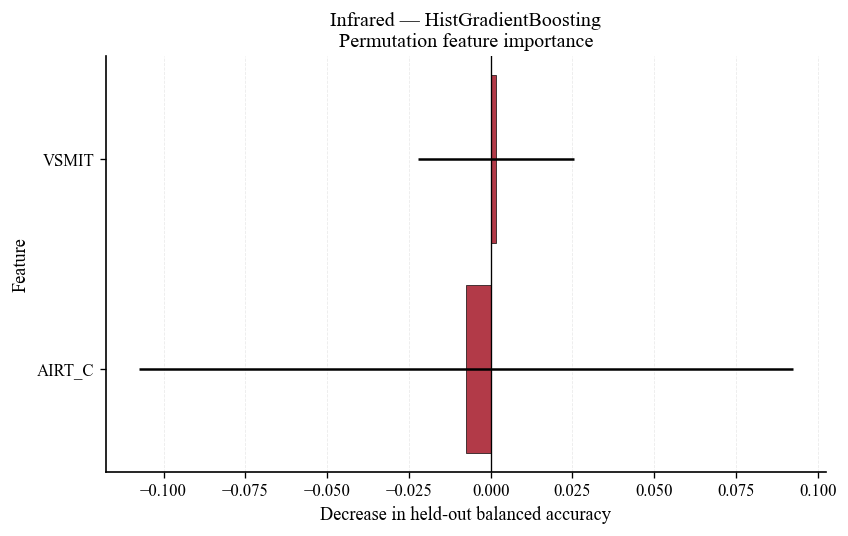

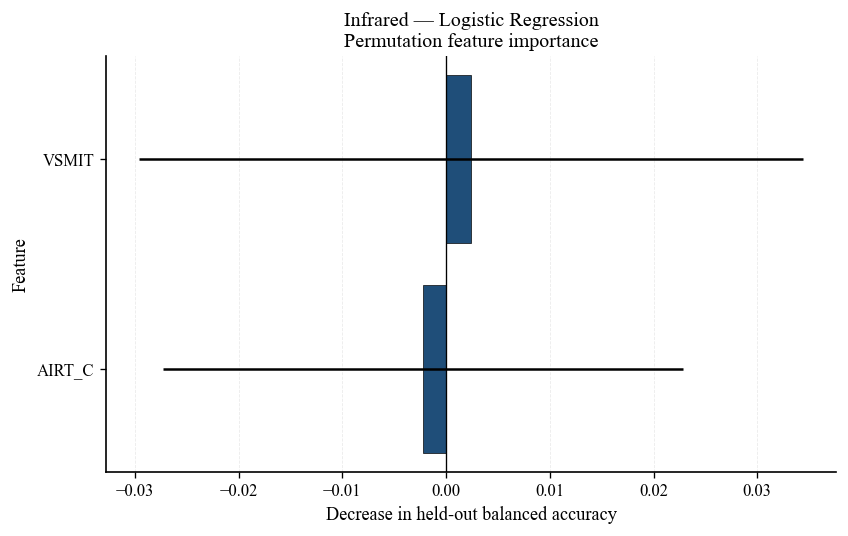

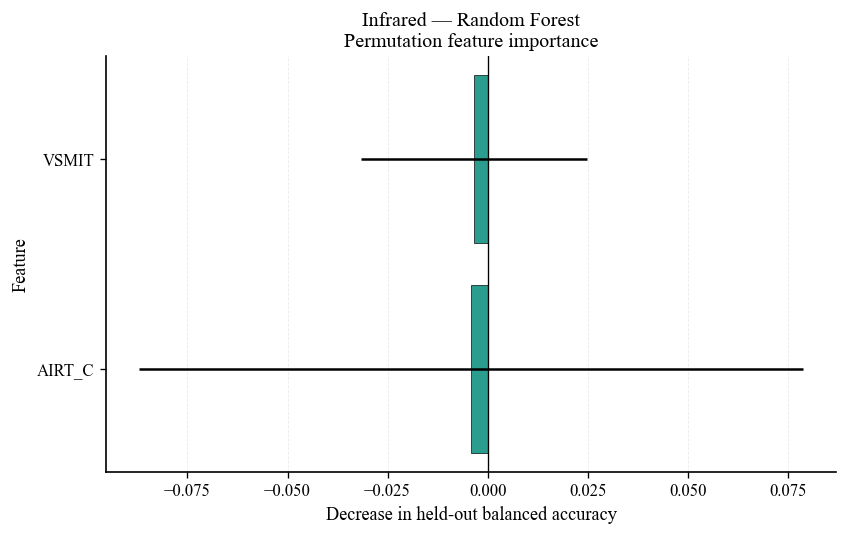

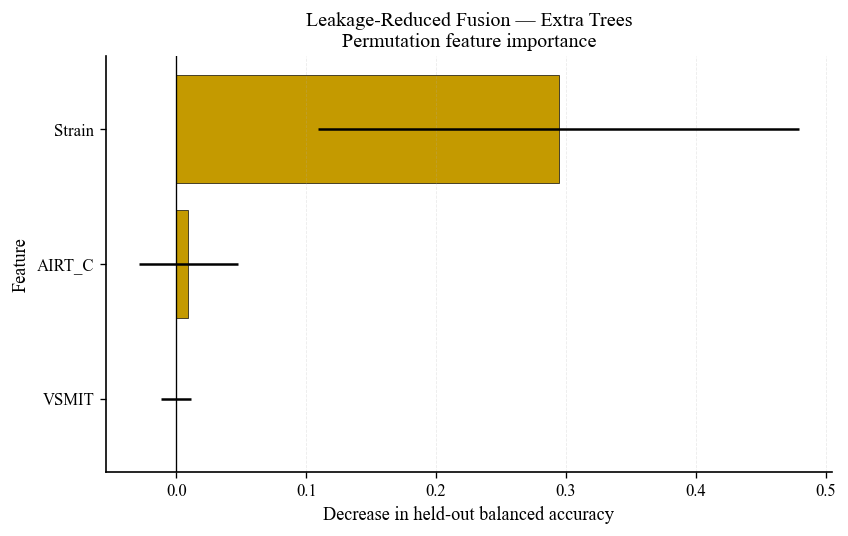

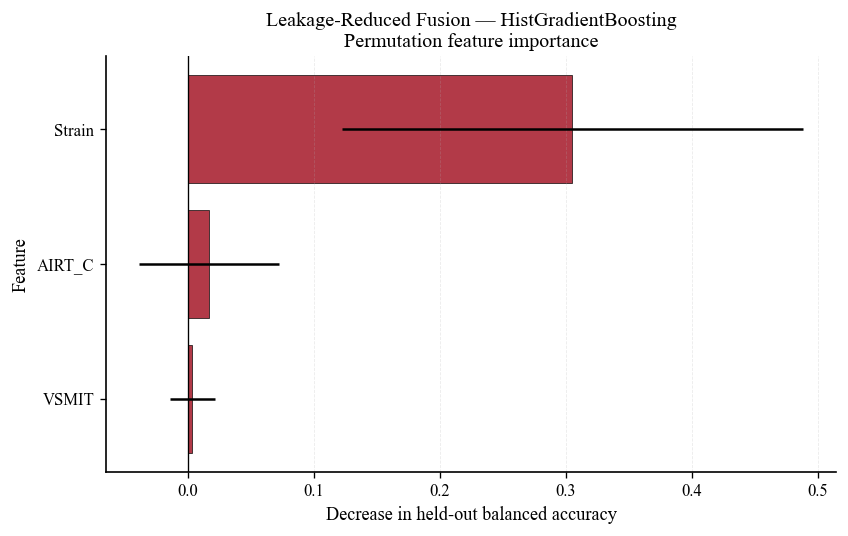

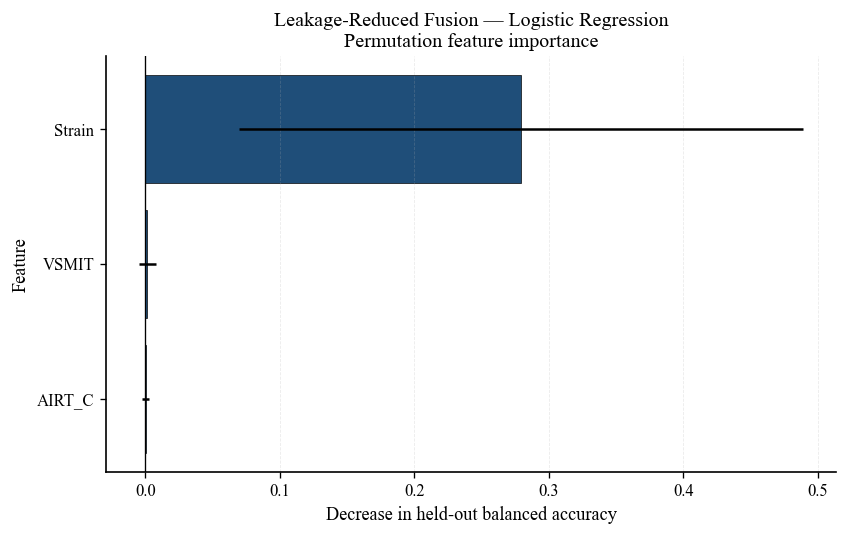

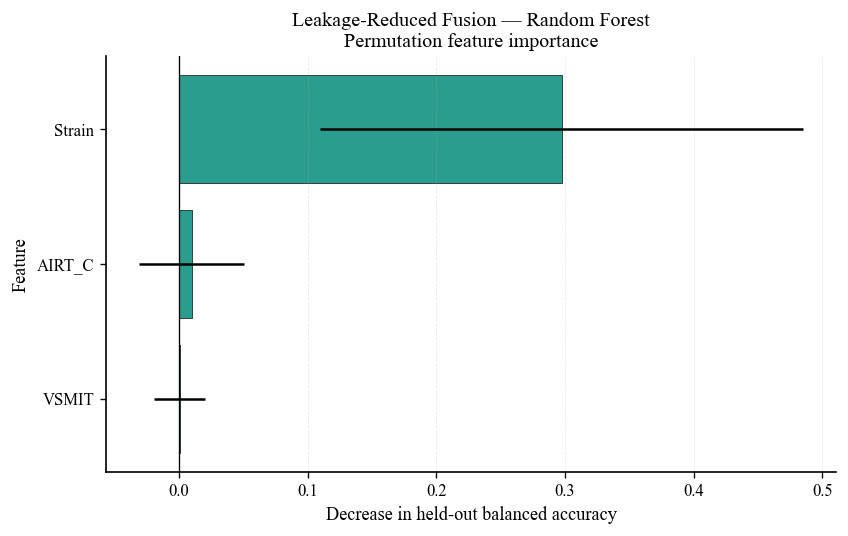

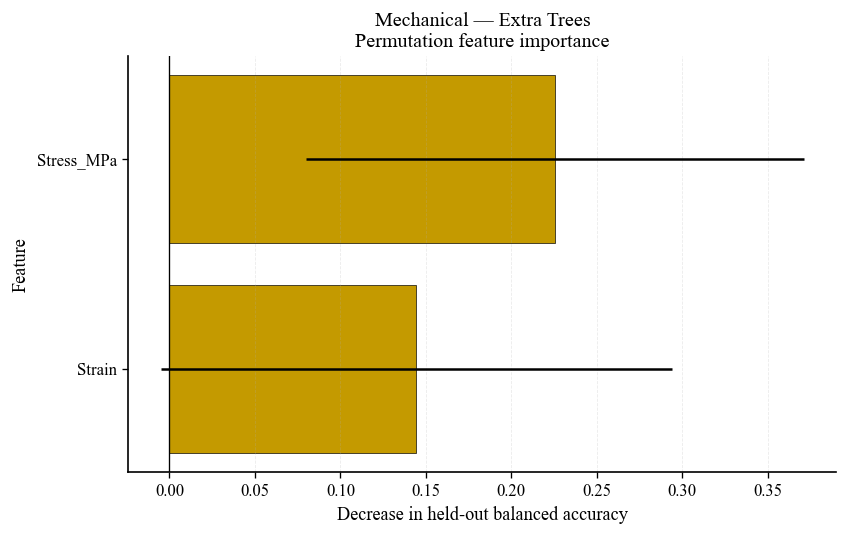

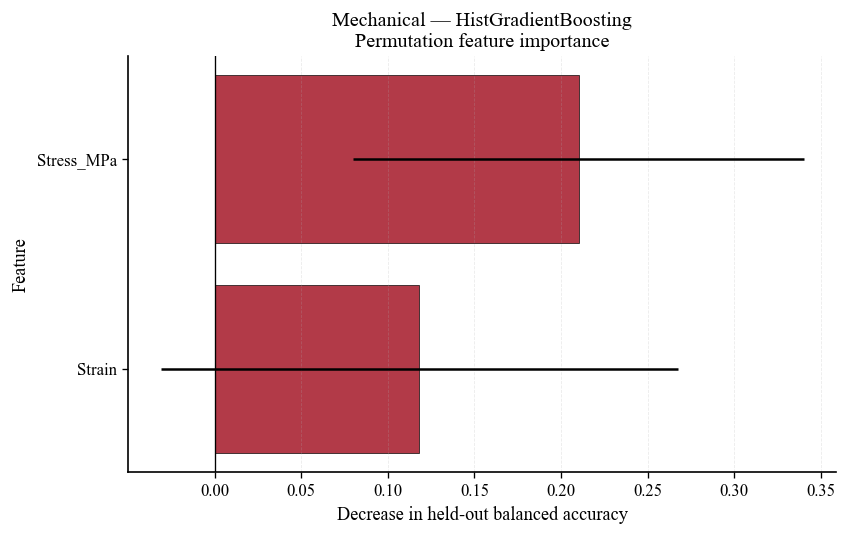

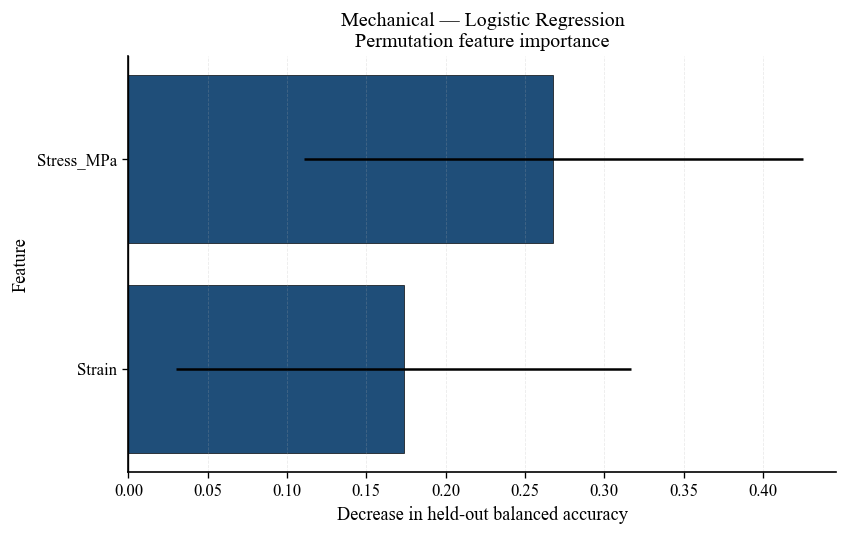

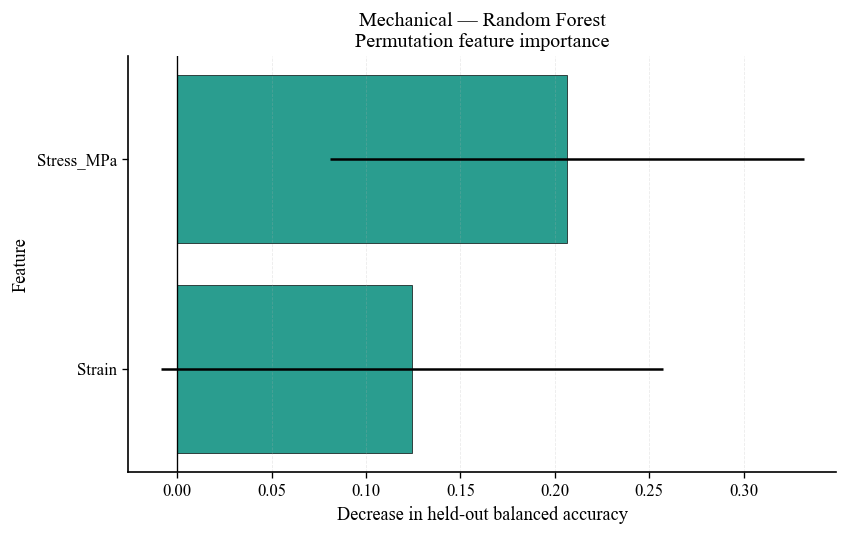

Importance figures regenerated successfully.


In [18]:
# ============================================================
# OPTIONAL: regenerate model-specific importance figures
# ============================================================

if "safe_name" not in globals():
    def safe_name(text):
        return (
            str(text)
            .replace(" ", "_")
            .replace("-", "_")
            .replace("/", "_")
        )

if not native_importance_summary.empty:
    for (feature_set, model_name), group in native_importance_summary.groupby(
        ["Feature_Set", "Model"]
    ):
        plot_data = group.sort_values("Mean_Importance", ascending=True)

        fig, ax = plt.subplots(figsize=(7.2, 4.6))

        ax.barh(
            plot_data["Feature"],
            plot_data["Mean_Importance"],
            xerr=plot_data["SD_Importance"].fillna(0),
            color=MODEL_COLORS[model_name],
            edgecolor="black",
            linewidth=0.4
        )

        ax.set_xlabel("Mean normalized importance")
        ax.set_ylabel("Feature")
        ax.set_title(
            f"{feature_set} — {model_name}\nNative feature importance"
        )
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.25)

        save_figure(
            fig,
            f"native_importance_{safe_name(feature_set)}",
            model_name=model_name
        )
        plt.show()

for (feature_set, model_name), group in permutation_importance_summary.groupby(
    ["Feature_Set", "Model"]
):
    plot_data = group.sort_values("Mean_Importance", ascending=True)

    fig, ax = plt.subplots(figsize=(7.2, 4.6))

    ax.barh(
        plot_data["Feature"],
        plot_data["Mean_Importance"],
        xerr=plot_data["SD_Importance"].fillna(0),
        color=MODEL_COLORS[model_name],
        edgecolor="black",
        linewidth=0.4
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Decrease in held-out balanced accuracy")
    ax.set_ylabel("Feature")
    ax.set_title(
        f"{feature_set} — {model_name}\nPermutation feature importance"
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.25)

    save_figure(
        fig,
        f"permutation_importance_{safe_name(feature_set)}",
        model_name=model_name
    )
    plt.show()

print("Importance figures regenerated successfully.")


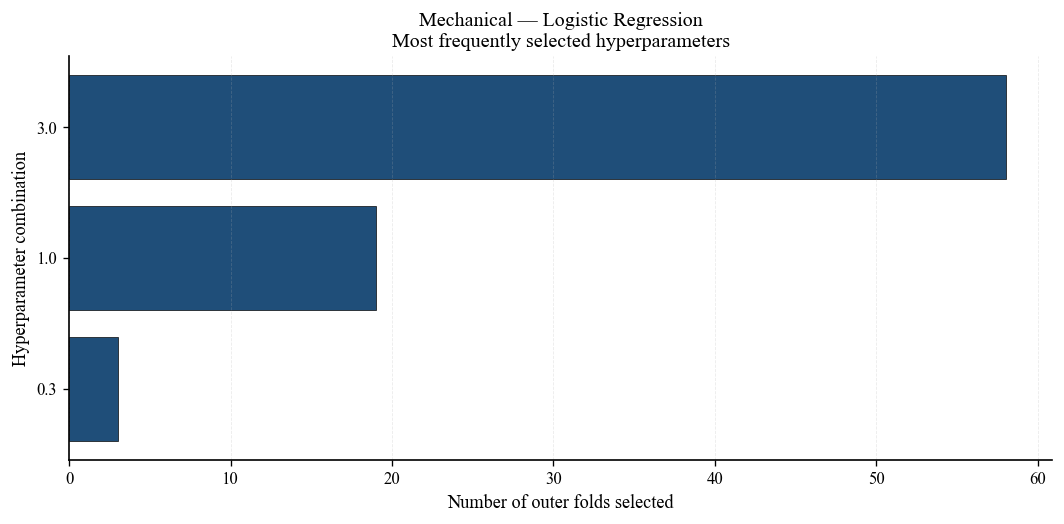

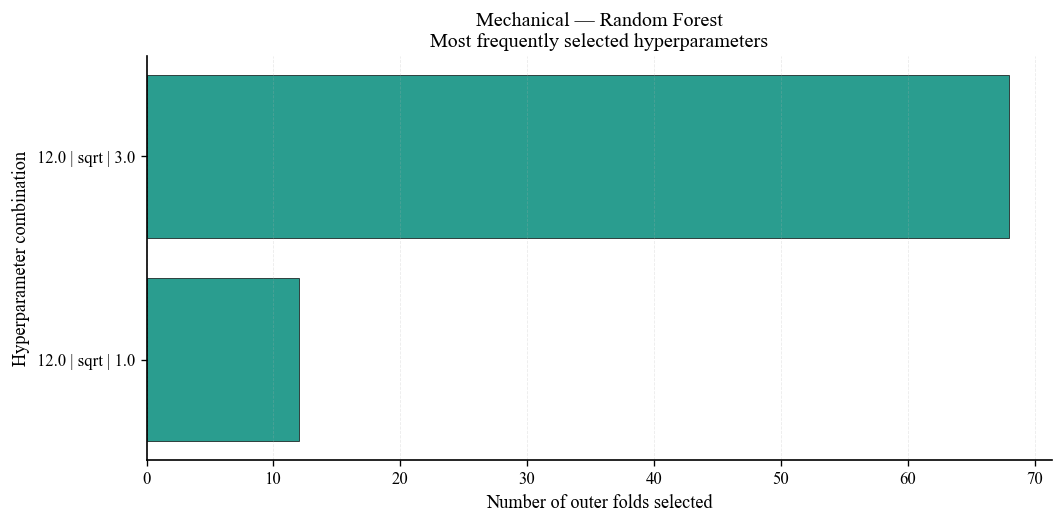

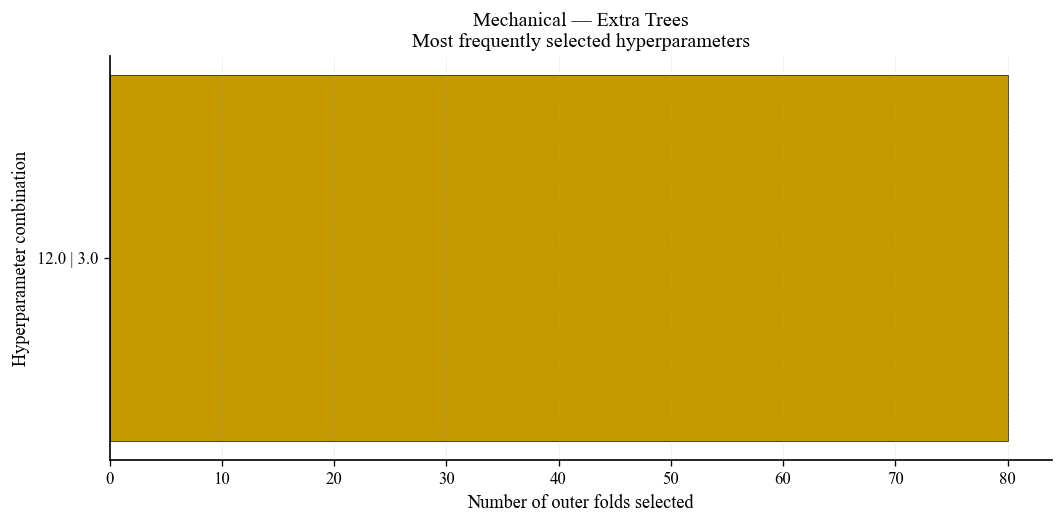

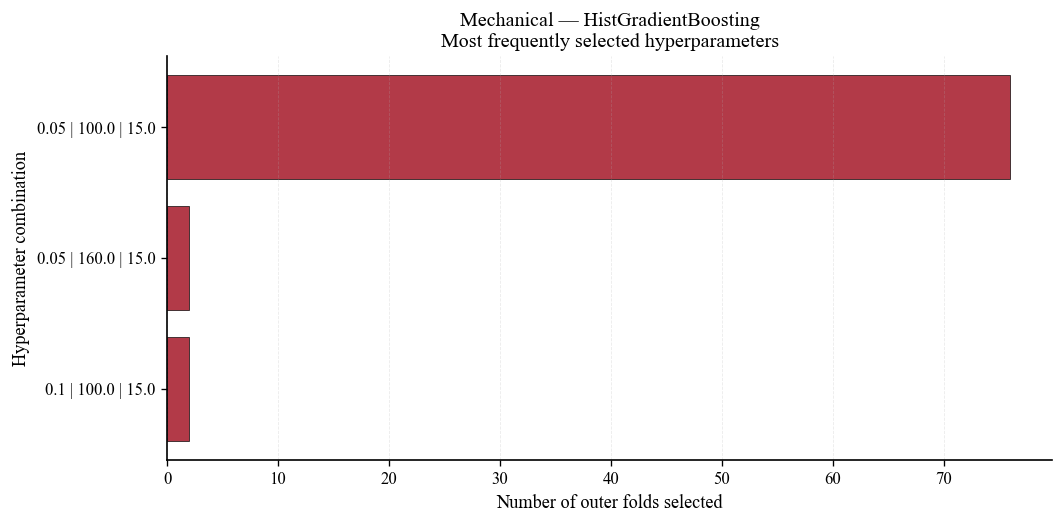

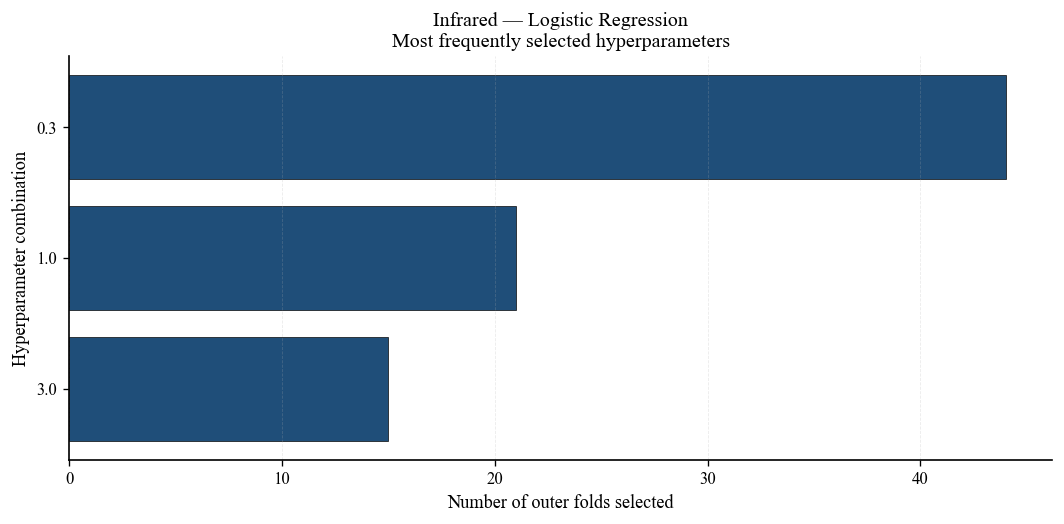

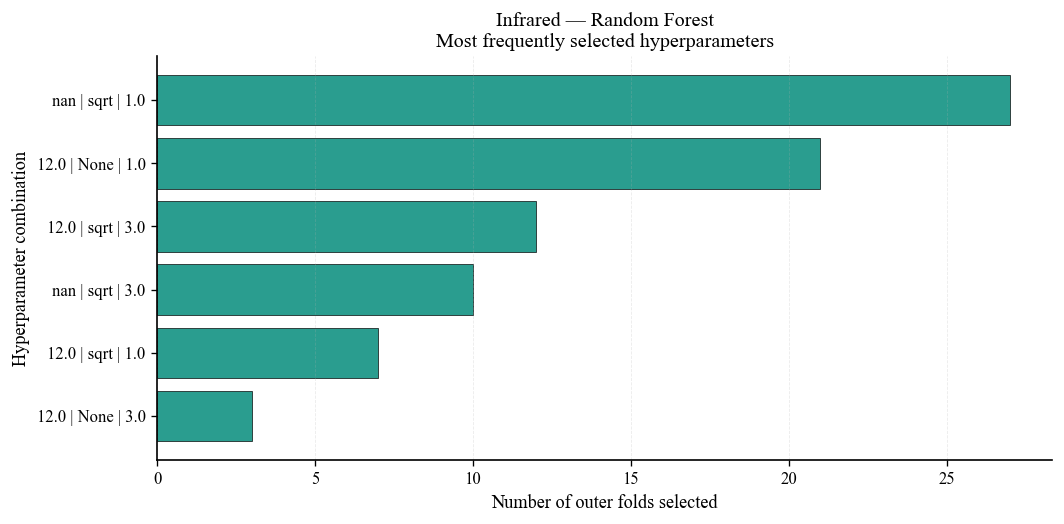

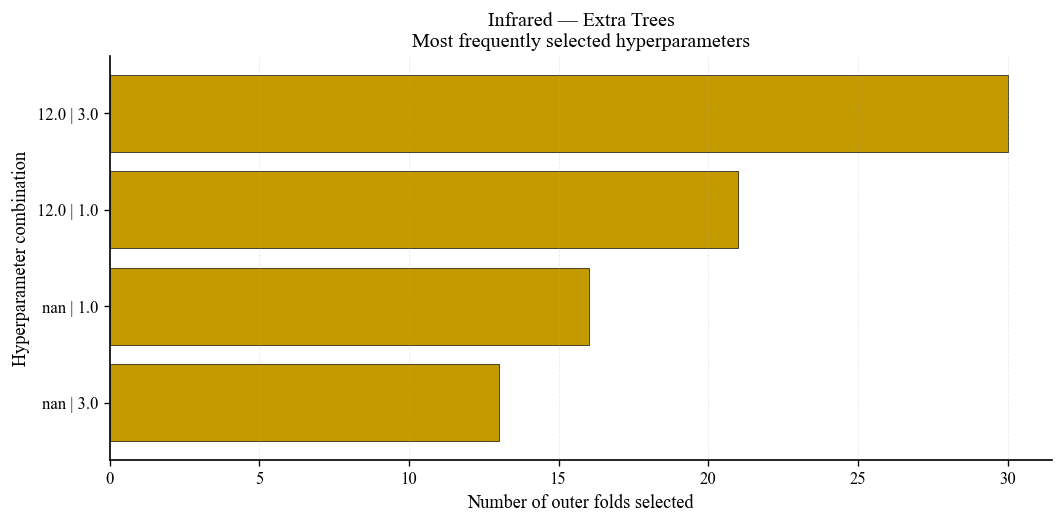

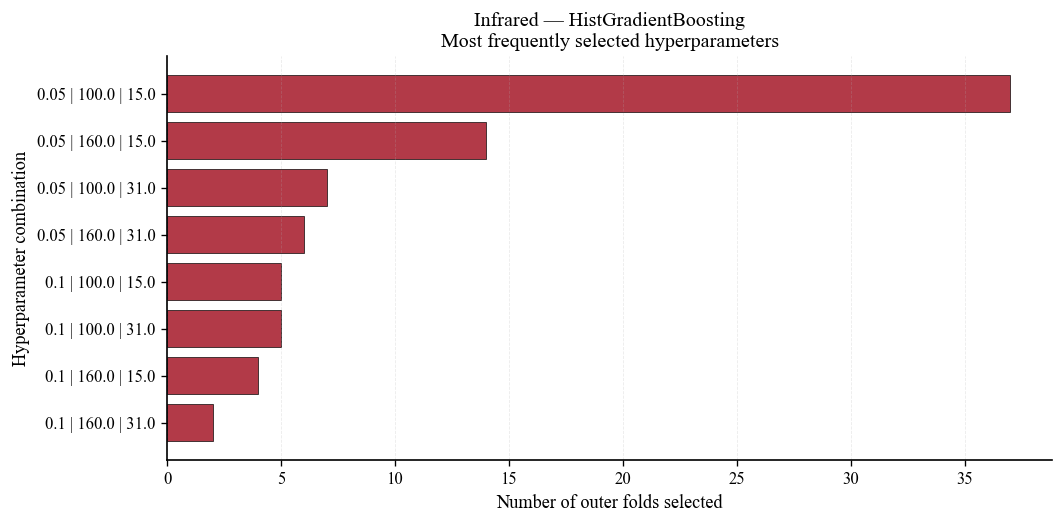

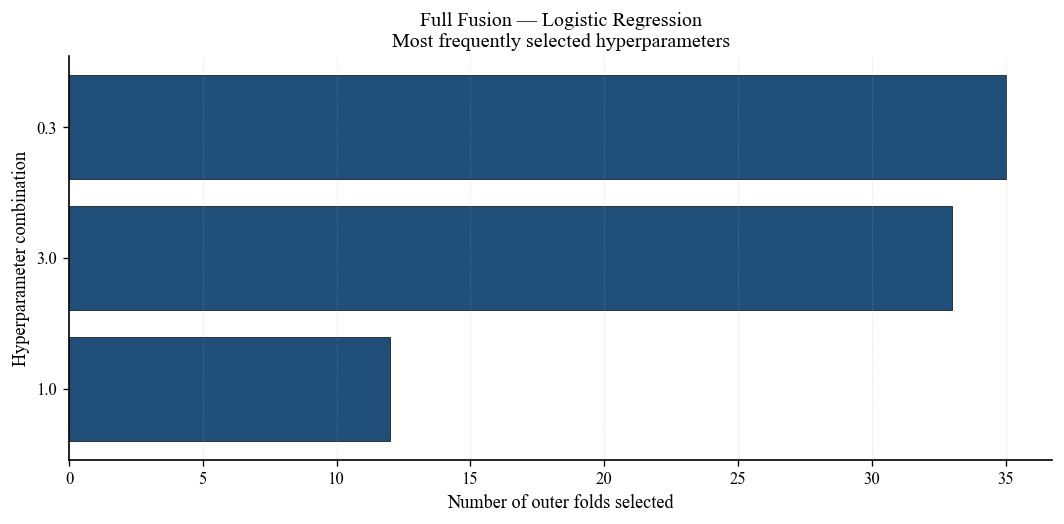

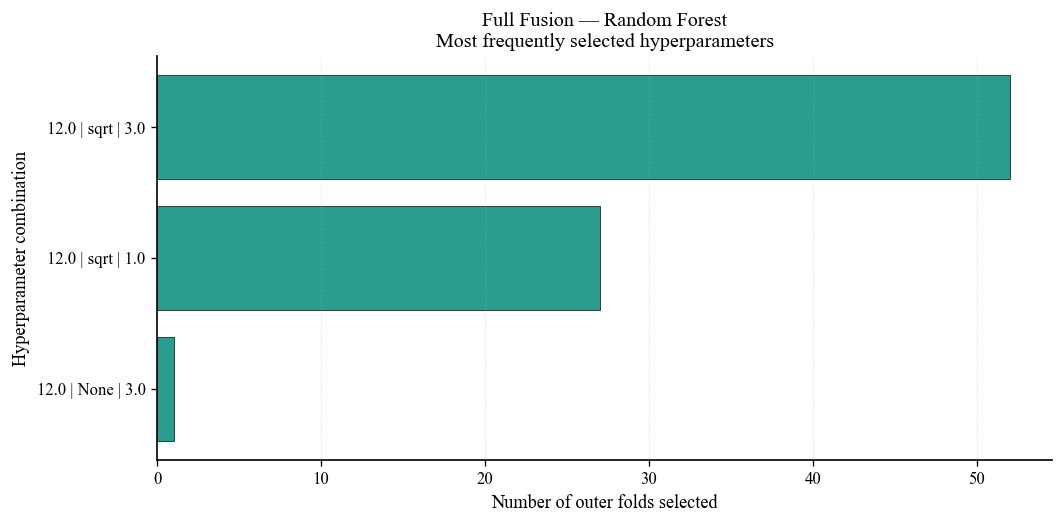

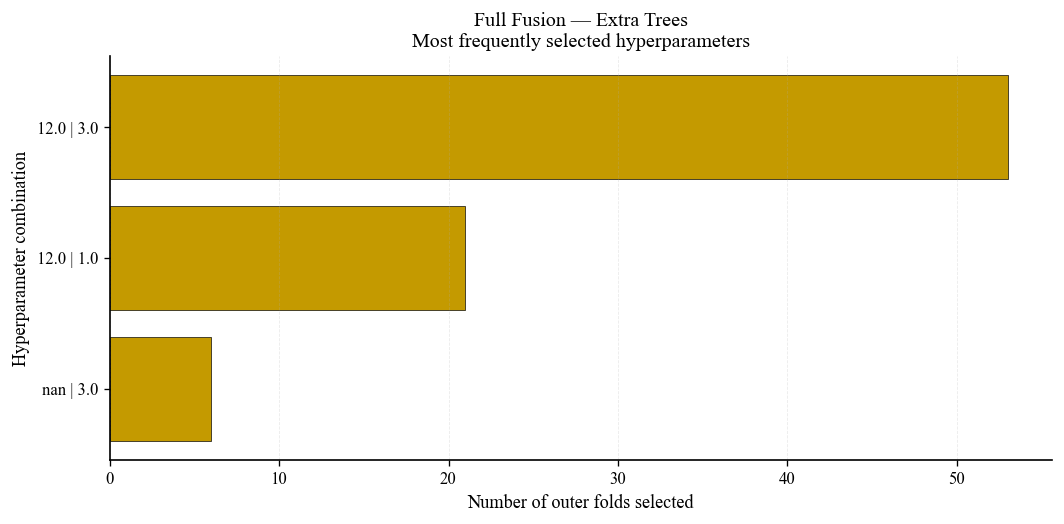

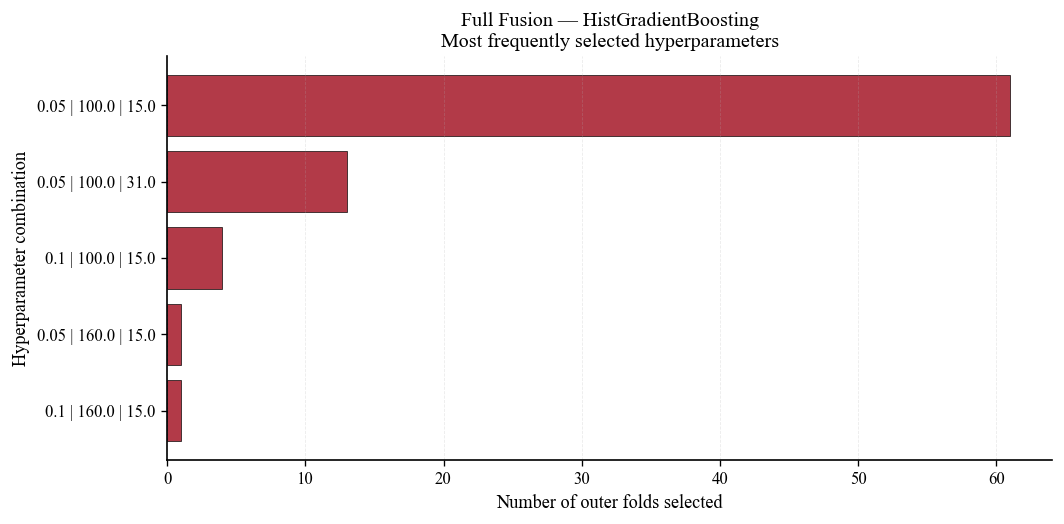

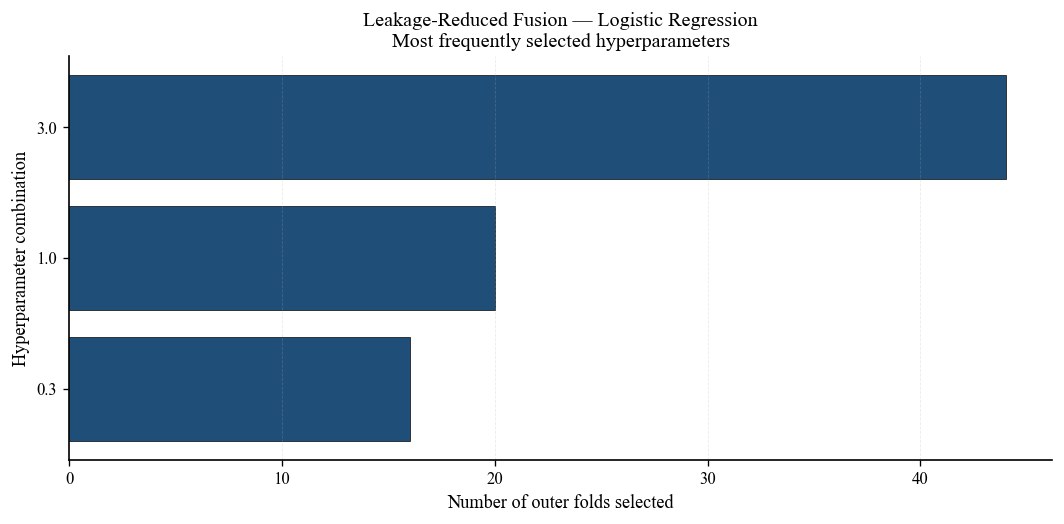

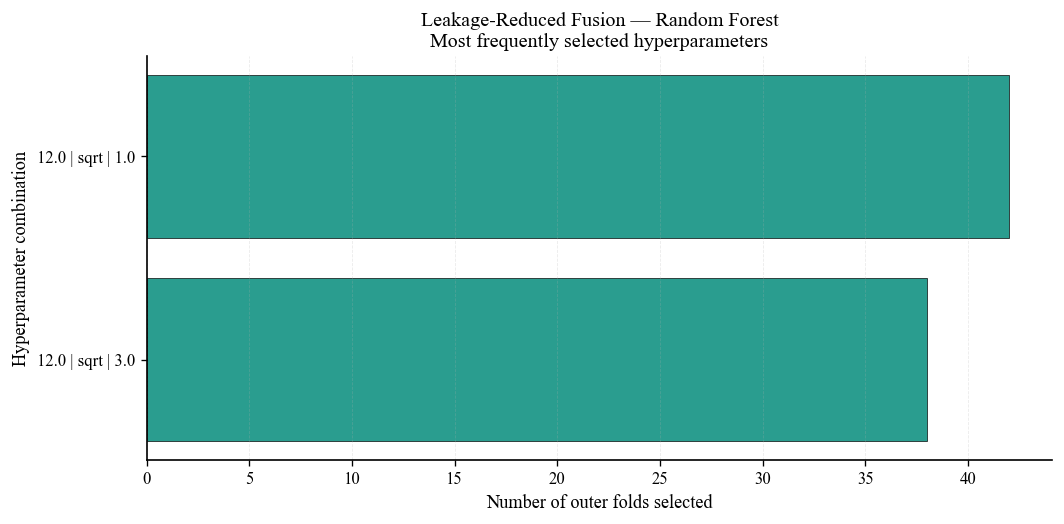

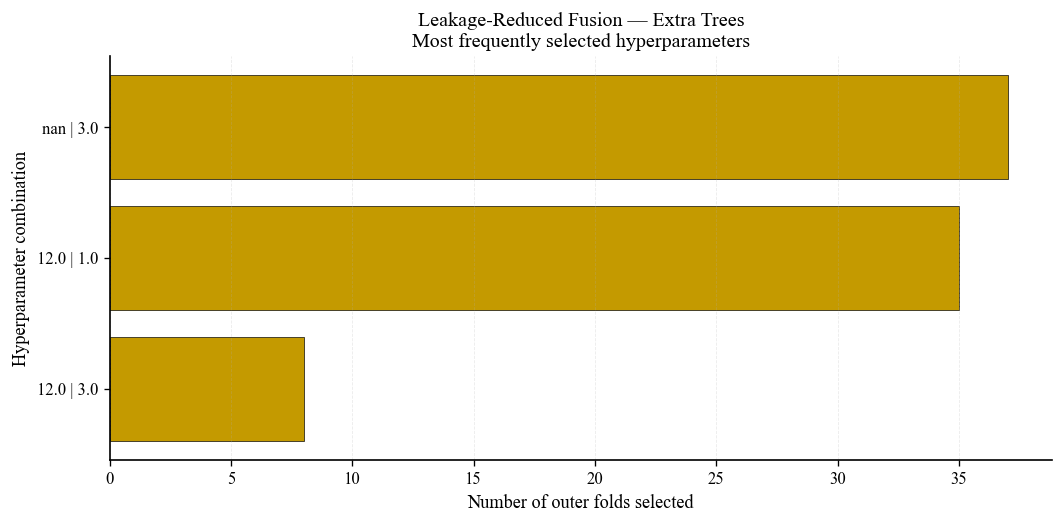

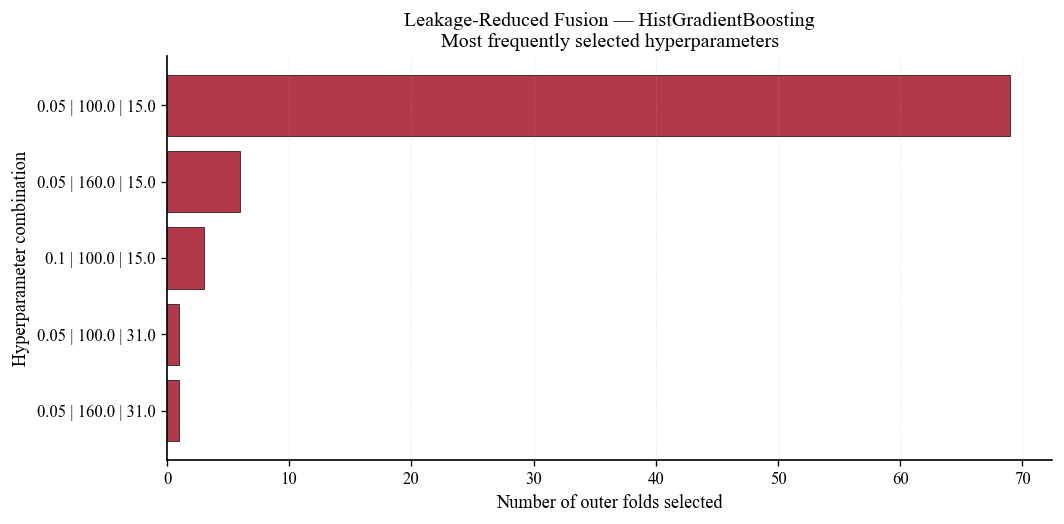

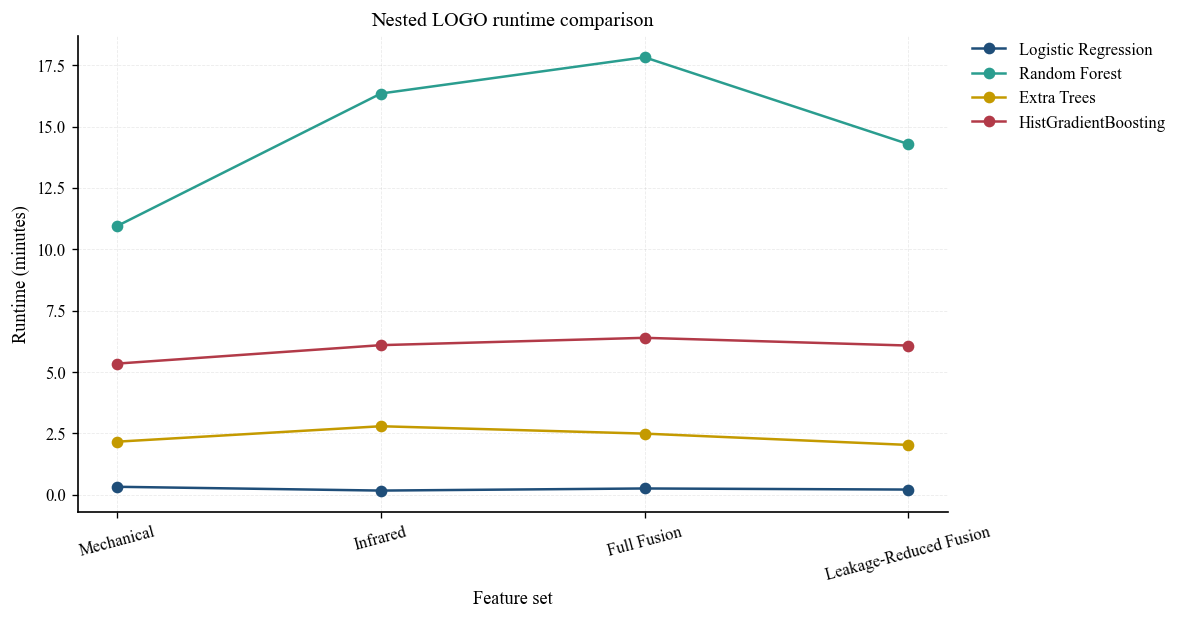

In [19]:
# ============================================================
# 17. Hyperparameter selection and runtime graphs
# ============================================================

parameter_columns = [
    column for column in tuning_summary.columns
    if column.startswith("model__")
]

for feature_set in FEATURE_SETS:
    for model_name in MODEL_SPECS:
        subset = tuning_summary.loc[
            (tuning_summary["Feature_Set"] == feature_set) &
            (tuning_summary["Model"] == model_name)
        ].copy()

        active_parameters = [
            column for column in parameter_columns
            if column in subset.columns and subset[column].notna().any()
        ]

        if subset.empty or not active_parameters:
            continue

        combinations = subset[active_parameters].astype(str).agg(
            " | ".join,
            axis=1
        )
        counts = combinations.value_counts().head(10)

        fig, ax = plt.subplots(
            figsize=(9.0, max(4.5, 0.45 * len(counts)))
        )

        ax.barh(
            counts.index[::-1],
            counts.values[::-1],
            color=MODEL_COLORS[model_name],
            edgecolor="black",
            linewidth=0.4
        )

        ax.set_xlabel("Number of outer folds selected")
        ax.set_ylabel("Hyperparameter combination")
        ax.set_title(
            f"{feature_set} — {model_name}\n"
            "Most frequently selected hyperparameters"
        )
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(axis="x", linestyle="--", linewidth=0.5, alpha=0.25)

        safe_feature = feature_set.replace(" ", "_").replace("-", "_")
        safe_model = model_name.replace(" ", "_")

        save_figure(
            fig,
            f"Figure_09_tuning_frequency_{safe_feature}_{safe_model}"
        )
        plt.show()

runtime_plot = runtime_summary.copy()
runtime_plot["Runtime_Minutes"] = runtime_plot["Runtime_Seconds"] / 60.0

fig, ax = plt.subplots(figsize=(10.0, 5.3))

for model_name in MODEL_SPECS:
    subset = runtime_plot.loc[
        runtime_plot["Model"] == model_name
    ]

    ax.plot(
        subset["Feature_Set"],
        subset["Runtime_Minutes"],
        marker="o",
        color=MODEL_COLORS[model_name],
        label=model_name
    )

ax.set_xlabel("Feature set")
ax.set_ylabel("Runtime (minutes)")
ax.set_title("Nested LOGO runtime comparison")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(linestyle="--", linewidth=0.5, alpha=0.25)
ax.legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0
)
plt.xticks(rotation=15)

save_figure(fig, "Figure_10_runtime_comparison")
plt.show()


In [20]:
# ============================================================
# 18. Final grouped fit and model saving
# ============================================================

import joblib

final_records = []

for feature_set_name, feature_names in FEATURE_SETS.items():
    X = model_data[feature_names]
    y = model_data["Failure_Stage_Code"].to_numpy()
    groups = model_data["Sample_ID"].astype(str).to_numpy()

    final_cv = GroupKFold(
        n_splits=min(5, model_data["Sample_ID"].nunique())
    )

    for model_name, model_spec in MODEL_SPECS.items():
        search = GridSearchCV(
            estimator=clone(model_spec["pipeline"]),
            param_grid=model_spec["param_grid"],
            scoring="f1_macro",
            cv=final_cv,
            n_jobs=N_JOBS,
            refit=True,
            error_score="raise"
        )

        search.fit(X, y, groups=groups)

        safe_feature = feature_set_name.replace(" ", "_").replace("-", "_")
        safe_model = model_name.replace(" ", "_")

        model_file = (
            MODEL_DIR /
            f"final_{safe_feature}_{safe_model}.joblib"
        )
        joblib.dump(
            search.best_estimator_,
            model_file
        )

        parameter_file = (
            TUNING_DIR /
            f"final_best_parameters_{safe_feature}_{safe_model}.json"
        )

        with open(
            parameter_file,
            "w",
            encoding="utf-8"
        ) as file:
            json.dump(
                {
                    key: (
                        value.item()
                        if isinstance(value, np.generic)
                        else value
                    )
                    for key, value in search.best_params_.items()
                },
                file,
                indent=2
            )

        final_records.append({
            "Feature_Set": feature_set_name,
            "Model": model_name,
            "Grouped_CV_Macro_F1": search.best_score_,
            "Saved_Model": str(model_file),
            **search.best_params_
        })

final_model_summary = pd.DataFrame(final_records)

final_model_summary.to_csv(
    TABLE_DIR / "final_fitted_model_summary.csv",
    index=False
)

display(final_model_summary)


,Feature_Set,Model,Grouped_CV_Macro_F1,Saved_Model,model__C,model__max_depth,model__max_features,model__min_samples_leaf,model__learning_rate,model__max_iter,model__max_leaf_nodes
0,Mechanical,Logistic Regression,0.618723,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,Mechanical,Random Forest,0.547748,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,NaN,12.0,sqrt,3.0,NaN,NaN,NaN
2,Mechanical,Extra Trees,0.573672,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,NaN,12.0,NaN,3.0,NaN,NaN,NaN
3,Mechanical,HistGradientBoosting,0.551889,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,NaN,NaN,NaN,NaN,0.10,100.0,15.0
4,Infrared,Logistic Regression,0.209935,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,1.0,NaN,NaN,NaN,NaN,NaN,NaN
5,Infrared,Random Forest,0.247000,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,NaN,NaN,None,3.0,NaN,NaN,NaN
6,Infrared,Extra Trees,0.239901,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,NaN,NaN,NaN,1.0,NaN,NaN,NaN
7,Infrared,HistGradientBoosting,0.234312,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,NaN,NaN,NaN,NaN,0.05,100.0,31.0
8,Full Fusion,Logistic Regression,0.619054,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,3.0,NaN,NaN,NaN,NaN,NaN,NaN
9,Full Fusion,Random Forest,0.660231,C:\Users\Eddie\Desktop\new_exp_june\Project_Di...,NaN,12.0,sqrt,3.0,NaN,NaN,NaN


In [21]:
# ============================================================
# 19. Final summary
# ============================================================

best_result = overall_metrics.sort_values(
    "Macro_F1",
    ascending=False
).iloc[0]

summary = {
    "outer_validation": "LeaveOneGroupOut by Sample_ID",
    "outer_test_unit": "One complete specimen",
    "inner_tuning": f"GroupKFold with up to {INNER_GROUP_FOLDS} folds",
    "independent_specimens": int(model_data["Sample_ID"].nunique()),
    "sampled_rows": int(len(model_data)),
    "models": list(MODEL_SPECS.keys()),
    "feature_sets": list(FEATURE_SETS.keys()),
    "best_feature_set": best_result["Feature_Set"],
    "best_model": best_result["Model"],
    "best_macro_f1": float(best_result["Macro_F1"]),
    "best_macro_auc": float(best_result["Macro_ROC_AUC_OVR"]),
    "output_directory": str(OUTPUT_DIR)
}

print(json.dumps(summary, indent=2))


{
  "outer_validation": "LeaveOneGroupOut by Sample_ID",
  "outer_test_unit": "One complete specimen",
  "inner_tuning": "GroupKFold with up to 3 folds",
  "independent_specimens": 80,
  "sampled_rows": 23995,
  "models": [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees",
    "HistGradientBoosting"
  ],
  "feature_sets": [
    "Mechanical",
    "Infrared",
    "Full Fusion",
    "Leakage-Reduced Fusion"
  ],
  "best_feature_set": "Full Fusion",
  "best_model": "HistGradientBoosting",
  "best_macro_f1": 0.6614485356910526,
  "best_macro_auc": 0.8790263321363503,
  "output_directory": "C:\\Users\\Eddie\\Desktop\\new_exp_june\\Project_Dir\\modeling_outputs_LOGO_RF_pub"
}


## Publication-strength analyses

The following sections use the already generated LOGO predictions wherever possible. Expensive retraining is limited to the ablation, threshold-sensitivity, and leave-one-condition-out robustness experiments.

In [22]:

# ============================================================
# 20. Publication helper functions
# ============================================================

def safe_name(text):
    return (
        str(text)
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )


def ordinal_metrics(y_true, y_pred):
    """
    Metrics that respect the ordered nature of the four stages.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    absolute_error = np.abs(y_true - y_pred)

    return {
        "Mean_Absolute_Stage_Error": float(np.mean(absolute_error)),
        "Median_Absolute_Stage_Error": float(np.median(absolute_error)),
        "Within_One_Stage_Accuracy": float(np.mean(absolute_error <= 1)),
        "Exact_Stage_Accuracy": float(np.mean(absolute_error == 0)),
        "Adjacent_Error_Rate": float(np.mean(absolute_error == 1)),
        "Non_Adjacent_Error_Rate": float(np.mean(absolute_error >= 2)),
        "Quadratic_Weighted_Kappa": float(
            cohen_kappa_score(
                y_true,
                y_pred,
                weights="quadratic"
            )
        )
    }


def specimen_bootstrap_confidence_intervals(
    prediction_table,
    iterations=2000,
    random_state=42
):
    """
    Resample complete specimens with replacement.
    Rows within a selected specimen remain together.
    """
    rng = np.random.default_rng(random_state)
    specimen_ids = prediction_table["Sample_ID"].astype(str).unique()

    records = []

    for bootstrap_index in range(iterations):
        selected = rng.choice(
            specimen_ids,
            size=len(specimen_ids),
            replace=True
        )

        bootstrap_parts = []

        for draw_number, specimen_id in enumerate(selected):
            specimen_rows = prediction_table.loc[
                prediction_table["Sample_ID"].astype(str) == specimen_id
            ].copy()

            # Preserve repeated specimens as independent bootstrap draws.
            specimen_rows["_Bootstrap_Draw"] = draw_number
            bootstrap_parts.append(specimen_rows)

        bootstrap_data = pd.concat(
            bootstrap_parts,
            ignore_index=True
        )

        y_true = bootstrap_data["True_Code"].to_numpy()
        y_pred = bootstrap_data["Predicted_Code"].to_numpy()

        probability_columns = [
            f"Probability_{stage}"
            for stage in STAGE_ORDER
        ]
        probabilities = bootstrap_data[
            probability_columns
        ].to_numpy()

        standard_metrics = calculate_metrics(
            y_true,
            y_pred,
            probabilities
        )
        ordered_metrics = ordinal_metrics(
            y_true,
            y_pred
        )

        records.append({
            "Bootstrap_Iteration": bootstrap_index + 1,
            **standard_metrics,
            **ordered_metrics
        })

    return pd.DataFrame(records)


def summarize_bootstrap(bootstrap_table):
    metric_columns = [
        column for column in bootstrap_table.columns
        if column != "Bootstrap_Iteration"
    ]

    rows = []

    for metric in metric_columns:
        values = bootstrap_table[metric].dropna().to_numpy()

        rows.append({
            "Metric": metric,
            "Bootstrap_Mean": float(np.mean(values)),
            "Bootstrap_SD": float(np.std(values, ddof=1)),
            "CI_2.5_Percent": float(np.quantile(values, 0.025)),
            "CI_97.5_Percent": float(np.quantile(values, 0.975))
        })

    return pd.DataFrame(rows)


def nested_logo_predictions_for_configuration(
    input_data,
    feature_names,
    model_name,
    target_column="Failure_Stage_Code",
    group_column="Sample_ID"
):
    """
    Strict nested Leave-One-Group-Out evaluation for one feature set/model.
    """
    X_all = input_data[feature_names].copy()
    y_all = input_data[target_column].to_numpy()
    groups_all = input_data[group_column].astype(str).to_numpy()

    outer_cv_local = LeaveOneGroupOut()
    prediction_rows = []
    fold_rows = []

    model_spec = MODEL_SPECS[model_name]

    for fold_number, (train_index, test_index) in enumerate(
        outer_cv_local.split(X_all, y_all, groups_all),
        start=1
    ):
        X_train = X_all.iloc[train_index]
        X_test = X_all.iloc[test_index]
        y_train = y_all[train_index]
        y_test = y_all[test_index]
        groups_train = groups_all[train_index]

        unique_train_groups = np.unique(groups_train)
        inner_splits = min(
            INNER_GROUP_FOLDS,
            len(unique_train_groups)
        )

        inner_cv = GroupKFold(
            n_splits=max(2, inner_splits)
        )

        search = GridSearchCV(
            estimator=clone(model_spec["pipeline"]),
            param_grid=model_spec["param_grid"],
            scoring="f1_macro",
            cv=inner_cv,
            n_jobs=N_JOBS,
            refit=True,
            error_score="raise"
        )

        search.fit(
            X_train,
            y_train,
            groups=groups_train
        )

        estimator = search.best_estimator_
        y_pred = estimator.predict(X_test)

        if hasattr(estimator, "predict_proba"):
            raw_probabilities = estimator.predict_proba(X_test)
            estimator_classes = estimator.classes_.astype(int)

            probabilities = np.zeros(
                (len(X_test), len(STAGE_CODES)),
                dtype=float
            )

            for local_index, class_code in enumerate(estimator_classes):
                probabilities[:, class_code] = raw_probabilities[:, local_index]
        else:
            probabilities = np.full(
                (len(X_test), len(STAGE_CODES)),
                np.nan
            )

        fold_metric_values = calculate_metrics(
            y_test,
            y_pred,
            probabilities
        )
        fold_metric_values.update(
            ordinal_metrics(y_test, y_pred)
        )

        fold_rows.append({
            "Fold": fold_number,
            "Held_Out_Sample": groups_all[test_index][0],
            "Model": model_name,
            **fold_metric_values
        })

        for row_position, source_index in enumerate(test_index):
            record = {
                "Fold": fold_number,
                "Sample_ID": groups_all[source_index],
                "Time_s": input_data.iloc[source_index]["Time_s"],
                "True_Code": int(y_all[source_index]),
                "Predicted_Code": int(y_pred[row_position]),
                "Model": model_name
            }

            for class_index, stage_name in enumerate(STAGE_ORDER):
                record[f"Probability_{stage_name}"] = (
                    probabilities[row_position, class_index]
                )

            prediction_rows.append(record)

    return (
        pd.DataFrame(prediction_rows),
        pd.DataFrame(fold_rows)
    )


In [23]:

# ============================================================
# 21. Ordinal and transition-error analysis
# ============================================================

ordinal_records = []
transition_records = []

for (feature_set, model_name), group in predictions.groupby(
    ["Feature_Set", "Model"]
):
    y_true = group["True_Code"].to_numpy()
    y_pred = group["Predicted_Code"].to_numpy()

    ordinal_records.append({
        "Feature_Set": feature_set,
        "Model": model_name,
        **ordinal_metrics(y_true, y_pred)
    })

    errors = np.abs(y_true - y_pred)

    transition_records.append({
        "Feature_Set": feature_set,
        "Model": model_name,
        "Total_Observations": len(group),
        "Correct": int(np.sum(errors == 0)),
        "Adjacent_Errors": int(np.sum(errors == 1)),
        "Non_Adjacent_Errors": int(np.sum(errors >= 2)),
        "Correct_Percent": float(100 * np.mean(errors == 0)),
        "Adjacent_Error_Percent": float(100 * np.mean(errors == 1)),
        "Non_Adjacent_Error_Percent": float(100 * np.mean(errors >= 2))
    })

ordinal_results = pd.DataFrame(ordinal_records)
transition_results = pd.DataFrame(transition_records)

ordinal_results.to_excel(
    ORDINAL_DIR / "ordinal_metrics.xlsx",
    index=False
)
transition_results.to_excel(
    ORDINAL_DIR / "transition_error_summary.xlsx",
    index=False
)

for model_name in MODEL_SPECS:
    ordinal_results.loc[
        ordinal_results["Model"] == model_name
    ].to_excel(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        "ordinal_metrics.xlsx",
        index=False
    )

    transition_results.loc[
        transition_results["Model"] == model_name
    ].to_excel(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        "transition_error_summary.xlsx",
        index=False
    )

display(ordinal_results.sort_values(
    "Mean_Absolute_Stage_Error"
))


,Feature_Set,Model,Mean_Absolute_Stage_Error,Median_Absolute_Stage_Error,Within_One_Stage_Accuracy,Exact_Stage_Accuracy,Adjacent_Error_Rate,Non_Adjacent_Error_Rate,Quadratic_Weighted_Kappa
1,Full Fusion,HistGradientBoosting,0.376287,0.0,0.958575,0.668556,0.290019,0.041425,0.815938
3,Full Fusion,Random Forest,0.380454,0.0,0.956158,0.666597,0.289560,0.043842,0.813935
0,Full Fusion,Extra Trees,0.394082,0.0,0.950073,0.659346,0.290727,0.049927,0.800434
2,Full Fusion,Logistic Regression,0.420213,0.0,0.954741,0.628089,0.326651,0.045259,0.794260
14,Mechanical,Logistic Regression,0.425547,0.0,0.947864,0.629673,0.318191,0.052136,0.787708
12,Mechanical,Extra Trees,0.467181,0.0,0.941696,0.594040,0.347656,0.058304,0.757163
13,Mechanical,HistGradientBoosting,0.507064,0.0,0.938237,0.558033,0.380204,0.061763,0.738483
15,Mechanical,Random Forest,0.525735,0.0,0.924526,0.553574,0.370952,0.075474,0.721422
8,Leakage-Reduced Fusion,Extra Trees,0.548948,0.0,0.909606,0.550448,0.359158,0.090394,0.715343
9,Leakage-Reduced Fusion,HistGradientBoosting,0.549448,0.0,0.898479,0.562034,0.336445,0.101521,0.696668


In [24]:

# ============================================================
# 22. Specimen-level bootstrap 95% confidence intervals
# ============================================================

bootstrap_summaries = []
bootstrap_distributions = []

for (feature_set, model_name), group in predictions.groupby(
    ["Feature_Set", "Model"]
):
    print(
        "Bootstrap CI:",
        feature_set,
        "|",
        model_name
    )

    bootstrap_table = specimen_bootstrap_confidence_intervals(
        group,
        iterations=BOOTSTRAP_ITERATIONS,
        random_state=PUBLICATION_RANDOM_STATE
    )

    summary_table = summarize_bootstrap(
        bootstrap_table
    )
    summary_table.insert(
        0,
        "Model",
        model_name
    )
    summary_table.insert(
        0,
        "Feature_Set",
        feature_set
    )

    bootstrap_summaries.append(summary_table)

    bootstrap_table.insert(
        0,
        "Model",
        model_name
    )
    bootstrap_table.insert(
        0,
        "Feature_Set",
        feature_set
    )
    bootstrap_distributions.append(bootstrap_table)

    safe_feature = safe_name(feature_set)

    bootstrap_table.to_csv(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        f"{safe_feature}_specimen_bootstrap_distribution.csv",
        index=False
    )

    summary_table.to_excel(
        MODEL_OUTPUT_DIRS[model_name]["tables"] /
        f"{safe_feature}_95_percent_confidence_intervals.xlsx",
        index=False
    )

bootstrap_ci_summary = pd.concat(
    bootstrap_summaries,
    ignore_index=True
)
bootstrap_distribution_all = pd.concat(
    bootstrap_distributions,
    ignore_index=True
)

bootstrap_ci_summary.to_excel(
    CI_DIR / "all_model_specimen_bootstrap_95_CI.xlsx",
    index=False
)
bootstrap_distribution_all.to_csv(
    CI_DIR / "all_bootstrap_distributions.csv",
    index=False
)

display(
    bootstrap_ci_summary.loc[
        bootstrap_ci_summary["Metric"].isin([
            "Macro_F1",
            "Balanced_Accuracy",
            "Macro_ROC_AUC_OVR",
            "MCC",
            "Cohen_Kappa",
            "Mean_Absolute_Stage_Error",
            "Quadratic_Weighted_Kappa"
        ])
    ]
)


Bootstrap CI: Full Fusion | Extra Trees
Bootstrap CI: Full Fusion | HistGradientBoosting
Bootstrap CI: Full Fusion | Logistic Regression
Bootstrap CI: Full Fusion | Random Forest
Bootstrap CI: Infrared | Extra Trees
Bootstrap CI: Infrared | HistGradientBoosting
Bootstrap CI: Infrared | Logistic Regression
Bootstrap CI: Infrared | Random Forest
Bootstrap CI: Leakage-Reduced Fusion | Extra Trees
Bootstrap CI: Leakage-Reduced Fusion | HistGradientBoosting
Bootstrap CI: Leakage-Reduced Fusion | Logistic Regression
Bootstrap CI: Leakage-Reduced Fusion | Random Forest
Bootstrap CI: Mechanical | Extra Trees
Bootstrap CI: Mechanical | HistGradientBoosting
Bootstrap CI: Mechanical | Logistic Regression
Bootstrap CI: Mechanical | Random Forest


,Feature_Set,Model,Metric,Bootstrap_Mean,Bootstrap_SD,CI_2.5_Percent,CI_97.5_Percent
1,Full Fusion,Extra Trees,Balanced_Accuracy,0.659040,0.020987,0.618552,0.701033
2,Full Fusion,Extra Trees,Macro_F1,0.651465,0.022463,0.607605,0.696395
6,Full Fusion,Extra Trees,MCC,0.548062,0.027675,0.494278,0.603668
7,Full Fusion,Extra Trees,Cohen_Kappa,0.545385,0.027983,0.491397,0.601374
8,Full Fusion,Extra Trees,Macro_ROC_AUC_OVR,0.877279,0.011068,0.855399,0.898019
...,...,...,...,...,...,...,...
261,Mechanical,Random Forest,MCC,0.405792,0.021459,0.364508,0.449481
262,Mechanical,Random Forest,Cohen_Kappa,0.404877,0.021670,0.362889,0.448896
263,Mechanical,Random Forest,Macro_ROC_AUC_OVR,0.826338,0.010247,0.806215,0.845358
265,Mechanical,Random Forest,Mean_Absolute_Stage_Error,0.525376,0.026242,0.476620,0.577200


In [25]:

# ============================================================
# 23. Paired statistical comparison of leading models
# ============================================================

paired_test_records = []

metrics_for_testing = [
    "Macro_F1",
    "Balanced_Accuracy",
    "Macro_ROC_AUC_OVR",
    "MCC",
    "Cohen_Kappa"
]

for feature_set in fold_metrics["Feature_Set"].unique():
    feature_subset = fold_metrics.loc[
        fold_metrics["Feature_Set"] == feature_set
    ]

    for metric in metrics_for_testing:
        model_a = PUBLICATION_MODELS[0]
        model_b = PUBLICATION_MODELS[1]

        a = feature_subset.loc[
            feature_subset["Model"] == model_a,
            ["Held_Out_Sample", metric]
        ].rename(columns={metric: "A"})

        b = feature_subset.loc[
            feature_subset["Model"] == model_b,
            ["Held_Out_Sample", metric]
        ].rename(columns={metric: "B"})

        paired = a.merge(
            b,
            on="Held_Out_Sample",
            how="inner"
        ).dropna()

        differences = paired["A"] - paired["B"]

        if len(paired) >= 10 and np.any(differences != 0):
            statistic, p_value = wilcoxon(
                paired["A"],
                paired["B"],
                zero_method="wilcox",
                alternative="two-sided"
            )
        else:
            statistic, p_value = np.nan, np.nan

        paired_test_records.append({
            "Feature_Set": feature_set,
            "Metric": metric,
            "Model_A": model_a,
            "Model_B": model_b,
            "Paired_Specimens": len(paired),
            "Median_A": float(paired["A"].median()) if len(paired) else np.nan,
            "Median_B": float(paired["B"].median()) if len(paired) else np.nan,
            "Median_Difference_A_minus_B": (
                float(differences.median())
                if len(paired)
                else np.nan
            ),
            "Wilcoxon_Statistic": statistic,
            "Raw_P_Value": p_value
        })

paired_model_tests = pd.DataFrame(
    paired_test_records
)

# Benjamini-Hochberg correction.
valid_mask = paired_model_tests["Raw_P_Value"].notna()
valid_p = paired_model_tests.loc[
    valid_mask,
    "Raw_P_Value"
].to_numpy()

if len(valid_p):
    order = np.argsort(valid_p)
    ranked = valid_p[order]
    adjusted = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    corrected = np.empty_like(adjusted)
    corrected[order] = adjusted

    paired_model_tests.loc[
        valid_mask,
        "BH_Adjusted_P_Value"
    ] = corrected

paired_model_tests["Significant_at_0.05"] = (
    paired_model_tests["BH_Adjusted_P_Value"] < 0.05
)

paired_model_tests.to_excel(
    STATISTICS_DIR /
    "paired_wilcoxon_RF_vs_HistGradientBoosting.xlsx",
    index=False
)

display(paired_model_tests)


,Feature_Set,Metric,Model_A,Model_B,Paired_Specimens,Median_A,Median_B,Median_Difference_A_minus_B,Wilcoxon_Statistic,Raw_P_Value,BH_Adjusted_P_Value,Significant_at_0.05
0,Mechanical,Macro_F1,Random Forest,HistGradientBoosting,80,0.548073,0.533767,-1.541282e-03,1476.0,0.611274,0.980867,False
1,Mechanical,Balanced_Accuracy,Random Forest,HistGradientBoosting,80,0.570000,0.560000,-3.333333e-03,1443.5,0.768370,0.980867,False
2,Mechanical,Macro_ROC_AUC_OVR,Random Forest,HistGradientBoosting,80,0.872007,0.888000,-1.163333e-02,720.5,0.000016,0.000320,True
3,Mechanical,MCC,Random Forest,HistGradientBoosting,80,0.461050,0.428451,-9.456605e-03,1421.0,0.551710,0.980867,False
4,Mechanical,Cohen_Kappa,Random Forest,HistGradientBoosting,80,0.426667,0.413333,-4.444444e-03,1444.5,0.772237,0.980867,False
5,Infrared,Macro_F1,Random Forest,HistGradientBoosting,80,0.198425,0.183559,2.247592e-03,1236.0,0.129358,0.980867,False
6,Infrared,Balanced_Accuracy,Random Forest,HistGradientBoosting,80,0.250000,0.250000,-6.666667e-03,1362.0,0.600923,0.980867,False
7,Infrared,Macro_ROC_AUC_OVR,Random Forest,HistGradientBoosting,80,0.495944,0.488333,4.770370e-03,1518.0,0.624685,0.980867,False
8,Infrared,MCC,Random Forest,HistGradientBoosting,80,0.000000,0.000000,-1.195942e-02,1407.0,0.631355,0.980867,False
9,Infrared,Cohen_Kappa,Random Forest,HistGradientBoosting,80,0.000000,0.000000,-8.888889e-03,1335.0,0.634543,0.980867,False


In [26]:

# ============================================================
# 24. Complete leakage-safe ablation study
# ============================================================

ABLATION_FEATURE_SETS = {
    "Strain Only": ["Strain"],
    "AIRT Only": ["AIRT_C"],
    "VSMIT Only": ["VSMIT"],
    "AIRT + VSMIT": ["AIRT_C", "VSMIT"],
    "Strain + AIRT": ["Strain", "AIRT_C"],
    "Strain + VSMIT": ["Strain", "VSMIT"],
    "Strain + AIRT + VSMIT": [
        "Strain",
        "AIRT_C",
        "VSMIT"
    ]
}

ablation_overall_records = []
ablation_fold_tables = []
ablation_prediction_tables = []

for feature_set_name, feature_names in ABLATION_FEATURE_SETS.items():
    for model_name in PUBLICATION_MODELS:
        print(
            "Ablation:",
            feature_set_name,
            "|",
            model_name
        )

        ablation_predictions, ablation_folds = (
            nested_logo_predictions_for_configuration(
                model_data,
                feature_names,
                model_name
            )
        )

        probability_columns = [
            f"Probability_{stage}"
            for stage in STAGE_ORDER
        ]

        metrics = calculate_metrics(
            ablation_predictions["True_Code"],
            ablation_predictions["Predicted_Code"],
            ablation_predictions[probability_columns].to_numpy()
        )
        metrics.update(
            ordinal_metrics(
                ablation_predictions["True_Code"],
                ablation_predictions["Predicted_Code"]
            )
        )

        ablation_overall_records.append({
            "Feature_Set": feature_set_name,
            "Model": model_name,
            "Features": ", ".join(feature_names),
            "Observations": len(ablation_predictions),
            "Specimens": ablation_predictions["Sample_ID"].nunique(),
            **metrics
        })

        ablation_folds.insert(
            0,
            "Feature_Set",
            feature_set_name
        )
        ablation_prediction_tables.append(
            ablation_predictions.assign(
                Feature_Set=feature_set_name
            )
        )
        ablation_fold_tables.append(ablation_folds)

        safe_feature = safe_name(feature_set_name)

        ablation_predictions.to_csv(
            MODEL_OUTPUT_DIRS[model_name]["predictions"] /
            f"ablation_{safe_feature}_predictions.csv",
            index=False
        )
        ablation_folds.to_excel(
            MODEL_OUTPUT_DIRS[model_name]["tables"] /
            f"ablation_{safe_feature}_fold_metrics.xlsx",
            index=False
        )

ablation_overall = pd.DataFrame(
    ablation_overall_records
)
ablation_folds_all = pd.concat(
    ablation_fold_tables,
    ignore_index=True
)
ablation_predictions_all = pd.concat(
    ablation_prediction_tables,
    ignore_index=True
)

ablation_overall.to_excel(
    ABLATION_DIR / "complete_ablation_overall_metrics.xlsx",
    index=False
)
ablation_folds_all.to_excel(
    ABLATION_DIR / "complete_ablation_fold_metrics.xlsx",
    index=False
)
ablation_predictions_all.to_csv(
    ABLATION_DIR / "complete_ablation_predictions.csv",
    index=False
)

display(
    ablation_overall.sort_values(
        "Macro_F1",
        ascending=False
    )
)


Ablation: Strain Only | Random Forest
Ablation: Strain Only | HistGradientBoosting
Ablation: AIRT Only | Random Forest
Ablation: AIRT Only | HistGradientBoosting
Ablation: VSMIT Only | Random Forest
Ablation: VSMIT Only | HistGradientBoosting
Ablation: AIRT + VSMIT | Random Forest
Ablation: AIRT + VSMIT | HistGradientBoosting
Ablation: Strain + AIRT | Random Forest
Ablation: Strain + AIRT | HistGradientBoosting
Ablation: Strain + VSMIT | Random Forest
Ablation: Strain + VSMIT | HistGradientBoosting
Ablation: Strain + AIRT + VSMIT | Random Forest
Ablation: Strain + AIRT + VSMIT | HistGradientBoosting


,Feature_Set,Model,Features,Observations,Specimens,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall,MCC,Cohen_Kappa,Macro_ROC_AUC_OVR,Weighted_ROC_AUC_OVR,Mean_Absolute_Stage_Error,Median_Absolute_Stage_Error,Within_One_Stage_Accuracy,Exact_Stage_Accuracy,Adjacent_Error_Rate,Non_Adjacent_Error_Rate,Quadratic_Weighted_Kappa
13,Strain + AIRT + VSMIT,HistGradientBoosting,"Strain, AIRT_C, VSMIT",23995,80,0.562034,0.562052,0.554318,0.554305,0.550433,0.562052,0.417016,0.416049,0.797696,0.797687,0.549448,0.0,0.898479,0.562034,0.336445,0.101521,0.696668
12,Strain + AIRT + VSMIT,Random Forest,"Strain, AIRT_C, VSMIT",23995,80,0.555074,0.555097,0.547993,0.547975,0.545300,0.555097,0.407933,0.406770,0.801712,0.801701,0.554240,0.0,0.899354,0.555074,0.344280,0.100646,0.694970
10,Strain + VSMIT,Random Forest,"Strain, VSMIT",23995,80,0.519775,0.519783,0.520656,0.520649,0.523129,0.519783,0.360160,0.359701,0.789985,0.789977,0.581788,0.0,0.903480,0.519775,0.383705,0.096520,0.679790
9,Strain + AIRT,HistGradientBoosting,"Strain, AIRT_C",23995,80,0.519233,0.519252,0.512851,0.512836,0.508822,0.519252,0.359590,0.358981,0.782508,0.782500,0.600875,0.0,0.889519,0.519233,0.370285,0.110481,0.666231
8,Strain + AIRT,Random Forest,"Strain, AIRT_C",23995,80,0.517399,0.517414,0.512319,0.512306,0.509378,0.517414,0.357094,0.356535,0.784895,0.784886,0.603209,0.0,0.886768,0.517399,0.369369,0.113232,0.664492
11,Strain + VSMIT,HistGradientBoosting,"Strain, VSMIT",23995,80,0.509356,0.509370,0.507560,0.507550,0.508376,0.509370,0.346583,0.345812,0.790448,0.790439,0.597499,0.0,0.898395,0.509356,0.389039,0.101605,0.673504
0,Strain Only,Random Forest,Strain,23995,80,0.485101,0.485113,0.486853,0.486845,0.489557,0.485113,0.313656,0.313471,0.771670,0.771661,0.632507,1.0,0.886810,0.485101,0.401709,0.113190,0.649123
1,Strain Only,HistGradientBoosting,Strain,23995,80,0.478475,0.478492,0.480280,0.480269,0.483868,0.478492,0.304947,0.304639,0.788281,0.788271,0.626297,1.0,0.897729,0.478475,0.419254,0.102271,0.665931
2,AIRT Only,Random Forest,AIRT_C,23995,80,0.255178,0.255188,0.253992,0.253985,0.254587,0.255188,0.006927,0.006911,0.501813,0.501809,1.258345,1.0,0.618587,0.255178,0.363409,0.381413,0.022670
5,VSMIT Only,HistGradientBoosting,VSMIT,23995,80,0.253845,0.253839,0.252136,0.252137,0.255089,0.253839,0.005149,0.005115,0.506152,0.506149,1.257304,1.0,0.619879,0.253845,0.366035,0.380121,0.016917


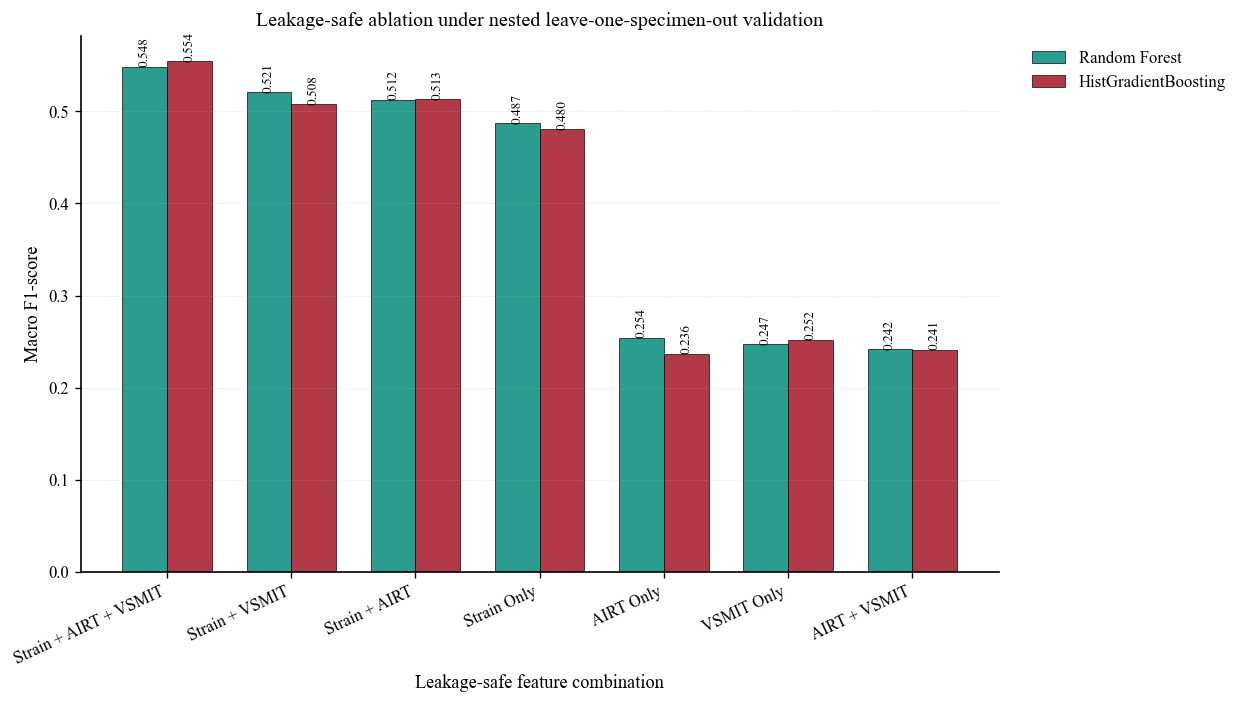

In [27]:

# ============================================================
# 25. Ablation figure
# ============================================================

ablation_plot = ablation_overall.pivot(
    index="Feature_Set",
    columns="Model",
    values="Macro_F1"
)

ablation_plot = ablation_plot.sort_values(
    by=PUBLICATION_MODELS,
    ascending=False
)

fig, ax = plt.subplots(figsize=(10.5, 6.0))

x = np.arange(len(ablation_plot.index))
width = 0.36

for position, model_name in enumerate(PUBLICATION_MODELS):
    offset = (
        position -
        (len(PUBLICATION_MODELS) - 1) / 2
    ) * width

    bars = ax.bar(
        x + offset,
        ablation_plot[model_name],
        width,
        color=MODEL_COLORS[model_name],
        edgecolor="black",
        linewidth=0.4,
        label=model_name
    )

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

ax.set_xticks(x)
ax.set_xticklabels(
    ablation_plot.index,
    rotation=25,
    ha="right"
)
ax.set_xlabel("Leakage-safe feature combination")
ax.set_ylabel("Macro F1-score")
ax.set_title(
    "Leakage-safe ablation under nested leave-one-specimen-out validation"
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.5,
    alpha=0.25
)
ax.legend(
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0)
)

fig.savefig(
    ABLATION_DIR / "ablation_macro_F1.png",
    bbox_inches="tight"
)
fig.savefig(
    ABLATION_DIR / "ablation_macro_F1.tiff",
    bbox_inches="tight"
)
plt.show()


In [28]:

# ============================================================
# 26. Threshold-sensitivity analysis
# ============================================================

def assign_stage_codes_from_ratio(
    stress_ratio,
    thresholds
):
    stable_end, elastic_end, crack_end = thresholds

    return np.select(
        [
            stress_ratio < stable_end,
            stress_ratio < elastic_end,
            stress_ratio < crack_end
        ],
        [0, 1, 2],
        default=3
    ).astype(int)


# Recalculate a specimen-wise normalized stress ratio.
threshold_data = model_data.copy()

threshold_data["Publication_Stress_Ratio"] = (
    threshold_data.groupby("Sample_ID")["Stress_MPa"]
    .transform(
        lambda series: series / max(series.max(), 1e-12)
    )
)

threshold_records = []
threshold_fold_tables = []

for scheme_name, thresholds in THRESHOLD_SCHEMES.items():
    scheme_data = threshold_data.copy()

    scheme_data["Sensitivity_Stage_Code"] = (
        assign_stage_codes_from_ratio(
            scheme_data["Publication_Stress_Ratio"].to_numpy(),
            thresholds
        )
    )

    for feature_set_name, feature_names in {
        "Full Fusion": FEATURE_SETS["Full Fusion"],
        "Leakage-Reduced Fusion": FEATURE_SETS["Leakage-Reduced Fusion"]
    }.items():
        for model_name in PUBLICATION_MODELS:
            print(
                "Threshold sensitivity:",
                scheme_name,
                "|",
                feature_set_name,
                "|",
                model_name
            )

            scheme_predictions, scheme_folds = (
                nested_logo_predictions_for_configuration(
                    scheme_data,
                    feature_names,
                    model_name,
                    target_column="Sensitivity_Stage_Code"
                )
            )

            probability_columns = [
                f"Probability_{stage}"
                for stage in STAGE_ORDER
            ]

            metrics = calculate_metrics(
                scheme_predictions["True_Code"],
                scheme_predictions["Predicted_Code"],
                scheme_predictions[probability_columns].to_numpy()
            )
            metrics.update(
                ordinal_metrics(
                    scheme_predictions["True_Code"],
                    scheme_predictions["Predicted_Code"]
                )
            )

            threshold_records.append({
                "Threshold_Scheme": scheme_name,
                "Stable_End": thresholds[0],
                "Elastic_End": thresholds[1],
                "Crack_Development_End": thresholds[2],
                "Feature_Set": feature_set_name,
                "Model": model_name,
                **metrics
            })

            scheme_folds.insert(
                0,
                "Threshold_Scheme",
                scheme_name
            )
            scheme_folds.insert(
                1,
                "Feature_Set",
                feature_set_name
            )
            threshold_fold_tables.append(
                scheme_folds
            )

threshold_sensitivity_results = pd.DataFrame(
    threshold_records
)
threshold_sensitivity_folds = pd.concat(
    threshold_fold_tables,
    ignore_index=True
)

threshold_sensitivity_results.to_excel(
    THRESHOLD_DIR /
    "threshold_sensitivity_overall_metrics.xlsx",
    index=False
)
threshold_sensitivity_folds.to_excel(
    THRESHOLD_DIR /
    "threshold_sensitivity_fold_metrics.xlsx",
    index=False
)

display(threshold_sensitivity_results)


Threshold sensitivity: Scheme_A_25_50_80 | Full Fusion | Random Forest
Threshold sensitivity: Scheme_A_25_50_80 | Full Fusion | HistGradientBoosting
Threshold sensitivity: Scheme_A_25_50_80 | Leakage-Reduced Fusion | Random Forest
Threshold sensitivity: Scheme_A_25_50_80 | Leakage-Reduced Fusion | HistGradientBoosting
Threshold sensitivity: Scheme_B_30_60_85 | Full Fusion | Random Forest
Threshold sensitivity: Scheme_B_30_60_85 | Full Fusion | HistGradientBoosting
Threshold sensitivity: Scheme_B_30_60_85 | Leakage-Reduced Fusion | Random Forest
Threshold sensitivity: Scheme_B_30_60_85 | Leakage-Reduced Fusion | HistGradientBoosting
Threshold sensitivity: Scheme_C_35_65_90 | Full Fusion | Random Forest
Threshold sensitivity: Scheme_C_35_65_90 | Full Fusion | HistGradientBoosting
Threshold sensitivity: Scheme_C_35_65_90 | Leakage-Reduced Fusion | Random Forest
Threshold sensitivity: Scheme_C_35_65_90 | Leakage-Reduced Fusion | HistGradientBoosting


,Threshold_Scheme,Stable_End,Elastic_End,Crack_Development_End,Feature_Set,Model,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall,MCC,Cohen_Kappa,Macro_ROC_AUC_OVR,Weighted_ROC_AUC_OVR,Mean_Absolute_Stage_Error,Median_Absolute_Stage_Error,Within_One_Stage_Accuracy,Exact_Stage_Accuracy,Adjacent_Error_Rate,Non_Adjacent_Error_Rate,Quadratic_Weighted_Kappa
0,Scheme_A_25_50_80,0.25,0.50,0.80,Full Fusion,Random Forest,0.663138,0.674520,0.665544,0.658727,0.659763,0.674520,0.550093,0.549208,0.888706,0.883283,0.375328,0.0,0.965284,0.663138,0.302146,0.034716,0.821028
1,Scheme_A_25_50_80,0.25,0.50,0.80,Full Fusion,HistGradientBoosting,0.672140,0.681803,0.676173,0.669208,0.671866,0.681803,0.560704,0.560369,0.881711,0.876088,0.363492,0.0,0.968118,0.672140,0.295978,0.031882,0.826740
2,Scheme_A_25_50_80,0.25,0.50,0.80,Leakage-Reduced Fusion,Random Forest,0.518525,0.522747,0.510803,0.510120,0.507521,0.522747,0.359627,0.356999,0.791032,0.788129,0.593499,0.0,0.897395,0.518525,0.378871,0.102605,0.681534
3,Scheme_A_25_50_80,0.25,0.50,0.80,Leakage-Reduced Fusion,HistGradientBoosting,0.526193,0.523683,0.514643,0.517772,0.508767,0.523683,0.364051,0.363331,0.788252,0.785095,0.583955,0.0,0.899521,0.526193,0.373328,0.100479,0.687085
4,Scheme_B_30_60_85,0.30,0.60,0.85,Full Fusion,Random Forest,0.653678,0.657735,0.651289,0.648025,0.647441,0.657735,0.538710,0.537920,0.883150,0.880993,0.387331,0.0,0.962200,0.653678,0.308523,0.037800,0.804901
5,Scheme_B_30_60_85,0.30,0.60,0.85,Full Fusion,HistGradientBoosting,0.657387,0.660818,0.656785,0.653610,0.654345,0.660818,0.543035,0.542563,0.873778,0.871258,0.379371,0.0,0.966576,0.657387,0.309189,0.033424,0.809040
6,Scheme_B_30_60_85,0.30,0.60,0.85,Leakage-Reduced Fusion,Random Forest,0.527568,0.536034,0.524518,0.519044,0.521622,0.536034,0.374101,0.371781,0.791493,0.788134,0.582871,0.0,0.898395,0.527568,0.370827,0.101605,0.673948
7,Scheme_B_30_60_85,0.30,0.60,0.85,Leakage-Reduced Fusion,HistGradientBoosting,0.534528,0.538864,0.531625,0.528549,0.527265,0.538864,0.380091,0.379383,0.788912,0.785914,0.572078,0.0,0.901188,0.534528,0.366660,0.098812,0.676891
8,Scheme_C_35_65_90,0.35,0.65,0.90,Full Fusion,Random Forest,0.638216,0.616203,0.613932,0.633925,0.613020,0.616203,0.509763,0.509318,0.872250,0.876140,0.415337,0.0,0.950865,0.638216,0.312648,0.049135,0.768594
9,Scheme_C_35_65_90,0.35,0.65,0.90,Full Fusion,HistGradientBoosting,0.640175,0.614918,0.615284,0.635893,0.617750,0.614918,0.511022,0.510631,0.862375,0.866200,0.399375,0.0,0.963367,0.640175,0.323192,0.036633,0.785059


In [29]:

# ============================================================
# 27. Leave-one-condition-out robustness tests
# ============================================================

ROBUSTNESS_COLUMN_CANDIDATES = {
    "Curing_Age": [
        "Curing_Day",
        "Curing_Days",
        "Curing_Age",
        "Age_Days"
    ],
    "CNT_Dosage": [
        "CNT_Dosage",
        "CNT_Content",
        "CNT_Percent",
        "CNT"
    ],
    "Water_Content": [
        "Water_Content",
        "Water_Content_Percent",
        "Water_Percent",
        "Moisture_Content"
    ],
    "Mix_Group": [
        "Mix_Group",
        "Group",
        "Mix_ID",
        "Material_Group"
    ]
}

available_robustness_columns = {}

for analysis_name, candidates in ROBUSTNESS_COLUMN_CANDIDATES.items():
    match = next(
        (
            column for column in candidates
            if column in model_data.columns
        ),
        None
    )

    if match is not None:
        available_robustness_columns[analysis_name] = match

print(
    "Detected robustness columns:",
    available_robustness_columns
)

robustness_records = []

for analysis_name, group_column in available_robustness_columns.items():
    condition_values = (
        model_data[group_column]
        .dropna()
        .astype(str)
        .unique()
    )

    for held_out_condition in condition_values:
        train_mask = (
            model_data[group_column].astype(str) != held_out_condition
        )
        test_mask = (
            model_data[group_column].astype(str) == held_out_condition
        )

        train_data = model_data.loc[train_mask].copy()
        test_data = model_data.loc[test_mask].copy()

        if (
            train_data["Sample_ID"].nunique() < 3 or
            test_data["Sample_ID"].nunique() < 1
        ):
            continue

        for feature_set_name, feature_names in {
            "Full Fusion": FEATURE_SETS["Full Fusion"],
            "Leakage-Reduced Fusion": FEATURE_SETS["Leakage-Reduced Fusion"]
        }.items():
            for model_name in PUBLICATION_MODELS:
                model_spec = MODEL_SPECS[model_name]

                inner_groups = train_data["Sample_ID"].astype(str).to_numpy()
                inner_splits = min(
                    INNER_GROUP_FOLDS,
                    train_data["Sample_ID"].nunique()
                )

                search = GridSearchCV(
                    estimator=clone(model_spec["pipeline"]),
                    param_grid=model_spec["param_grid"],
                    scoring="f1_macro",
                    cv=GroupKFold(
                        n_splits=max(2, inner_splits)
                    ),
                    n_jobs=N_JOBS,
                    refit=True,
                    error_score="raise"
                )

                search.fit(
                    train_data[feature_names],
                    train_data["Failure_Stage_Code"],
                    groups=inner_groups
                )

                estimator = search.best_estimator_
                y_true = test_data["Failure_Stage_Code"].to_numpy()
                y_pred = estimator.predict(
                    test_data[feature_names]
                )

                if hasattr(estimator, "predict_proba"):
                    raw_probability = estimator.predict_proba(
                        test_data[feature_names]
                    )
                    probabilities = np.zeros(
                        (len(test_data), len(STAGE_CODES))
                    )

                    for local_index, class_code in enumerate(
                        estimator.classes_.astype(int)
                    ):
                        probabilities[:, class_code] = (
                            raw_probability[:, local_index]
                        )
                else:
                    probabilities = None

                metrics = calculate_metrics(
                    y_true,
                    y_pred,
                    probabilities
                )
                metrics.update(
                    ordinal_metrics(
                        y_true,
                        y_pred
                    )
                )

                robustness_records.append({
                    "Robustness_Test": analysis_name,
                    "Grouping_Column": group_column,
                    "Held_Out_Condition": held_out_condition,
                    "Train_Specimens": train_data["Sample_ID"].nunique(),
                    "Test_Specimens": test_data["Sample_ID"].nunique(),
                    "Feature_Set": feature_set_name,
                    "Model": model_name,
                    **metrics
                })

robustness_results = pd.DataFrame(
    robustness_records
)

if not robustness_results.empty:
    robustness_results.to_excel(
        ROBUSTNESS_DIR /
        "leave_one_condition_out_results.xlsx",
        index=False
    )
    display(robustness_results)
else:
    print(
        "No condition columns were present in model_data. "
        "Merge specimen metadata into the labelled master dataset "
        "to run curing-age, CNT-dosage, water-content, or mix-group robustness."
    )


Detected robustness columns: {'Curing_Age': 'Curing_Day'}


,Robustness_Test,Grouping_Column,Held_Out_Condition,Train_Specimens,Test_Specimens,Feature_Set,Model,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1,Macro_Precision,Macro_Recall,MCC,Cohen_Kappa,Macro_ROC_AUC_OVR,Weighted_ROC_AUC_OVR,Mean_Absolute_Stage_Error,Median_Absolute_Stage_Error,Within_One_Stage_Accuracy,Exact_Stage_Accuracy,Adjacent_Error_Rate,Non_Adjacent_Error_Rate,Quadratic_Weighted_Kappa
0,Curing_Age,Curing_Day,3.0,76,4,Full Fusion,Random Forest,0.755000,0.755000,0.754372,0.754372,0.762614,0.755000,0.676211,0.673333,0.936347,0.936347,0.254167,0.0,0.990833,0.755000,0.235833,0.009167,0.895327
1,Curing_Age,Curing_Day,3.0,76,4,Full Fusion,HistGradientBoosting,0.801667,0.801667,0.799938,0.799938,0.806665,0.801667,0.738456,0.735556,0.958980,0.958980,0.202500,0.0,0.995833,0.801667,0.194167,0.004167,0.918702
2,Curing_Age,Curing_Day,3.0,76,4,Leakage-Reduced Fusion,Random Forest,0.614167,0.614167,0.604333,0.604333,0.615651,0.614167,0.492098,0.485556,0.853804,0.853804,0.433333,0.0,0.952500,0.614167,0.338333,0.047500,0.802738
3,Curing_Age,Curing_Day,3.0,76,4,Leakage-Reduced Fusion,HistGradientBoosting,0.598333,0.598333,0.578638,0.578638,0.588293,0.598333,0.473051,0.464444,0.867673,0.867673,0.418333,0.0,0.983333,0.598333,0.385000,0.016667,0.837041
4,Curing_Age,Curing_Day,14.0,76,4,Full Fusion,Random Forest,0.615833,0.615833,0.605108,0.605108,0.607110,0.615833,0.491454,0.487778,0.878163,0.878163,0.470000,0.0,0.915000,0.615833,0.299167,0.085000,0.757080
5,Curing_Age,Curing_Day,14.0,76,4,Full Fusion,HistGradientBoosting,0.624167,0.624167,0.613085,0.613085,0.632391,0.624167,0.505552,0.498889,0.840851,0.840851,0.458333,0.0,0.917500,0.624167,0.293333,0.082500,0.762690
6,Curing_Age,Curing_Day,14.0,76,4,Leakage-Reduced Fusion,Random Forest,0.611667,0.611667,0.604322,0.604322,0.629404,0.611667,0.493320,0.482222,0.835868,0.835868,0.448333,0.0,0.940000,0.611667,0.328333,0.060000,0.767553
7,Curing_Age,Curing_Day,14.0,76,4,Leakage-Reduced Fusion,HistGradientBoosting,0.549167,0.549167,0.539150,0.539150,0.559421,0.549167,0.405862,0.398889,0.817787,0.817787,0.515000,0.0,0.935833,0.549167,0.386667,0.064167,0.744878
8,Curing_Age,Curing_Day,28.0,76,4,Full Fusion,Random Forest,0.595833,0.595833,0.551464,0.551464,0.579478,0.595833,0.484431,0.461111,0.859907,0.859907,0.469167,0.0,0.935000,0.595833,0.339167,0.065000,0.798712
9,Curing_Age,Curing_Day,28.0,76,4,Full Fusion,HistGradientBoosting,0.605000,0.605000,0.564715,0.564715,0.599613,0.605000,0.499685,0.473333,0.878098,0.878098,0.437500,0.0,0.957500,0.605000,0.352500,0.042500,0.824271


In [30]:

# ============================================================
# 28. Publication summary workbook
# ============================================================

publication_workbook = (
    PUBLICATION_DIR /
    "publication_ready_model_results.xlsx"
)

with pd.ExcelWriter(
    publication_workbook,
    engine="openpyxl"
) as writer:
    overall_metrics.to_excel(
        writer,
        sheet_name="Main_Model_Comparison",
        index=False
    )
    classification_report_table.to_excel(
        writer,
        sheet_name="Class_Performance",
        index=False
    )
    ordinal_results.to_excel(
        writer,
        sheet_name="Ordinal_Metrics",
        index=False
    )
    transition_results.to_excel(
        writer,
        sheet_name="Transition_Errors",
        index=False
    )
    bootstrap_ci_summary.to_excel(
        writer,
        sheet_name="Bootstrap_95CI",
        index=False
    )
    paired_model_tests.to_excel(
        writer,
        sheet_name="Paired_Model_Tests",
        index=False
    )
    ablation_overall.to_excel(
        writer,
        sheet_name="Ablation_Results",
        index=False
    )
    threshold_sensitivity_results.to_excel(
        writer,
        sheet_name="Threshold_Sensitivity",
        index=False
    )

    if not robustness_results.empty:
        robustness_results.to_excel(
            writer,
            sheet_name="Robustness_Tests",
            index=False
        )

print(
    "Publication-ready workbook saved:",
    publication_workbook
)


Publication-ready workbook saved: C:\Users\Eddie\Desktop\new_exp_june\Project_Dir\modeling_outputs_LOGO_RF_pub\publication_strengthening\publication_ready_model_results.xlsx


## Outputs for reporting

```text
modeling_outputs_LOGO_RF/
├── LOGO_modeling_results_with_RF_ROC_AUC.xlsx
├── figures/
│   ├── model comparison
│   ├── Macro F1 comparison
│   ├── confusion matrices
│   ├── multiclass ROC curves
│   ├── AUC comparison
│   ├── fold-level F1 distributions
│   ├── feature importance
│   ├── tuning frequency
│   └── runtime comparison
├── tables/
│   ├── LOGO_overall_model_metrics.csv
│   ├── LOGO_fold_metrics.csv
│   ├── classification_reports.csv
│   └── LOGO_train_test_split_audit.csv
├── hyperparameter_tuning/
├── feature_importance/
├── predictions/
└── saved_models/
```

The `LOGO_train_test_split_audit.csv` file documents the held-out specimen and train/test row counts for every model, feature set, and outer fold.
